# An appraisal of the viability of transfer learning for refining deep learning models in production - Implementation
*** 
**NOTE**
1. Sometimes the notebook kernel can show a buffer error or assertion error (or any other error that causes the output to not appear). In these cases, interrupt the kernel and reconnect to it.
2. Due to the stochastic nature of the operation of ANNs, the exact numerical values displayed will differ when re-executing the experiment. While effort has been made to reduce this randomness and only general inferences have been made, the exact magnitude of observations are subject to change; therefore treat the final answers with appropriate discretion.
3. Despite the innate randomness, the general observations made about the model performances remain concrete.
4. The same model hyperparameters used for the control model, are used for the other models (the base model and the TL models). While this may not be this most optimal approach and can lead to certain biases towards in the control model in the results, this approach is easier to implement as a starter model performance comparison condition.
***

## Importing required libraries

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')
import seaborn as sns
from sklearn.model_selection import train_test_split
from fast_ml.model_development import train_valid_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Subset
from torchinfo import summary
from sklearn.metrics import mean_absolute_error, r2_score
import copy
import torch.onnx
import netron
import json
import os
from tabulate import tabulate

## Pre-processing and visualizing the datasets 

In [3]:
# since column 0 contains both text and number data and supress the warning, the low memory is set to False
actualData = pd.read_csv('Mubea_Actual_Process.csv', low_memory=False)
print(actualData.head())
print(actualData.info())

  ProductID  OrderNo  CoilID  ProfileNo  Duration  WorkRollHardChromed   
0    FH0419  2782397      53          1      1.94                    0  \
1    FH0419  2782397      53          1      1.94                    0   
2    FH0419  2782397      53          2      1.94                    0   
3    FH0419  2782397      53          2      1.94                    0   
4    FH0419  2782397      53          3      1.94                    0   

   IsCoated  WorkRollCrowning  WorkRollChromiumContent  WorkRollUsageCount   
0         1               0.2                        8                  36  \
1         1               0.2                        8                  36   
2         1               0.2                        8                  36   
3         1               0.2                        8                  36   
4         1               0.2                        8                  36   

   ...  TRK_MillSpeedAct  TRK_RolledLength   
0  ...          0.505274         2601.39

In [4]:
simulData = pd.read_csv('Mubea_Simulation.csv', low_memory=False)
print(simulData.head())
print(simulData.info())

  ProductID  OrderNo  CoilID  ProfileNo  Duration  WorkRollHardChromed   
0  90124129  2781352      54          1      2.68                    0  \
1  90124129  2781352      54          1      2.68                    0   
2  90124129  2781352      54          1      2.68                    0   
3  90124129  2781352      54          1      2.68                    0   
4  90124129  2781352      54          1      2.68                    0   

   IsCoated  WorkRollCrowning  WorkRollChromiumContent  WorkRollUsageCount   
0         1               0.2                        8                  22  \
1         1               0.2                        8                  22   
2         1               0.2                        8                  22   
3         1               0.2                        8                  22   
4         1               0.2                        8                  22   

   ...  TRK_MillSpeedAct  TRK_RolledLength   
0  ...          0.422075         2573.22

In [5]:
# Total number of unique products in the actual dataset
actPL = actualData['ProductID'].unique()
print(actPL)
print("\n",len(actPL), "actual products")

['FH0419' '90232473' '90230042' '90216522' '90233627' '90220613'
 '90217189' '90253412' '90232336' '90232405' '90030668' '90155014'
 '90234813' '90192470' '90234573' '90198105' '90116674' '90230667'
 '90234584' '90190110' '90203338' '90153635' '90157585' '90115506'
 '90232469']

 25 actual products


In [6]:
# Total number of unique products in the simulated dataset
simPL = simulData['ProductID'].unique()
print(simPL)
print("\n",len(simPL), "simulated products")

['90124129' '90230501' '90234395' '90226335' '90232693' '90232333'
 '90154353' '90257486' '90015518' '90192691' '90233278' '90230973'
 '90232730' '90232463' '90194281' '90024973' '90257904' 'FH0427' 'FH0376'
 '90154355' '90146739' 'FH0386' '90233575' '90117219' '90155663'
 '90254000' '90230503' '90189826' '90232186' '90190117' '90232376'
 '90140132' '90232400' '90248414' '90232006' '90232331' '90032770'
 '90105072' '90032597' '90190124' '90259755' '90254656' 'FH0443'
 '90268727' '90210123' '91901206' '90284821' '90232073' 'FH0415'
 '90254030' '90254184' '90202984' '90248107' '90248113' '90232539'
 '90185338' '91901210' '90253197' '90155826' '90232540']

 60 simulated products


In [7]:
# To view common products in both datasets
commonPL = list(set(simPL).intersection(set(actPL)))
print(commonPL)
print("\n",len(commonPL), "common products")

[]

 0 common products


In [8]:
# Dropping the unrelated coulmns from actual and simulated datasets since the first 13 columns are common to both the datasets
print("Before droppping")
print(simulData.shape)
print(actualData.shape,"\n")
columns_to_drop = simulData.columns[:13]
simulData_clean = simulData.drop(columns_to_drop, axis=1)
actualData_clean = actualData.drop(columns_to_drop, axis=1)
print("After dropping")
print(simulData_clean.shape)
print(actualData_clean.shape)

Before droppping
(175157, 100)
(96992, 100) 

After dropping
(175157, 87)
(96992, 87)


In [9]:
# To view summary statistics of products in the actual dataset
actualData_SummStat = actualData_clean.describe().T
actualData_SummStat

,count,mean,std,min,25%,50%,75%,max
MeanIngoingThicknessInMu,96992.0,3037.335699,1771.310940,193.589800,1716.092300,1954.923450,5997.509000,6002.309600
OutgoingThickness,96992.0,1574.392519,412.024346,774.141050,1302.340775,1406.364300,1622.373075,3070.330600
AIN_RFC_AnnulusPressureDriveSide,96992.0,7.485660,2.602159,0.600000,5.660132,7.655442,9.177774,15.427927
AIN_RFC_AnnulusPressureNonDriveSide,96992.0,9.828518,2.606056,0.707840,8.278425,9.710797,11.587368,17.149664
AIN_RFC_FullborePressureDriveSide,96992.0,9.611517,1.519951,4.690719,8.626859,9.643859,10.487823,17.427385
...,...,...,...,...,...,...,...,...
WRB_AOUT_Command_Servo_Exit_NonDriveSide,96992.0,0.046072,0.017904,-0.152944,0.034241,0.046636,0.059123,0.302246
WRB_ForceNegative,96992.0,305.553698,169.590678,47.616160,143.834140,300.071455,434.611490,684.315300
WRB_ForceNet,96992.0,171.674848,333.299179,-595.510000,-77.858968,189.665895,486.024880,610.141050
WRB_ForcePositive,96992.0,477.228142,164.387733,70.086970,356.736865,489.121400,635.095960,699.886700


In [10]:
# To view summary statistics of products in the simulated dataset
simulData_SummStat = simulData_clean.describe().T
simulData_SummStat

,count,mean,std,min,25%,50%,75%,max
MeanIngoingThicknessInMu,175157.0,3064.251177,1684.384606,125.113235,1791.894700,2302.699000,3084.786100,6002.690000
OutgoingThickness,175157.0,1679.997832,430.084955,454.703250,1442.917400,1651.524200,2019.863400,2995.806200
AIN_RFC_AnnulusPressureDriveSide,175157.0,7.083777,3.198200,0.600000,4.713132,6.910138,9.112630,17.141033
AIN_RFC_AnnulusPressureNonDriveSide,175157.0,9.236107,3.121021,1.020605,7.030235,8.867640,11.444520,18.546394
AIN_RFC_FullborePressureDriveSide,175157.0,10.428438,1.971002,3.649078,9.243704,10.468876,11.693686,17.535398
...,...,...,...,...,...,...,...,...
WRB_AOUT_Command_Servo_Exit_NonDriveSide,175157.0,0.039129,0.020941,-0.180911,0.026737,0.038632,0.051615,0.273251
WRB_ForceNegative,175157.0,376.560306,174.592250,48.627308,228.140720,391.173300,523.326000,681.160460
WRB_ForceNet,175157.0,28.821473,349.334321,-600.338400,-262.193880,7.948897,331.966250,607.566650
WRB_ForcePositive,175157.0,405.381758,175.518432,38.373030,263.549040,399.812300,560.798200,698.951700


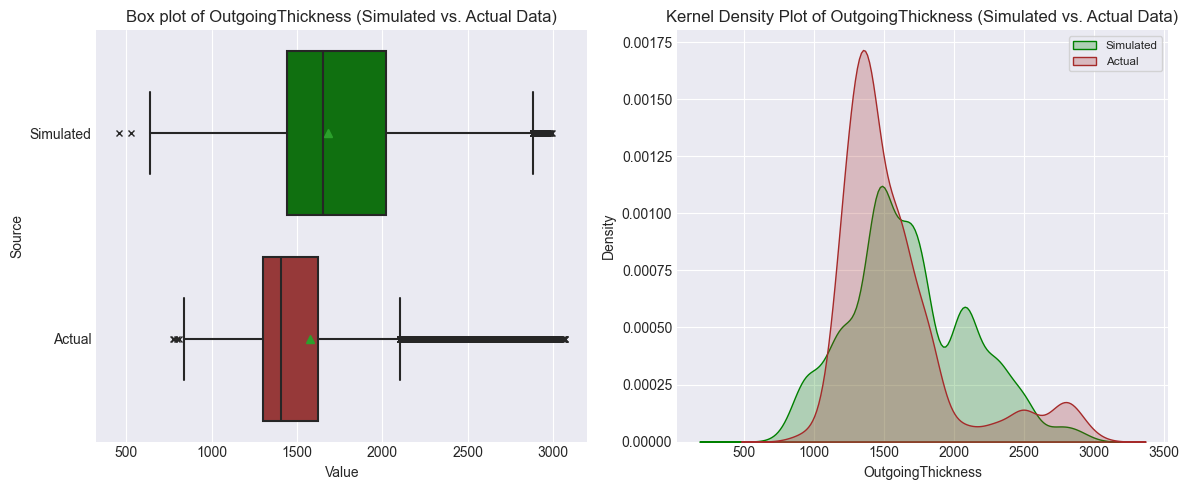

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# To view the box plot of the feature to be predicted in both the simulation and the actual datasets
simul_data = simulData_clean['OutgoingThickness'].copy().to_frame()
simul_data['Source'] = 'Simulated'
actual_data = actualData_clean['OutgoingThickness'].copy().to_frame()
actual_data['Source'] = 'Actual'
combined_data = pd.concat([simul_data, actual_data])
# Box plot
colours = {'Simulated': 'green', 'Actual': 'brown'}
sns.boxplot(x='OutgoingThickness', y='Source', data=combined_data, showmeans=True, palette=colours, flierprops={"marker": "x"}, ax=axes[0])
axes[0].set_title('Box plot of OutgoingThickness (Simulated vs. Actual Data)')
axes[0].set_xlabel('Value')
# To view the KDE plot of the feature to be predicted in both the simulation and the actual datasets
# Increase or decrease bw_adjust parameter to control smoothing
sns.kdeplot(simulData_clean['OutgoingThickness'], label='Simulated', fill=True, common_norm=True, bw_adjust=2.4, color='green', ax=axes[1])
sns.kdeplot(actualData_clean['OutgoingThickness'], label='Actual', fill=True, common_norm=True, bw_adjust=2.4, color='brown', ax=axes[1])
axes[1].set_title('Kernel Density Plot of OutgoingThickness (Simulated vs. Actual Data)')
axes[1].set_xlabel('OutgoingThickness')
axes[1].set_ylabel('Density')
axes[1].legend(frameon=True, fontsize='small')


plt.tight_layout()
plt.show()

From the box plot and the kernel density estimate (KDE) plot, the presence of outliers in the feature `OutgoingThickness` can be observed (especially in the actual data; indicated by the 'x' in the box plot and the extreme tails of the KDE plots). However, operating under the assumption that the dataset was already pre-processed to take care of extreme outliers, we will not be dealing with the outliers with any of the features in this case. Furthermore, the large number of outliers indicated in the actual data could imply that the outliers might be statistically significant; contrary to popular outlier beliefs.
<br><br>
Upon observing the KDE plot, we can observe that the `OutgoingThickness` of the simulated data is fairly normally distributed (with the mean being close to the median as indicated in the box plot). The `OutgoingThickness` of the actual data is moderately right (positively) skewed (with the mean being greater than the median as indicated in the box plot and the tail of the actual data's KDE plot being on the right).
<br><br>
Additionally, we can also observe that the probability distributions of the `OutgoingThickness` of the simulated and actual data are close to each other (as indicated through the majority overlapping between the 2 plots).

In [12]:
# Creating a heatmap function
def Data_HeatMap(corr_matrix, flag):
    plt.figure(figsize=(22,18))
    # Generate a custom diverging colormap
    cmap = sns.color_palette("coolwarm_r", as_cmap=True)
    # To generate a mask to hide the upper repeated traingle of the matrix. 
    mask = np.triu(np.ones_like(corr_matrix))
    # To show the main diagonal.
    np.fill_diagonal(mask, True)
    sns.heatmap(corr_matrix, annot = False, cmap = cmap, mask = mask, linewidth = 0.8, linecolor = plt.gca().get_facecolor())
    if flag == 's':
        plt.title('Heatmap of Simulated Data', fontsize='x-large', pad = 10)
    elif flag == 'a':
        plt.title('Heatmap of Actual Data', fontsize = 'x-large', pad = 10)
    plt.grid(False)
    plt.show()

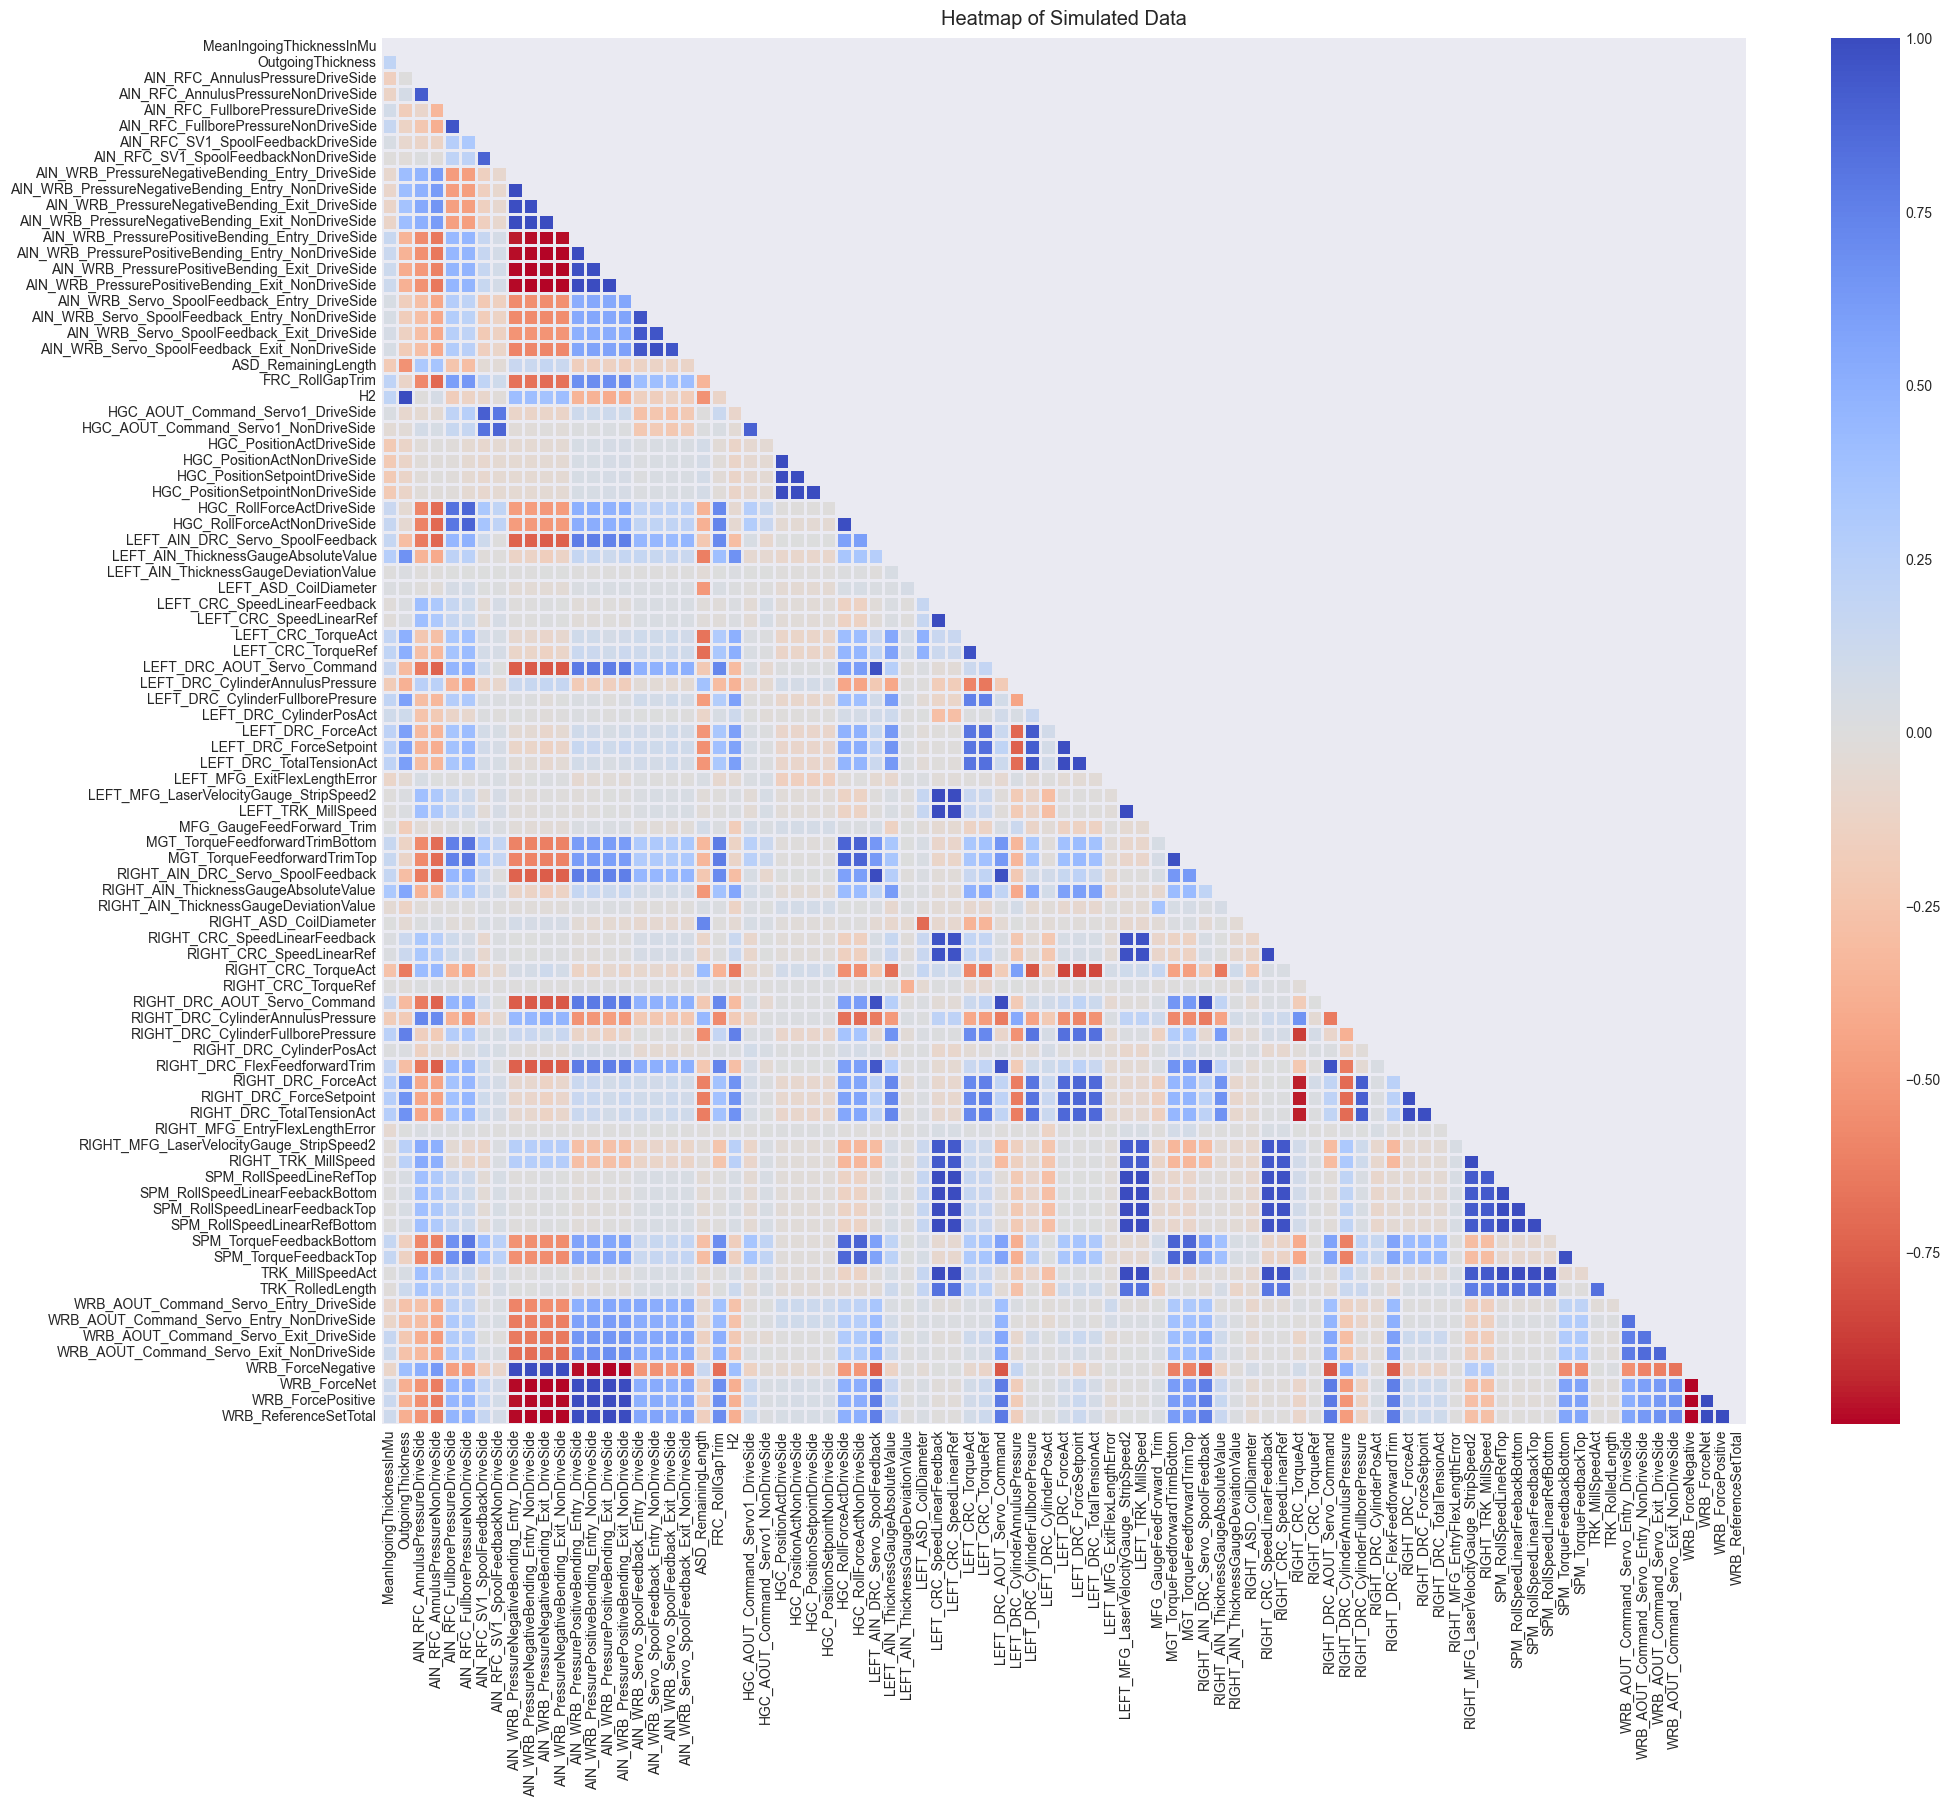

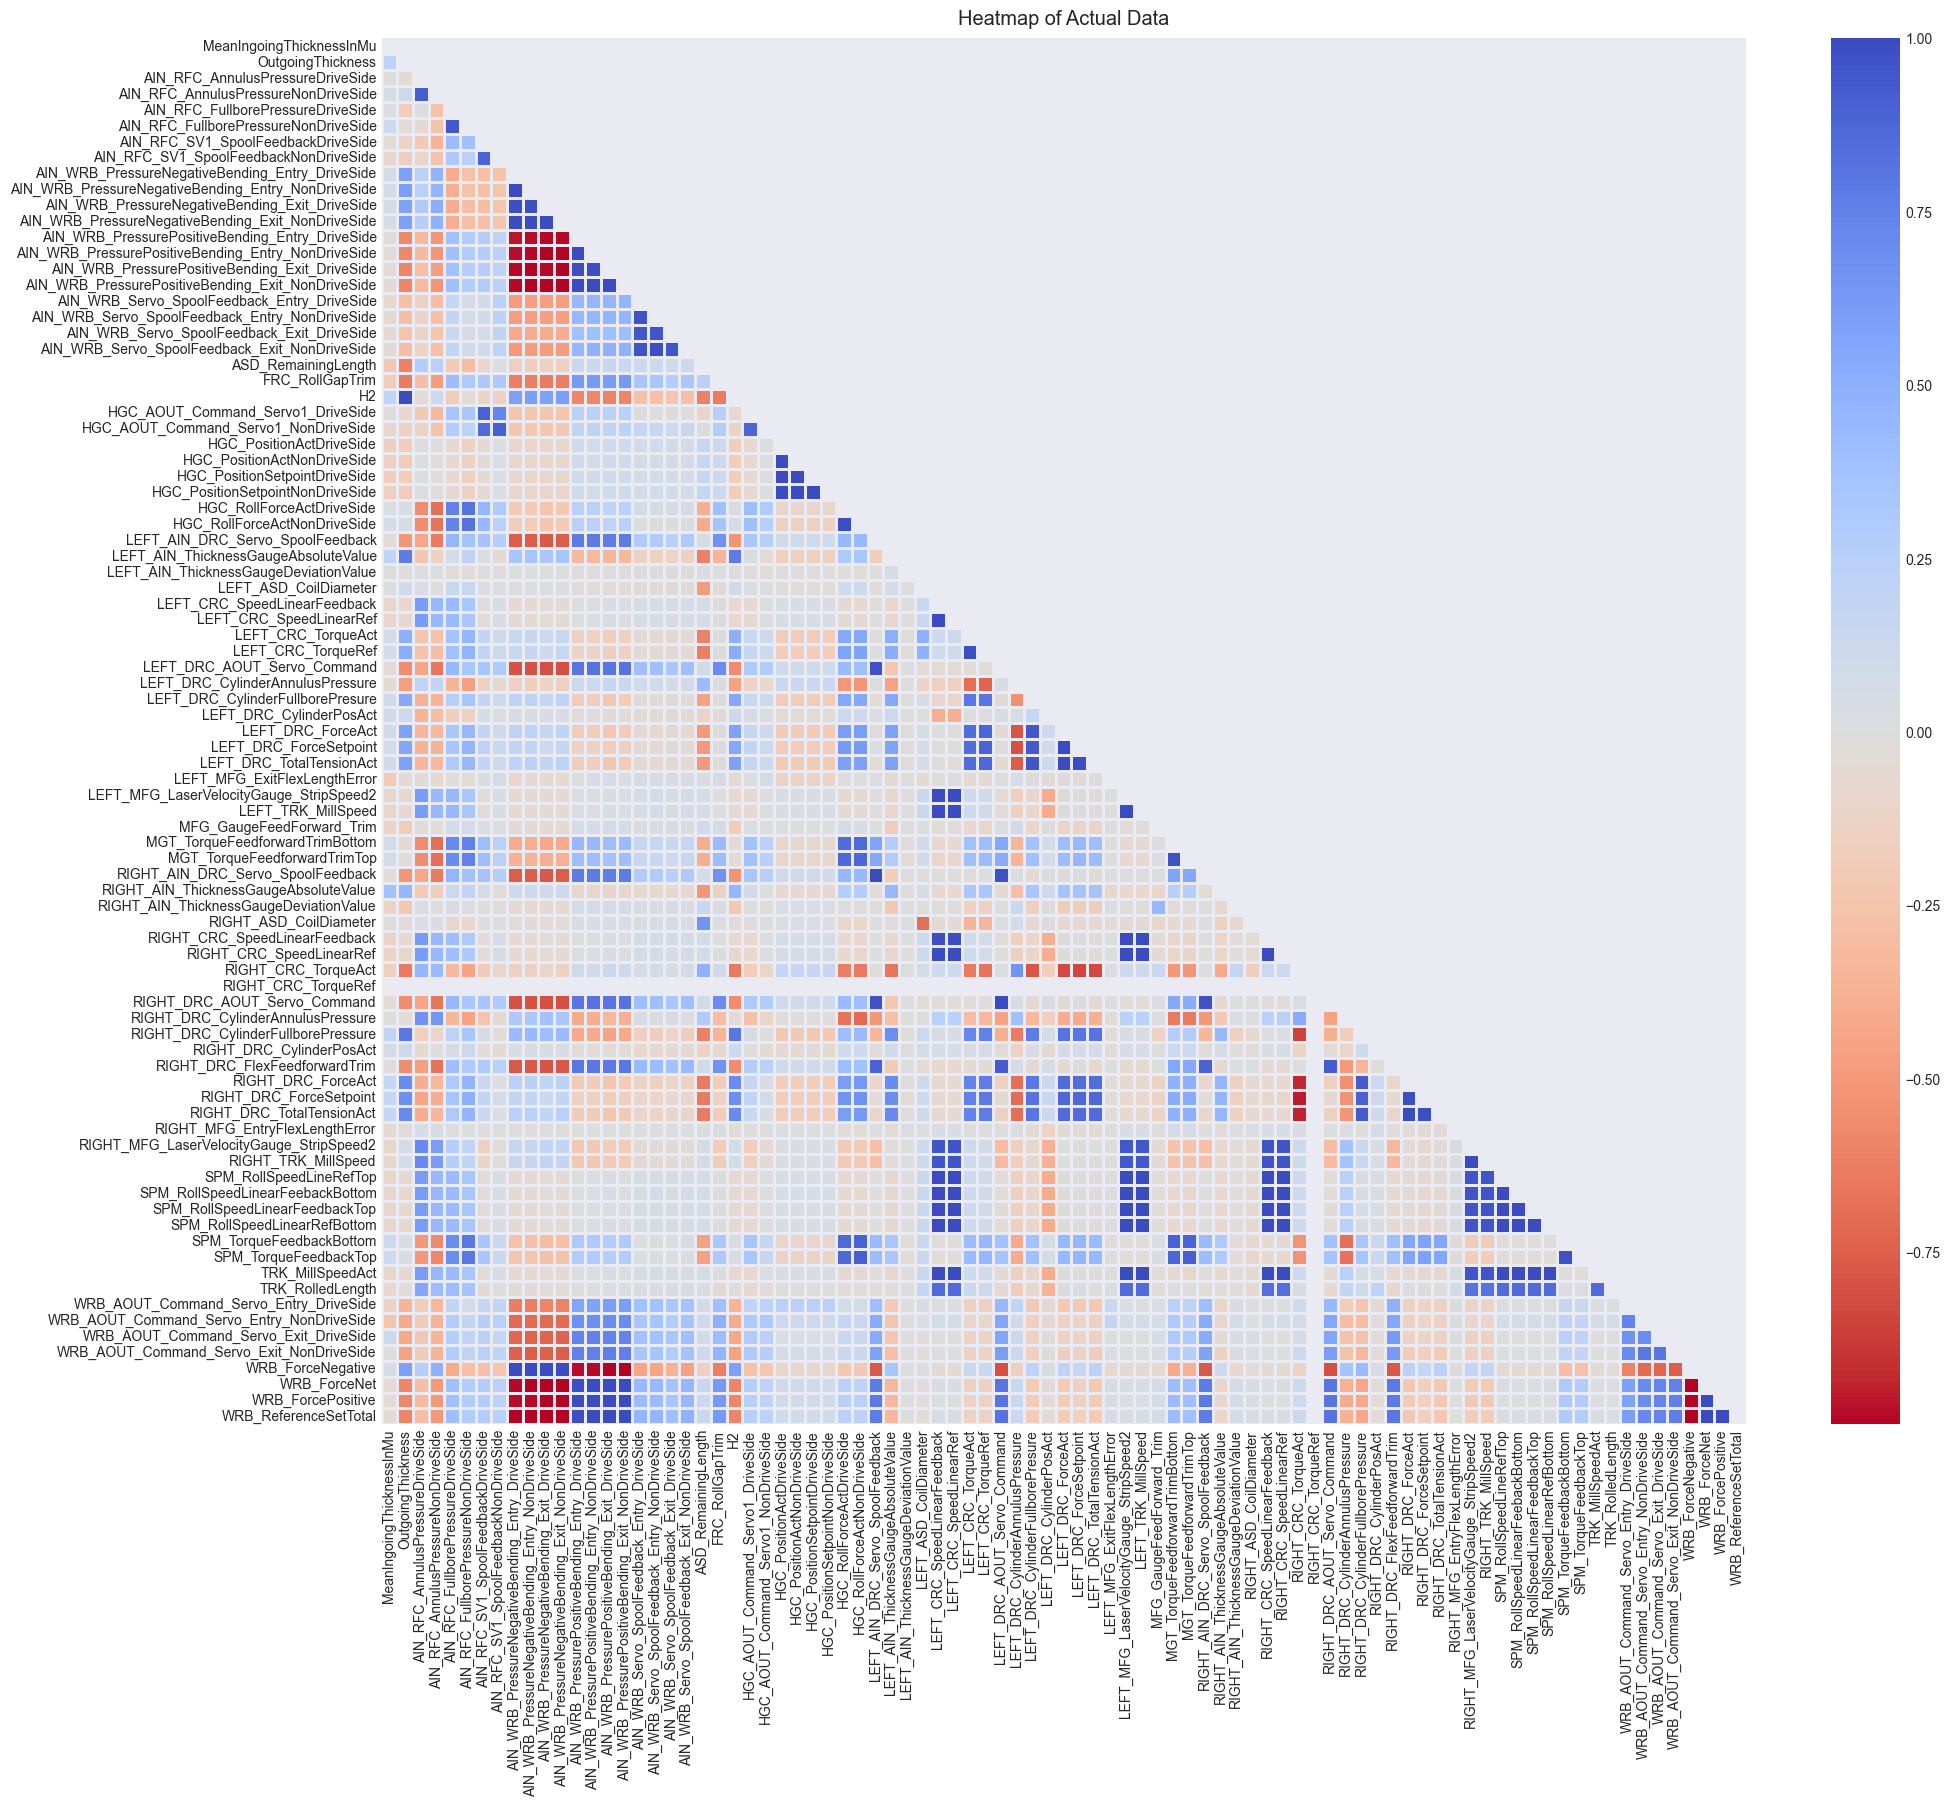

In [13]:
simul_corr_matrix = simulData_clean.corr()
actual_corr_matrix = actualData_clean.corr()
# Heatmap of the simulated data
Data_HeatMap(simul_corr_matrix, 's')
# Heatmap of the actual data
Data_HeatMap(actual_corr_matrix, 'a')

In [14]:
# Viewing the distributions of the correlations of the actual and simulated dataset to identify positive and 
# neagtive correlation thresholds
def corr_ThreshHist(corr_matrixAct, corr_matrixSim, upperThresh, lowerThresh):
    # To get upper diagonal elements
    uppTri_Act = np.tril(corr_matrixAct, k = 1)
    uppTri_Sim = np.tril(corr_matrixSim, k = 1)
    Act_corr = uppTri_Act.flatten()
    Sim_corr = uppTri_Sim.flatten()
    # To remove the digonal elements which were zeros
    nonzero_Act_corr = Act_corr[Act_corr != 0]
    nonzero_Sim_corr = Sim_corr[Sim_corr != 0]
    sns.histplot(nonzero_Sim_corr, color = 'green', label = 'Simulation correlation', element="step", fill=True, stat="percent", alpha=0.3)
    sns.histplot(nonzero_Act_corr, color = 'brown', label = 'Actual correlation', element="step", fill=True, stat="percent", alpha=0.3)
    plt.xlabel('Data Correlation Coefficients')
    plt.ylabel('Percentage of observations')
    plt.title('Histogram of Actual and Simulated Correlation Coefficients')
    plt.axvline(x=upperThresh, color='blue', linestyle='-.', label="Positive threshold")
    plt.axvline(x=lowerThresh, color='red', linestyle='-.', label="Negative threshold")
    plt.legend(frameon=True, fontsize='small', loc='upper right')
    plt.show()

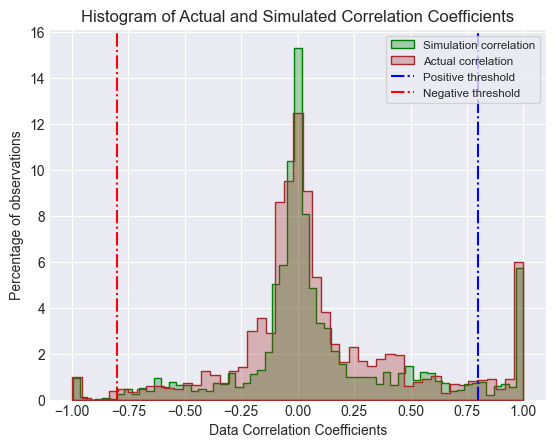

In [15]:
strng_PosThresh = 0.8
strng_NegThresh = -0.8
corr_ThreshHist(actual_corr_matrix, simul_corr_matrix, strng_PosThresh, strng_NegThresh)

In [16]:
def strongCorr_Finder(posThresh, negThresh, corrMtrx_Act, corrMtrx_Sim):
    strong_corrDict = {
    'Pos_Sim': {'Feature 1': [], 'Feature 2': [], 'Coeff': []},
    'Neg_Sim': {'Feature 1': [], 'Feature 2': [], 'Coeff': []},
    'Pos_Act': {'Feature 1': [], 'Feature 2': [], 'Coeff': []},
    'Neg_Act': {'Feature 1': [], 'Feature 2': [], 'Coeff': []}
    }
    # Simulated data correlations
    for col in corrMtrx_Sim.columns:
        for row in corrMtrx_Sim.index:
            # Diagonal elements
            if row == col:
                continue
            sim_corr = corrMtrx_Sim.loc[row, col]
            # To prevent repeating features
            if sim_corr >= posThresh and (row not in strong_corrDict['Pos_Sim']['Feature 2'] and col not in strong_corrDict['Pos_Sim']['Feature 1']):
                    strong_corrDict['Pos_Sim']['Feature 1'].append(row)
                    strong_corrDict['Pos_Sim']['Feature 2'].append(col)
                    strong_corrDict['Pos_Sim']['Coeff'].append(round(sim_corr, 2))
            elif sim_corr <= negThresh and (row not in strong_corrDict['Neg_Sim']['Feature 2'] and col not in strong_corrDict['Neg_Sim']['Feature 1']):
                    strong_corrDict['Neg_Sim']['Feature 1'].append(row)
                    strong_corrDict['Neg_Sim']['Feature 2'].append(col)
                    strong_corrDict['Neg_Sim']['Coeff'].append(round(sim_corr, 2))
    # Actual data correlations
    for col in corrMtrx_Act.columns:
        for row in corrMtrx_Act.index:
            # Diagonal elements
            if row == col:
                continue
            act_corr = corrMtrx_Act.loc[row, col]
            # To prevent repeating features
            if act_corr >= posThresh and (row not in strong_corrDict['Pos_Act']['Feature 2'] and col not in strong_corrDict['Pos_Act']['Feature 1']):
                    strong_corrDict['Pos_Act']['Feature 1'].append(row)
                    strong_corrDict['Pos_Act']['Feature 2'].append(col)
                    strong_corrDict['Pos_Act']['Coeff'].append(round(act_corr, 2))
            elif act_corr <= negThresh and (row not in strong_corrDict['Neg_Act']['Feature 2'] and col not in strong_corrDict['Neg_Act']['Feature 1']):
                    strong_corrDict['Neg_Act']['Feature 1'].append(row)
                    strong_corrDict['Neg_Act']['Feature 2'].append(col)
                    strong_corrDict['Neg_Act']['Coeff'].append(round(act_corr, 2))
    
    return strong_corrDict['Pos_Sim'], strong_corrDict['Neg_Sim'],  strong_corrDict['Pos_Act'], strong_corrDict['Neg_Act']

In [17]:
SimDict_posCorr, SimDict_negCorr, ActDict_posCorr, ActDict_negCorr = strongCorr_Finder(strng_PosThresh, strng_NegThresh, actual_corr_matrix, simul_corr_matrix)
print('-'*26, "Strong positive correlations for simulated data ("+ str(len(SimDict_posCorr['Feature 1']))+" entries)", '-'*26)
print(tabulate(SimDict_posCorr, headers='keys', tablefmt="rounded_grid"))
print()
print('-'*26, "Strong negative correlations for simulated data ("+ str(len(SimDict_negCorr['Feature 1']))+" entries)", '-'*26)
print(tabulate(SimDict_negCorr, headers='keys', tablefmt="rounded_grid"))

-------------------------- Strong positive correlations for simulated data (61 entries) --------------------------
╭────────────────────────────────────────────────────┬─────────────────────────────────────────────────┬─────────╮
│ Feature 1                                          │ Feature 2                                       │   Coeff │
├────────────────────────────────────────────────────┼─────────────────────────────────────────────────┼─────────┤
│ H2                                                 │ OutgoingThickness                               │    1    │
├────────────────────────────────────────────────────┼─────────────────────────────────────────────────┼─────────┤
│ AIN_RFC_AnnulusPressureNonDriveSide                │ AIN_RFC_AnnulusPressureDriveSide                │    0.93 │
├────────────────────────────────────────────────────┼─────────────────────────────────────────────────┼─────────┤
│ AIN_RFC_FullborePressureNonDriveSide               │ AIN_RFC_FullborePressureD

In [18]:
print('-'*26, "Strong positive correlations for actual data ("+ str(len(ActDict_posCorr['Feature 1']))+" entries)", '-'*26)
print(tabulate(ActDict_posCorr, headers='keys', tablefmt="rounded_grid"))
print()
print('-'*26, "Strong negative correlations for actual data ("+ str(len(ActDict_negCorr['Feature 1']))+" entries)", '-'*26)
print(tabulate(ActDict_negCorr, headers='keys', tablefmt="rounded_grid"))

-------------------------- Strong positive correlations for actual data (60 entries) --------------------------
╭────────────────────────────────────────────────────┬─────────────────────────────────────────────────┬─────────╮
│ Feature 1                                          │ Feature 2                                       │   Coeff │
├────────────────────────────────────────────────────┼─────────────────────────────────────────────────┼─────────┤
│ H2                                                 │ OutgoingThickness                               │    1    │
├────────────────────────────────────────────────────┼─────────────────────────────────────────────────┼─────────┤
│ RIGHT_DRC_CylinderFullborePressure                 │ OutgoingThickness                               │    0.8  │
├────────────────────────────────────────────────────┼─────────────────────────────────────────────────┼─────────┤
│ AIN_RFC_AnnulusPressureNonDriveSide                │ AIN_RFC_AnnulusPressureDrive

In [19]:
commPosCorr_SimAct_set = set(zip(SimDict_posCorr['Feature 1'], SimDict_posCorr['Feature 2'])).intersection(set(zip(ActDict_posCorr['Feature 1'], ActDict_posCorr['Feature 2'])))
commNegCorr_SimAct_set = set(zip(SimDict_negCorr['Feature 1'], SimDict_negCorr['Feature 2'])).intersection(set(zip(ActDict_negCorr['Feature 1'], ActDict_negCorr['Feature 2'])))
print(f"{len(commPosCorr_SimAct_set)} common positive correlation pairs between the simulation and actual data.")
print(tabulate(commPosCorr_SimAct_set, headers=("Feature 1", "Feature 2"), tablefmt="outline"))
print()
print(f"{len(commNegCorr_SimAct_set)} common negative correlation pairs between the simulation and actual data.")
print(tabulate(commNegCorr_SimAct_set, headers=("Feature 1", "Feature 2"), tablefmt="outline"))

44 common positive correlation pairs between the simulation and actual data.
+----------------------------------------------------+-------------------------------------------------+
| Feature 1                                          | Feature 2                                       |
+====================================================+=================================================+
| AIN_WRB_PressurePositiveBending_Exit_DriveSide     | AIN_WRB_PressurePositiveBending_Entry_DriveSide |
| AIN_WRB_Servo_SpoolFeedback_Entry_NonDriveSide     | AIN_WRB_Servo_SpoolFeedback_Entry_DriveSide     |
| RIGHT_DRC_AOUT_Servo_Command                       | LEFT_AIN_DRC_Servo_SpoolFeedback                |
| AIN_WRB_Servo_SpoolFeedback_Exit_NonDriveSide      | AIN_WRB_Servo_SpoolFeedback_Entry_DriveSide     |
| LEFT_DRC_ForceAct                                  | LEFT_CRC_TorqueAct                              |
| RIGHT_DRC_FlexFeedforwardTrim                      | LEFT_AIN_DRC_Servo_SpoolFeed

The 2 heat maps plotted above illustrate the degree of the relationship between the regressors and the outcome to be predicted (`OutgoingThickness`). The correlations can be viewed as either positive or negative correlations.<br>
Positive correlations could imply that an increase in the regressor value would lead to an increase in the predicted outcome and vice-versa. <br>
Negative correlations could imply that an increase in the regressor value would lead to a decrease in the predicted outcome and vice-versa. <br>
Nevertheless, it is important to note that a correlation between a regressor and the dependent variable does not always lead to a direct change in the dependent variable based on changes to the regressor. The correlation is just a measure of the degree of linear relationship. In this case, we have quantified the degree of the relationship between the regressor features and the `OutgoingThickness` of the simulated and actual data. We have chosen strong positive correlation for values greater than or equal to 0.6 (the maximum possible value is 1) and strong negative correlation for values lesser than or equal to -0.4 (the minimum possible value is -1).<br><br>
For the simulated dataset, we can observe the following:
- Strong positive correlation: `H2`, `LEFT_AIN_ThicknessGaugeAbsoluteValue`, `RIGHT_DRC_CylinderFullborePressure`, `RIGHT_DRC_ForceAct`, `RIGHT_DRC_ForceSetpoint`, `RIGHT_DRC_TotalTensionAct`.
- Strong negative correlation: `AIN_WRB_PressurePositiveBending_Exit_DriveSide`, `ASD_RemainingLength`, `RIGHT_CRC_TorqueAct`.
- No (zero) correlation: `RIGHT_MFG_EntryFlexLengthError`.<br><br>

For the actual dataset, we can observe the following:
- Strong positive correlation: `AIN_WRB_PressureNegativeBending_Entry_NonDriveSide`, `H2`, `LEFT_AIN_ThicknessGaugeAbsoluteValue`, `RIGHT_DRC_CylinderFullborePressure`, `RIGHT_DRC_ForceAct`, `RIGHT_DRC_ForceSetpoint`, `RIGHT_DRC_TotalTensionAct`.
- Strong negative correlation: `AIN_WRB_PressurePositiveBending_Entry_DriveSide`, `AIN_WRB_PressurePositiveBending_Entry_NonDriveSide`, `AIN_WRB_PressurePositiveBending_Exit_DriveSide`, `AIN_WRB_PressurePositiveBending_Exit_NonDriveSide`, `ASD_RemainingLength`, `FRC_RollGapTrim`, `LEFT_AIN_DRC_Servo_SpoolFeedback`, `LEFT_DRC_AOUT_Servo_Command`, `LEFT_DRC_CylinderAnnulusPressure`, `RIGHT_AIN_DRC_Servo_SpoolFeedback`, `RIGHT_CRC_TorqueAct`, `RIGHT_DRC_AOUT_Servo_Command`, `RIGHT_DRC_FlexFeedforwardTrim`, `WRB_AOUT_Command_Servo_Exit_DriveSide`, `WRB_AOUT_Command_Servo_Exit_NonDriveSide`, `WRB_ForceNet`, `WRB_ForcePositive`, `WRB_ReferenceSetTotal`.
- It is worth noting that in the actual dataset, the `RIGHT_CRC_TorqueRef` does not have an entry in the correlation matrix and in the heat map. This can be attributed to the presence of constant values in this column; thereby making the standard deviation in this column 0. This leads to the corresponding correlation coefficient being undefined due to the 0 in the denominator of the Pearson correlation formula used.<br><br>

We can see that the actual data seems to more inherent relationships between the predicted value and the regressors, as compared to the simulated data.


### Splitting datasets, standardization and dimensionality reduction

In [20]:
# Splitting the simulated dataset into a 90-10 ratio
    # 90% training set
    # 10% validation set
    # No testing set since this data is used to build the pre-trained model
Xsim = simulData_clean.drop('OutgoingThickness', axis=1)
Ysim = simulData_clean['OutgoingThickness']    
Xsim_train, Xsim_val, Ysim_train, Ysim_val = train_test_split(Xsim, Ysim, test_size=0.1, random_state=42, shuffle=True)
print("Xsim_train:",Xsim_train.shape)
print("Ysim_train:",Ysim_train.shape)
print("Xsim_val:",Xsim_val.shape)
print("Ysim_val:",Ysim_val.shape)

Xsim_train: (157641, 86)
Ysim_train: (157641,)
Xsim_val: (17516, 86)
Ysim_val: (17516,)


In [21]:
# Splitting the actual dataset into a 70-20-10 ratio
    # 70% training set
    # 20% validation set
    # 10% testing set
Xact_train, Yact_train, Xact_val, Yact_val, Xact_test, Yact_test = train_valid_test_split(actualData_clean, target = 'OutgoingThickness', train_size=0.7, valid_size=0.2, test_size=0.1, method='random', random_state=42)
print("Xact_train:",Xact_train.shape)
print("Yact_train:",Yact_train.shape)
print("Xact_val:",Xact_val.shape)
print("Yact_val:",Yact_val.shape)
print("Xact_test:",Xact_test.shape)
print("Yact_test:",Yact_test.shape)

Xact_train: (67894, 86)
Yact_train: (67894,)
Xact_val: (19398, 86)
Yact_val: (19398,)
Xact_test: (9700, 86)
Yact_test: (9700,)


In [22]:
# Z-score standardizing of the data
# The scaler is fit only on the training data and the parameters are used to standardize the other sets to prevent data leakage
zScale_Sim = StandardScaler()
zScale_Act = StandardScaler()
zScale_Sim.fit(Xsim_train)
zScale_Act.fit(Xact_train)

Xsim_trainStd = zScale_Sim.transform(Xsim_train)
Xsim_valStd = zScale_Sim.transform(Xsim_val)
Xact_trainStd = zScale_Act.transform(Xact_train)
Xact_valStd = zScale_Act.transform(Xact_val)
Xact_testStd = zScale_Act.transform(Xact_test)

In [23]:
# t-SNE plot of the distribution of the simulated and actual training data
Xtrain_combine = pd.concat([pd.DataFrame(Xsim_trainStd), pd.DataFrame(Xact_trainStd)], ignore_index=True)
Xtrain_combine['Source'] = ['Simulated']*len(Xsim_trainStd) + ['Actual']*len(Xact_trainStd)

# Sampling a smaller subset to reduce computational complexity
sample_size = 10000
np.random.seed(42)
sample_index = np.random.choice(Xtrain_combine.shape[0], size=sample_size, replace=False)
Xtrain_combine_subset = Xtrain_combine.iloc[sample_index, :]
Xtrain_combine_subset = Xtrain_combine_subset.reset_index(drop=True)

time_start = time.time()
tSNE3D = TSNE(n_components=3, random_state=42, perplexity=100, learning_rate='auto', n_iter=1000, verbose=True)
tSNEComponents3 = tSNE3D.fit_transform(Xtrain_combine_subset.drop('Source', axis=1))
print('\n[t-SNE] Completed. Time elapsed: {:.0f} minutes and {:.0f} seconds.'.format(((time.time()-time_start)//60), (time.time()-time_start)%60))
tSNEComponents_3DF = pd.DataFrame(tSNEComponents3, columns=['tSNE_C1', 'tSNE_C2', 'tSNE_C3'])
tSNEComponents_3DF['Source'] = Xtrain_combine_subset['Source']

[t-SNE] Computing 301 nearest neighbors...
[t-SNE] Indexed 10000 samples in 0.003s...
[t-SNE] Computed neighbors for 10000 samples in 0.641s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10000
[t-SNE] Computed conditional probabilities for sample 2000 / 10000
[t-SNE] Computed conditional probabilities for sample 3000 / 10000
[t-SNE] Computed conditional probabilities for sample 4000 / 10000
[t-SNE] Computed conditional probabilities for sample 5000 / 10000
[t-SNE] Computed conditional probabilities for sample 6000 / 10000
[t-SNE] Computed conditional probabilities for sample 7000 / 10000
[t-SNE] Computed conditional probabilities for sample 8000 / 10000
[t-SNE] Computed conditional probabilities for sample 9000 / 10000
[t-SNE] Computed conditional probabilities for sample 10000 / 10000
[t-SNE] Mean sigma: 2.516464
[t-SNE] KL divergence after 250 iterations with early exaggeration: 77.388962
[t-SNE] KL divergence after 1000 iterations: 1.083739

[t-SNE] Completed. Time

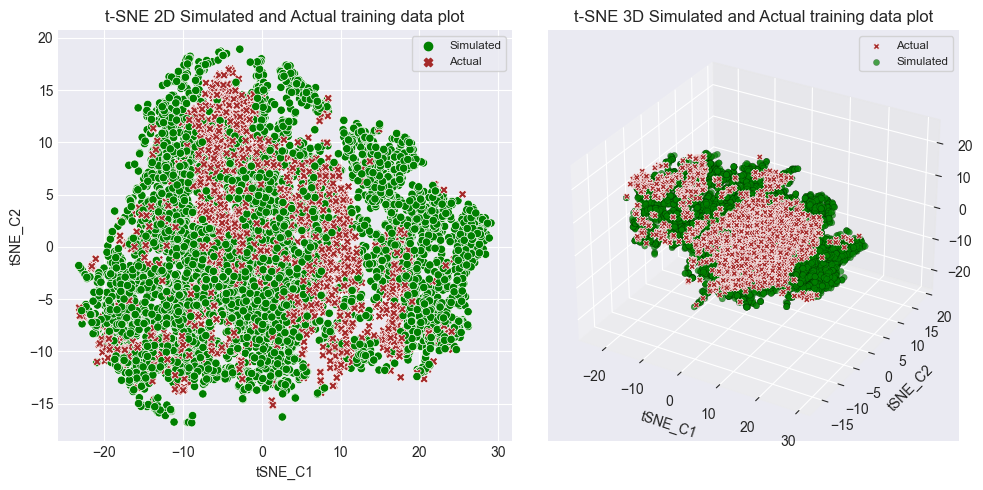

In [24]:
fig = plt.figure(figsize=(10,5))
data_colour = {'Simulated':'green','Actual':'brown'}
data_marker = {'Simulated':'o','Actual':'X'}
dataEdge_colour = {'Simulated':'black','Actual':'white'}
dataEdge_width = {'Simulated':0.15,'Actual':0.4}
data_visbility = {'Simulated':0.7,'Actual':1}

# Plotting t-SNE in 2D space
ax1 = fig.add_subplot(121)
sns.scatterplot(data=tSNEComponents_3DF, x='tSNE_C1', y='tSNE_C2', hue='Source', palette=data_colour, markers=data_marker, style='Source', ax=ax1)
ax1.set_title('t-SNE 2D Simulated and Actual training data plot')
ax1.legend(frameon=True, fontsize='small')

# Plotting t-SNE in 3D space 
ax2 = fig.add_subplot(122, projection='3d')
for source, group in tSNEComponents_3DF.groupby('Source'):
    ax2.scatter(group['tSNE_C1'], group['tSNE_C2'], group['tSNE_C3'], zdir='z',label=source, alpha=data_visbility[source], c=data_colour[source], marker=data_marker[source], edgecolors=dataEdge_colour[source], linewidths=dataEdge_width[source])
ax2.set_xlabel('tSNE_C1')
ax2.set_ylabel('tSNE_C2')
ax2.set_zlabel('tSNE_C3')
ax2.legend(frameon=True, fontsize='small')
ax2.set_title('t-SNE 3D Simulated and Actual training data plot')

plt.tight_layout()
plt.show()

From the 2 t-SNE plots above, we can observe the following:
- Presence of actual and similarity dataset clusters (indicated by the coloured clusters).
- High degree of similarity between the training set of the simulated and actual datasets (as indicated by the closeness of the clusters). This serves as validation for the choice of a similar source domain (simulated dataset) to act as the origin of the knowledge transfer for the model trained on the target domain (actual dataset).
- Additionally, there appears to be 2 major cluster patterns in both the simulated and actual dataset. Minor sub-clustering is also observed in the actual dataset cluster and the upper simulated dataset cluster but these require additional analysis before drawing any specific conclusions.

Further tuning of the hyperparameters and sample size can help uncover better insights and visualizations, but at the cost of computational effort (time and space complexity).

In [25]:
# Using PCA to decompose the features before feeding as input to the neural network
# Fitting the PCA model to capture 95% variance in the data
time_start = time.time()
pca95_sim = PCA(n_components=0.95)
pca95_act = PCA(n_components=0.95)
pca95_sim.fit(Xsim_trainStd)
pca95_act.fit(Xact_trainStd)

Xsim_trainStdPCA = pca95_sim.transform(Xsim_trainStd)
Xsim_valStdPCA = pca95_sim.transform(Xsim_valStd)
Xact_trainStdPCA = pca95_act.transform(Xact_trainStd)
Xact_valStdPCA = pca95_act.transform(Xact_valStd)
Xact_testStdPCA = pca95_act.transform(Xact_testStd)
print('PCA (95% variance) completed. Time elapsed: {:.2f} seconds'.format(time.time()-time_start))
print("\nNumber of PCA components that explain 95% variance (Simulated):", pca95_sim.n_components_)
print("\nNumber of PCA components that explain 95% variance (Actual):", pca95_act.n_components_)

PCA (95% variance) completed. Time elapsed: 2.31 seconds

Number of PCA components that explain 95% variance (Simulated): 21

Number of PCA components that explain 95% variance (Actual): 21


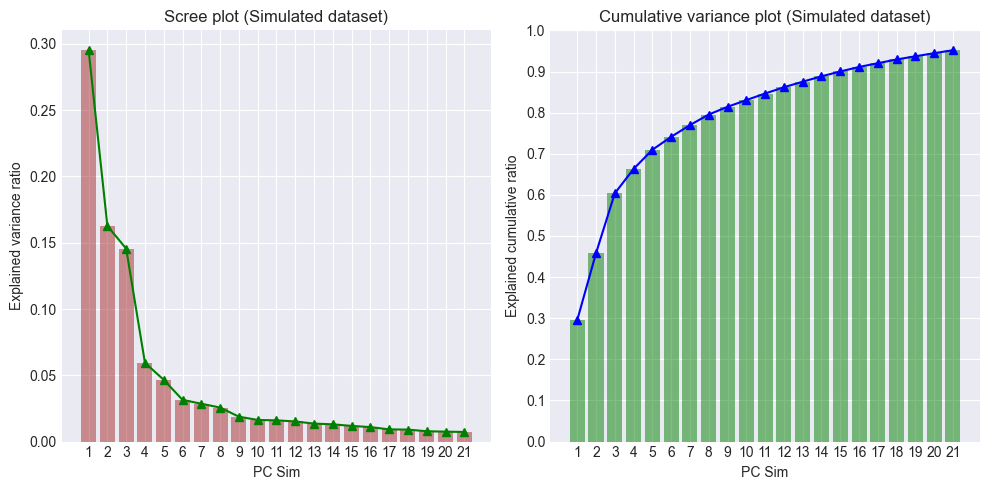


┏━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃   PC Sim ┃   Variance % ┃   Cumulative Variance % ┃
┣━━━━━━━━━━╋━━━━━━━━━━━━━━╋━━━━━━━━━━━━━━━━━━━━━━━━━┫
┃        1 ┃        29.54 ┃                   29.54 ┃
┃        2 ┃        16.27 ┃                   45.81 ┃
┃        3 ┃        14.56 ┃                   60.37 ┃
┃        4 ┃         5.94 ┃                   66.31 ┃
┃        5 ┃         4.66 ┃                   70.97 ┃
┃        6 ┃         3.15 ┃                   74.12 ┃
┃        7 ┃         2.86 ┃                   76.98 ┃
┃        8 ┃         2.57 ┃                   79.55 ┃
┃        9 ┃         1.88 ┃                   81.43 ┃
┃       10 ┃         1.63 ┃                   83.06 ┃
┃       11 ┃         1.6  ┃                   84.66 ┃
┃       12 ┃         1.52 ┃                   86.18 ┃
┃       13 ┃         1.36 ┃                   87.54 ┃
┃       14 ┃         1.3  ┃                   88.84 ┃
┃       15 ┃         1.18 ┃                   90.02 ┃
┃       16 ┃         1.09 ┃

In [26]:
fig = plt.figure(figsize=(10,5))
ax1 = fig.add_subplot(121)
ax1.plot(range(1, len(pca95_sim.explained_variance_ratio_) + 1), pca95_sim.explained_variance_ratio_, marker='^', linestyle='-', c='green')
ax1.bar(range(1, pca95_sim.n_components_ + 1), pca95_sim.explained_variance_ratio_, alpha=0.5, color='brown')
ax1.set_xticks(np.arange(1, pca95_sim.n_components_+ 1, step=1))
ax1.set_xlabel('PC Sim')
ax1.set_ylabel('Explained variance ratio')
ax1.set_title('Scree plot (Simulated dataset)')

ax2 = fig.add_subplot(122)
ax2.plot(range(1, len(pca95_sim.explained_variance_ratio_) + 1), np.cumsum(pca95_sim.explained_variance_ratio_), marker='^', linestyle='-', c='blue')
ax2.bar(range(1, pca95_sim.n_components_ + 1), np.cumsum(pca95_sim.explained_variance_ratio_), alpha=0.5, color='green')
ax2.set_xticks(np.arange(1, pca95_sim.n_components_+ 1, step=1))
ax2.set_yticks(np.arange(0.0, 1.1, step=0.1))
ax2.set_xlabel('PC Sim')
ax2.set_ylabel('Explained cumulative ratio')
ax2.set_title('Cumulative variance plot (Simulated dataset)')

plt.tight_layout()
plt.show()
print()

PCvariationDF_Sim = pd.DataFrame({'Variance %': [np.round(val*100, 2) for val in pca95_sim.explained_variance_ratio_]})
pca_varCum = np.cumsum(np.round(pca95_sim.explained_variance_ratio_ * 100, 2))
PCvariationDF_Sim['Cumulative Variance %'] = pca_varCum
PCvariationDF_Sim.index.name = "PC Sim"
PCvariationDF_Sim.reset_index(inplace=True)
PCvariationDF_Sim['PC Sim'] = PCvariationDF_Sim['PC Sim']+1
print(PCvariationDF_Sim.to_markdown(index=False, tablefmt="heavy_outline"))

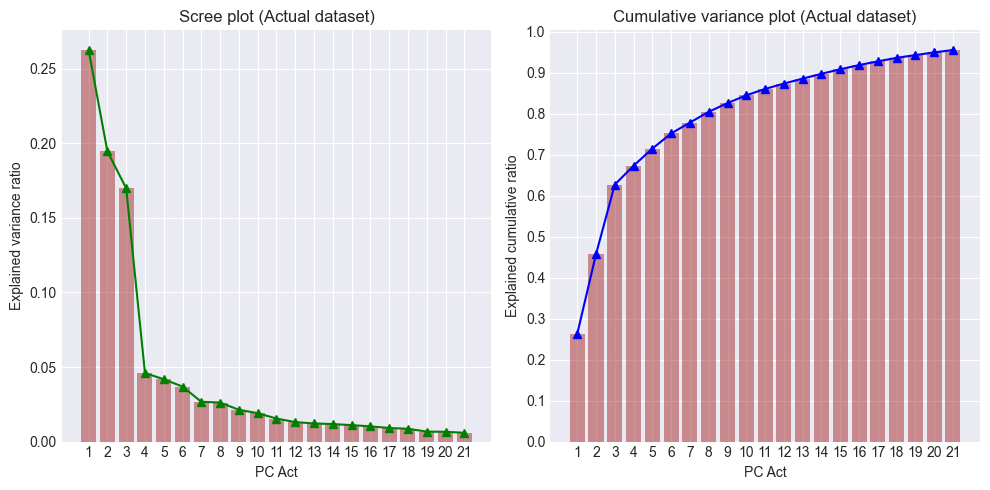


┏━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃   PC Act ┃   Variance % ┃   Cumulative Variance % ┃
┣━━━━━━━━━━╋━━━━━━━━━━━━━━╋━━━━━━━━━━━━━━━━━━━━━━━━━┫
┃        1 ┃        26.26 ┃                   26.26 ┃
┃        2 ┃        19.47 ┃                   45.73 ┃
┃        3 ┃        16.99 ┃                   62.72 ┃
┃        4 ┃         4.6  ┃                   67.32 ┃
┃        5 ┃         4.18 ┃                   71.5  ┃
┃        6 ┃         3.69 ┃                   75.19 ┃
┃        7 ┃         2.67 ┃                   77.86 ┃
┃        8 ┃         2.62 ┃                   80.48 ┃
┃        9 ┃         2.13 ┃                   82.61 ┃
┃       10 ┃         1.9  ┃                   84.51 ┃
┃       11 ┃         1.55 ┃                   86.06 ┃
┃       12 ┃         1.31 ┃                   87.37 ┃
┃       13 ┃         1.22 ┃                   88.59 ┃
┃       14 ┃         1.18 ┃                   89.77 ┃
┃       15 ┃         1.1  ┃                   90.87 ┃
┃       16 ┃         1.02 ┃

In [27]:
fig = plt.figure(figsize=(10,5))
ax1 = fig.add_subplot(121)
ax1.plot(range(1, len(pca95_act.explained_variance_ratio_) + 1), pca95_act.explained_variance_ratio_, marker='^', linestyle='-', c='green')
ax1.bar(range(1, pca95_act.n_components_ + 1), pca95_act.explained_variance_ratio_, alpha=0.5, color='brown')
ax1.set_xticks(np.arange(1, pca95_act.n_components_+ 1, step=1))
ax1.set_xlabel('PC Act')
ax1.set_ylabel('Explained variance ratio')
ax1.set_title('Scree plot (Actual dataset)')

ax2 = fig.add_subplot(122)
ax2.plot(range(1, len(pca95_act.explained_variance_ratio_) + 1), np.cumsum(pca95_act.explained_variance_ratio_), marker='^', linestyle='-', c='blue')
ax2.bar(range(1, pca95_act.n_components_ + 1), np.cumsum(pca95_act.explained_variance_ratio_), alpha=0.5, color='brown')
ax2.set_xticks(np.arange(1, pca95_act.n_components_+ 1, step=1))
ax2.set_yticks(np.arange(0.0, 1.1, step=0.1))
ax2.set_xlabel('PC Act')
ax2.set_ylabel('Explained cumulative ratio')
ax2.set_title('Cumulative variance plot (Actual dataset)')

plt.tight_layout()
plt.show()
print()

PCvariationDF_Act_Act = pd.DataFrame({'Variance %': [np.round(val*100, 2) for val in pca95_act.explained_variance_ratio_]})
pca_varCum = np.cumsum(np.round(pca95_act.explained_variance_ratio_ * 100, 2))
PCvariationDF_Act_Act['Cumulative Variance %'] = pca_varCum
PCvariationDF_Act_Act.index.name = "PC Act"
PCvariationDF_Act_Act.reset_index(inplace=True)
PCvariationDF_Act_Act['PC Act'] = PCvariationDF_Act_Act['PC Act']+1
print(PCvariationDF_Act_Act.to_markdown(index=False, tablefmt="heavy_outline"))

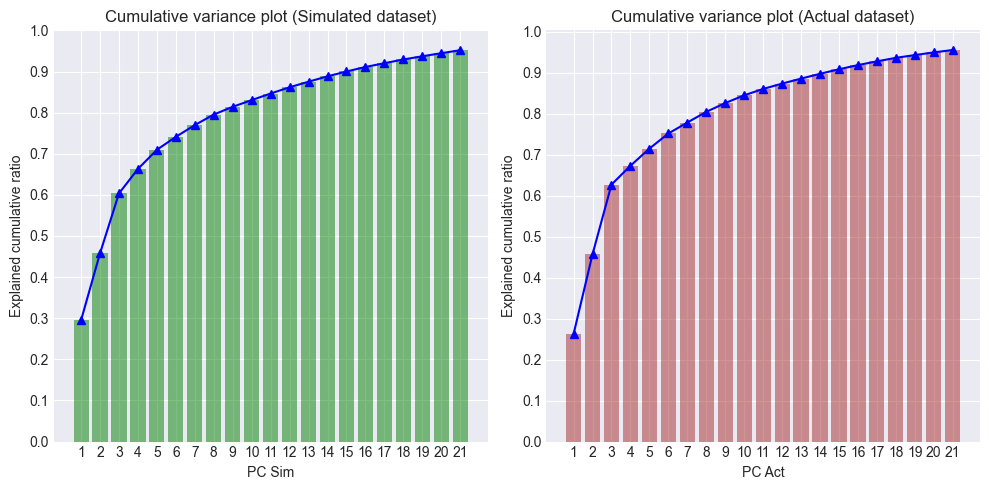

In [28]:
fig = plt.figure(figsize=(10,5))
ax1 = fig.add_subplot(121)
ax1.plot(range(1, len(pca95_sim.explained_variance_ratio_) + 1), np.cumsum(pca95_sim.explained_variance_ratio_), marker='^', linestyle='-', c='blue')
ax1.bar(range(1, pca95_sim.n_components_ + 1), np.cumsum(pca95_sim.explained_variance_ratio_), alpha=0.5, color='green')
ax1.set_xticks(np.arange(1, pca95_sim.n_components_+ 1, step=1))
ax1.set_yticks(np.arange(0.0, 1.1, step=0.1))
ax1.set_xlabel('PC Sim')
ax1.set_ylabel('Explained cumulative ratio')
ax1.set_title('Cumulative variance plot (Simulated dataset)')


ax2 = fig.add_subplot(122)
ax2.plot(range(1, len(pca95_act.explained_variance_ratio_) + 1), np.cumsum(pca95_act.explained_variance_ratio_), marker='^', linestyle='-', c='blue')
ax2.bar(range(1, pca95_act.n_components_ + 1), np.cumsum(pca95_act.explained_variance_ratio_), alpha=0.5, color='brown')
ax2.set_xticks(np.arange(1, pca95_act.n_components_+ 1, step=1))
ax2.set_yticks(np.arange(0.0, 1.1, step=0.1))
ax2.set_xlabel('PC Act')
ax2.set_ylabel('Explained cumulative ratio')
ax2.set_title('Cumulative variance plot (Actual dataset)')
plt.tight_layout()
plt.show()

In [29]:
# # PCA Biplot
# Xtrain_combinePCA = pd.concat([pd.DataFrame(Xsim_trainStdPCA), pd.DataFrame(Xact_trainStdPCA)], ignore_index=True)
# Xtrain_combinePCA['Source'] = ['Simulated']*len(Xsim_trainStdPCA) + ['Actual']*len(Xact_trainStdPCA)
# pca95_vct = pca95.components_.T
# dataFeature_name = simulData_clean.keys().to_series().drop(labels='OutgoingThickness')

# fig = plt.figure(figsize=(10,5))
# ax1 = fig.add_subplot(121)
# # PCA 2D plot
# ax1.set_xlabel("PCA_C1")
# ax1.set_ylabel("PCA_C2")
# ax1.set_title("PCA Biplot 2D")
# sns.scatterplot(data=Xtrain_combinePCA, x=Xtrain_combinePCA[0], y=Xtrain_combinePCA[1], hue='Source', palette=data_colour, markers=data_marker, style='Source')
# for i in range(pca95.components_.T.shape[0]):
#     ax1.arrow(0, 0, pca95_vct[i, 0]*60, pca95_vct[i, 1]*60, color='blue', alpha=0.7, linestyle=':', length_includes_head=True, head_width=0.25, head_length=0.4)
#     ax1.text(pca95_vct[i, 0]*60*1.005, pca95_vct[i, 1]*60*1.005, dataFeature_name[i], ha='center', va='center', color='black', alpha=0.5, style='italic', weight='light', size='x-small')   
# ax1.legend(frameon=True, fontsize='small')

# # PCA 3D plot  
# ax2 = fig.add_subplot(122, projection='3d')    
# ax2.set_title("PCA Biplot 3D")
# for source, group in Xtrain_combinePCA.groupby('Source'):
#     ax2.scatter(group[0], group[1], group[2], zdir='z',label=source, alpha=data_visbility[source], depthshade=False, c=data_colour[source], marker=data_marker[source], edgecolors=dataEdge_colour[source], linewidths=dataEdge_width[source])
# for i in range(pca95.components_.T.shape[0]):
#     ax2.quiver(0, 0, 0, pca95_vct[i, 0]*60, pca95_vct[i, 1]*60, pca95_vct[i, 2]*60, color='blue', alpha=1, linestyle=':', arrow_length_ratio=0.2)
#     ax2.text(pca95_vct[i, 0]*60*1.005, pca95_vct[i, 1]*60*1.005, pca95_vct[i, 2]*60*1.005, dataFeature_name[i], ha='center', va='center', color='black', alpha=0.5, style='italic', weight='light', size='x-small')   
# ax2.set_xlabel("PCA_C1")
# ax2.set_ylabel("PCA_C2")
# ax2.set_zlabel("PCA_C3")
# ax2.legend(frameon=True, fontsize='small')

# plt.tight_layout()
# plt.show()
# print()

# # To display the top  features which contributed the most to each principal component
# dataLoadings_matrix = pd.DataFrame(pca95.components_, columns=dataFeature_name)
# topFeature = []
# for i, component in dataLoadings_matrix.iterrows():
#     topFeature.append(component.abs().nlargest(3).index.to_list())
    
# PCcontributionDF = pd.DataFrame(topFeature, columns = [f"Top_{i+1} Feature" for i in range(3)])
# PCcontributionDF.index.name = "PC"
# PCcontributionDF.reset_index(inplace=True)
# PCcontributionDF['PC'] = PCcontributionDF['PC'] + 1
# print(PCcontributionDF.to_markdown(index=False, tablefmt="heavy_outline"))

We have used PCA to reduce the feature space of our trimmed dataset from 86 original features to 21 reduced features. This was accomplished by setting the parameter such the principal components capture 95% of the data variance (spread of the data). While greater data variance percentages can be chosen, 95% was chosen to minimize the computational complexity, especially when feeding it as input to the neural network.

We have plotted the scree plot and the cumulative variance plots. From these plots we can see:
- The principle components and how much data variance each component captures. PC1 captures the highest variance of 29.54% followed by PC2 with 16.27 and so on.
- From the scree plot, it can also be observed from the trend of the graph that the principal components after PC21 capture very little variance of the data and hence these were not chosen (as indicated by the moderate stagnation in the rate of change of the explained variance curve). Furthermore, the cumulative variance plot shows that with 21 components, we have obtain our threshold variance of 95%. Other methods for selecting the number of PC exist like the elbow method (keep components before curve flattens) from the scree plot and kaiser's rule (chosen PC with eigenvalues greater than 1) but we chose the threshold variance method since the former methods can be subjective and may not capture a significant portion of the data.
- The principal components, the explained variance of each component and the corresponding cumulative variance have been summarized in the associated data frame.

We have also plotted the biplots (in 2D and 3D). From these plots we can see:
- The actual dataset points and the simulated data points are close; the results being analogous to those from the t-SNE plots (although the t-SNE plots were able to capture the data clusters better (even though it was just 10000 points)). 
- We can also see the contribution of each feature in contributing towards the principle components (the first 2 components in the 2D plot and the first 3 in the 3D plot) as indicated by the arrows in the biplot. The length of the arrows is used to indicate the magnitude of contribution while the direction of the arrows indicates the positive or negative correlation which each of the PC denoted by axis.  
- The orientation of the arrows, i.e. the angle sizes between each of the loading vector arrows can be used to indicate the degree of correlation between the feature variables. Acute angles denote positive correlations, orthogonal (or close to it) denotes weak or no correlation and obtuse angles close to the straight angle denotes negative correlation.
- The principal components and the top 3 features contributing to each PC have been summarized in the associated data frame. Unfortunately due to the sheer number of features, it is difficult to draw further analysis about the feature correlations with each other and the principal components. 
- It is also important to note that the top defining feature for each principal component does not imply that it is the most important feature in predicting the outcome of the regression, in our case, the outcome of the `OutgoingThickness`. The feature contribution is a measure of the weight of the features in the linear combination for the formation of each PC. The absolute values of the contribution from each feature is taken to understand the magnitude that the feature provides in the creation of the PC (This corresponds to the domain of feature selection and importance which can be accomplished through decision trees, regularization techniques, etc. PCA corresponds to the feature extraction domain, wherein from a given set of features, new features are formed through the linear mapping of existing features.)

In [30]:
# Creating a folder to save all tabular results
if not os.path.exists('TL_Production_tables'):
    os.makedirs('TL_Production_tables')
# Creating a folder to save all untrained model weights and biases
if not os.path.exists('Model_untrain_WB'):
    os.makedirs('Model_untrain_WB')
# Creating a folder to save all trained model weights and biases
if not os.path.exists('Model_train_WB'):
    os.makedirs('Model_train_WB')
# Creating a folder to save model checkpoints
if not os.path.exists('Model_Checkpoints'):
    os.makedirs('Model_Checkpoints')

In [31]:
SimDF_posCorr = pd.DataFrame(SimDict_posCorr)
SimDF_negCorr = pd.DataFrame(SimDict_negCorr)
ActDF_posCorr = pd.DataFrame(ActDict_posCorr)
ActDF_negCorr = pd.DataFrame(ActDict_negCorr)
commPosCorr_SimAct_DF = pd.DataFrame(commPosCorr_SimAct_set, columns=["Feature 1", "Feature 2"])
commNegCorr_SimAct_DF = pd.DataFrame(commNegCorr_SimAct_set, columns=["Feature 1", "Feature 2"])
with pd.ExcelWriter('TL_Production_tables/Data Stats.xlsx') as writer:
    actualData_SummStat.to_excel(writer, sheet_name='Actual Data Summary')
    simulData_SummStat.to_excel(writer, sheet_name='Simul Data Summary')
    simul_corr_matrix.to_excel(writer, sheet_name='Actual Data Correlation')
    actual_corr_matrix.to_excel(writer, sheet_name='Simul Data Correlation')
    SimDF_posCorr.to_excel(writer, sheet_name='Simul Positive Correlation', index=False) 
    SimDF_negCorr.to_excel(writer, sheet_name='Simul Negative Correlation', index=False) 
    ActDF_posCorr.to_excel(writer, sheet_name='Actual Positive Correlation', index=False) 
    ActDF_negCorr.to_excel(writer, sheet_name='Actual Negative Correlation', index=False)
    commPosCorr_SimAct_DF.to_excel(writer, sheet_name='Common Positive Correlation', index=False)
    commNegCorr_SimAct_DF.to_excel(writer, sheet_name='Common Negative Correlation', index=False)
# with pd.ExcelWriter('TL_Production_tables/PCA Results.xlsx') as writer:
#     PCvariationDF.to_excel(writer, sheet_name='Explained Variance', index=False)
#     PCcontributionDF.to_excel(writer, sheet_name='Feature Contribution', index=False)

## [EXPERIMENT 1]: Comparison of model performances vs epochs

### Model 1: Control model (model trained on the actual training dataset)

In [32]:
# Check for GPU support
if torch.cuda.is_available():
    device = torch.device('cuda')
    device_name = torch.cuda.get_device_name(torch.cuda.current_device())
    print(f"Device: {device}, GPU model: {device_name}")
else:
    device = torch.device('cpu')
    print("Device: CPU")

Device: cuda, GPU model: NVIDIA GeForce MX230


#### Creating the PyTorch dataset tensors and data loader objects for the actual dataset

In [33]:
# Loading and transforming the datasets into tensors
Xact_trainTensor = torch.tensor(Xact_trainStdPCA, dtype=torch.float32)
Xact_valTensor = torch.tensor(Xact_valStdPCA, dtype=torch.float32)
Xact_testTensor = torch.tensor(Xact_testStdPCA, dtype=torch.float32)
# Converting series into numpy array and reshaping to (n, 1)
Yact_trainTensor = torch.tensor(Yact_train.to_numpy(), dtype=torch.float32).unsqueeze(1)
Yact_valTensor = torch.tensor(Yact_val.to_numpy(), dtype=torch.float32).unsqueeze(1)
Yact_testTensor = torch.tensor(Yact_test.to_numpy(), dtype=torch.float32).unsqueeze(1)

print("Actual training set tensor sizes")
print("Xtrain:", Xact_trainTensor.size(), " Ytrain:", Yact_trainTensor.size())
print("\nActual validation set tensor sizes")
print("Xval:", Xact_valTensor.size(), " Yval:", Yact_valTensor.size())
print("\nActual test set tensor sizes")
print("Xtest:", Xact_testTensor.size(), " Ytest:", Yact_testTensor.size())

# Creating train, validation and test torch datasets
ActTrain_torchSet = TensorDataset(Xact_trainTensor, Yact_trainTensor)
ActVal_torchSet = TensorDataset(Xact_valTensor, Yact_valTensor)
ActTest_torchSet = TensorDataset(Xact_testTensor, Yact_testTensor)

# Creating DataLoader objects
# Using small batch sizes for training due to low memory GPU and larger batch sizes for validation and testing to speed up model evaluation (and since these processes have lesser memory requirements)
trainBatchSize = 32
val_testBatchSize = 1024
ActTrain_torchLoad = DataLoader(ActTrain_torchSet, batch_size=trainBatchSize, shuffle=True)
ActVal_torchLoad = DataLoader(ActVal_torchSet, batch_size=val_testBatchSize, shuffle=False)
ActTest_torchLoad = DataLoader(ActTest_torchSet, batch_size=val_testBatchSize, shuffle=False)
print("\nNumber of batches created")
print("Train:", len(ActTrain_torchLoad), "   Validation:", len(ActVal_torchLoad), "   Test:", len(ActTest_torchLoad))

Actual training set tensor sizes
Xtrain: torch.Size([67894, 21])  Ytrain: torch.Size([67894, 1])

Actual validation set tensor sizes
Xval: torch.Size([19398, 21])  Yval: torch.Size([19398, 1])

Actual test set tensor sizes
Xtest: torch.Size([9700, 21])  Ytest: torch.Size([9700, 1])

Number of batches created
Train: 2122    Validation: 19    Test: 10


#### Defining the control model architecture

In [34]:
# Neural network class definition
class ANN_MultiReg(nn.Module):
    def __init__(self, dim_inputNode, dim_outputNode, dim_hiddenNode, activateFn=F.relu):
        super(ANN_MultiReg, self).__init__()
        self.layers = nn.ModuleList()
        self.actFN = activateFn
        for i in range(len(dim_hiddenNode)):
            # When i=0 the input layer is created first else the hidden layers
            in_Node = dim_inputNode if i==0 else dim_hiddenNode[i-1]
            out_Node = dim_hiddenNode[i]
            self.layers.append(nn.Linear(in_Node, out_Node))
        # Output layer
        self.layers.append(nn.Linear(dim_hiddenNode[-1], dim_outputNode))
        
# Since it is a regression task a linear activation function (implemented by default in the output Linear layer) is enough for the output layer and ReLU is not applied after the output layer
    def forward(self, x):
        for i, layer in enumerate(self.layers):
            x = layer(x)
            # Applying activation function only between hidden layers
            if i<len(self.layers)-1:
                x = self.actFN(x)
        return x
    
# He initialization of weights and biases since this works best with the ReLU activation function
    def init_WeightBias(self):
        for layer in self.layers:
            # Checking for linear layers
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_uniform_(layer.weight, nonlinearity = "relu")
                # Setting the bias tensors to 0
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

In [35]:
# Seeding random number generators for discreteness 
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Defining the model hyperparameters
inputDimension = 21
hiddenDimension = [35, 28, 24, 15]
outputDimension = 1
activationFunction = F.relu
learnRate = 1e-3
# L2 regularization strength
weightDecay = 1e-4

# Instantiating the control model and moving it to GPU
Act_ctrlModel1 = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)
# Initializing the weights
Act_ctrlModel1.init_WeightBias()
# Loss function
criterion = nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(Act_ctrlModel1.parameters(), lr = learnRate, weight_decay = weightDecay)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(Act_ctrlModel1)
print(summary(Act_ctrlModel1, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         True
├─ModuleList: 1-1                        --              --              --                   --         True
│    └─Linear: 2-1                       [32, 21]        [32, 35]        770              26.88%         True
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29%      

In [36]:
# Visualize (and view the weights and biases of) the untrained model (uncomment the last line)
model_FileName = 'Model_untrain_WB/M1_ctrlModel_untrain.onnx'
# Moving model and tensor to CPU
Act_ctrlModel1_CPU = Act_ctrlModel1.to('cpu')
batchDim = (trainBatchSize, Xact_trainTensor.size(1))
randomInput = torch.randn(batchDim, device='cpu')
torch.onnx.export(Act_ctrlModel1_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Defining the training and evaluation loops in the train function

In [37]:
# Model training function
def train_NNRegModel(model, train_loader, val_loader, optimizer, criterion, device, epochs=500, patience=10, epoch_StartPT=0, checkPT_savePTH=None, checkPT_loadPTH=None, ph2_learnRate=None):
    best_validationLoss = float("inf")
    stopCounter = 0
    best_Model = None
    # Saving the best optimizer for checkpointing
    best_optimizer = None 
    best_trainLoss = float("inf")
    best_validationMAE = float("inf")
    best_validationR2S = float("-inf")
    best_epoch = -1
    early_stop = False
    # Storing metrics
    Model_trainLoss = []
    Model_valLoss = []
    Model_valMAE = []
    Model_valR2S = []
    
    # Loading the checkpoint
    if epoch_StartPT>0 and checkPT_loadPTH is not None:
        checkPT = torch.load(checkPT_loadPTH)
        model.load_state_dict(checkPT['model_checkPT'])
        optimizer.load_state_dict(checkPT['optimizer_checkPT'])
        
    # Updating the learning rate for phase 2 training
    if ph2_learnRate is not None:
        for param_LR in optimizer.param_groups:
            param_LR['lr'] = ph2_learnRate
    
    # Training loop
    start_time = time.time()
    for epoch in range(epoch_StartPT, epochs):
        # Set the model to train mode
        model.train()
        train_loss = 0.0
        
        for X_Trainbatch, Y_Trainbatch in train_loader:
            X_Trainbatch, Y_Trainbatch = X_Trainbatch.to(device), Y_Trainbatch.to(device)
            # Zeroing the gradients
            optimizer.zero_grad()
            # Forward pass
            train_prediction = model(X_Trainbatch)
            loss = criterion(train_prediction, Y_Trainbatch)
            # Backward pass and updating weights
            loss.backward()
            optimizer.step()
            # Training loss for current batch (scaled to the size of the batch)
            train_batch_loss = loss.item() * X_Trainbatch.size(0)
            train_loss += train_batch_loss
        # To get average training loss per epoch
        train_loss /= len(train_loader.dataset)
        Model_trainLoss.append(train_loss)
        
        # Set the model to validation mode
        model.eval()
        val_loss = 0.0
        val_mae = 0.0
        val_r2s = 0.0
        with torch.no_grad():
            for X_Valbatch, Y_Valbatch in val_loader:
                X_Valbatch, Y_Valbatch = X_Valbatch.to(device), Y_Valbatch.to(device)
                val_prediction = model(X_Valbatch)
                loss = criterion(val_prediction, Y_Valbatch)
                val_batch_loss = loss.item() * X_Valbatch.size(0)
                val_loss += val_batch_loss
                # Performance metrics for current batch
                val_mae += mean_absolute_error(Y_Valbatch.cpu().detach().numpy(), val_prediction.cpu().detach().numpy()) * X_Valbatch.size(0)
                val_r2s += r2_score(Y_Valbatch.cpu().detach().numpy(), val_prediction.cpu().detach().numpy()) * X_Valbatch.size(0)
        # To get average performance metrics per epoch
        val_loss /= len(val_loader.dataset)
        Model_valLoss.append(val_loss)
        val_mae /= len(val_loader.dataset)
        Model_valMAE.append(val_mae)
        val_r2s /= len(val_loader.dataset)
        Model_valR2S.append(val_r2s)
        
        # Print statistics every 20 epochs
        if (epoch + 1)%20==0 or epoch==epoch_StartPT:
            print(f"Epoch [{epoch+1}/{epochs}] ==> Train Loss: {train_loss:.4f}, Validation Loss: {val_loss:.4f}, Validation MAE: {val_mae:.4f}, Validation R^2: {val_r2s:.4f}")
            if (epoch + 1)%100==0 or epoch==epoch_StartPT:
                print()
            
        # Early stopping check
        if val_loss<best_validationLoss:
            best_validationLoss = val_loss
            best_Model = copy.deepcopy(model.state_dict())
            # Saving the best optimizer state for checkpointing
            best_optimizer = copy.deepcopy(optimizer.state_dict())
            stopCounter = 0
            # Store best metrics w.r.t best validation loss
            best_trainLoss = train_loss
            best_validationMAE = val_mae
            best_validationR2S = val_r2s
            best_epoch = epoch
            
            # Saving the best model and optimizer state as the checkpoint
            if checkPT_savePTH is not None:
                torch.save({
                    'model_checkPT': best_Model,
                    'optimizer_checkPT': best_optimizer
                }, checkPT_savePTH)
            
        else:
            stopCounter += 1
            if stopCounter>=patience:
                early_stop = True
                break

    if early_stop:
        print("\nEarly stopping triggered. Training halted.")
    
    # Printing metrics
    end_time = time.time() - start_time
    print(f"\nTraining completed in {end_time // 60:.0f} minutes and {end_time % 60:.0f} seconds.")
    print('-' * 122)
    print(f"Best epoch: {best_epoch+1} || Best train loss: {best_trainLoss:.4f} || Best val loss: {best_validationLoss:.4f} || Best val MAE: {best_validationMAE:.4f} || Best val R^2: {best_validationR2S:.4f}")
    print('-' * 122)
    
    # Loading the best model
    model.load_state_dict(best_Model)
    
    return end_time, model, {"Model_best epoch": best_epoch,
                  "Model_best train loss": best_trainLoss,
                  "Model_best val loss": best_validationLoss,
                  "Model_best val MAE": best_validationMAE,
                  "Model_best val R2S": best_validationR2S
                  }, {"Model_history train loss": Model_trainLoss, 
                  "Model_history val loss": Model_valLoss,
                  "Model_history val MAE": Model_valMAE,
                  "Model_history val R2S": Model_valR2S,
                  }

In [38]:
# # For a more prettier version of the training process (with a progress bar) replace the train mode code above with below. Note: sometimes the output kernel buffer crashes and hence this method was discarded.
# # Edit: Something is wrong with the way tqdm is being called, for example, I am passing the entire DataLoader object and perhaps that resizing is causing the buffer to crash.
#         # Set the model to train mode
#         model.train()
#         train_loss = 0.0

#         # Show progress bar every 10 epochs
#         show_progress = (epoch + 1)%10==0 or epoch == 0
#         with tqdm.tqdm(train_loader, desc=f"Epoch {epoch+1}", disable=not show_progress) as pbar:
#             for X_Trainbatch, Y_Trainbatch in pbar:
#                 X_Trainbatch, Y_Trainbatch = X_Trainbatch.to(device), Y_Trainbatch.to(device)
#                 # Zeroing the gradients
#                 optimizer.zero_grad()
#                 # Forward pass
#                 train_prediction = model(X_Trainbatch)
#                 loss = criterion(train_prediction, Y_Trainbatch)
#                 # Backward pass and updating weights
#                 loss.backward()
#                 optimizer.step()
#                 # Training loss for current batch (scaled to the size of the batch)
#                 train_batch_loss = loss.item() * X_Trainbatch.size(0)
#                 train_loss += train_batch_loss
#                 # Updating the progress bar (displays the last batch loss)
#                 pbar.set_postfix({"Batch loss": train_batch_loss})
#                 pbar.update()
#         # To get average training loss per epoch
#         train_loss /= len(train_loader.dataset)
#         Model_trainLoss.append(train_loss)

In [39]:
# Move the model to GPU
Act_ctrlModel1 = Act_ctrlModel1.to(device)
# To train the model
trainTime_M1, trained_M1, bestStat_M1, history_M1 = train_NNRegModel(
     Act_ctrlModel1, 
     ActTrain_torchLoad, 
     ActVal_torchLoad, 
     optimizer, 
     criterion, 
     device, 
     epochs=500, 
     patience=20
)

Epoch [1/500] ==> Train Loss: 225327.4270, Validation Loss: 26819.9867, Validation MAE: 124.1066, Validation R^2: 0.8440

Epoch [20/500] ==> Train Loss: 1269.1706, Validation Loss: 1281.1533, Validation MAE: 24.3693, Validation R^2: 0.9925
Epoch [40/500] ==> Train Loss: 936.8853, Validation Loss: 947.4605, Validation MAE: 21.1784, Validation R^2: 0.9945
Epoch [60/500] ==> Train Loss: 794.5032, Validation Loss: 1138.8151, Validation MAE: 24.5542, Validation R^2: 0.9934
Epoch [80/500] ==> Train Loss: 729.3965, Validation Loss: 855.4337, Validation MAE: 20.0359, Validation R^2: 0.9950
Epoch [100/500] ==> Train Loss: 662.5647, Validation Loss: 658.4758, Validation MAE: 17.9128, Validation R^2: 0.9962

Epoch [120/500] ==> Train Loss: 630.8960, Validation Loss: 676.0555, Validation MAE: 17.4300, Validation R^2: 0.9961

Early stopping triggered. Training halted.

Training completed in 16 minutes and 60 seconds.
----------------------------------------------------------------------------------

In [40]:
# Visualize (and view the weights and biases of) the trained model (uncomment the last line)
model_FileName = 'Model_train_WB/M1_ctrlModel_train.onnx'
trained_M1_CPU = trained_M1.to('cpu')
torch.onnx.export(trained_M1_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Defining the prediction function

In [41]:
# Model predicting function
def predict_NNRegModel(model, test_loader, device):
    # Set the model to evaluation mode
    model.eval()
    test_prediction = []
    test_TrueValue = []
    
    start_time = time.time()
    with torch.no_grad():
        for X_Testbatch, Y_Testbatch in test_loader:
            X_Testbatch = X_Testbatch.to(device)
            test_batch_prediction = model(X_Testbatch)
            # Append predictions and true values
            test_prediction.extend(test_batch_prediction.cpu().detach().numpy())
            test_TrueValue.extend(Y_Testbatch.numpy())
    
    test_prediction = np.array(test_prediction)
    test_TrueValue = np.array(test_TrueValue)
    test_mae = mean_absolute_error(test_TrueValue, test_prediction)
    test_r2s = r2_score(test_TrueValue, test_prediction)
    
    end_time = time.time() - start_time
    print(f"Prediction completed in {end_time:.2f} seconds.")
    print('-' * 122)
    print(f"Test MAE: {test_mae:.4f} || Test R^2: {test_r2s:.4f}")
    print('-' * 122)
    
    return end_time, test_prediction, test_mae, test_r2s

In [42]:
# To evaluate the model's performance on the actual data test set
trained_M1 = trained_M1.to(device)
testTime_M1, testPred_M1, testMAE_M1, testR2S_M1 = predict_NNRegModel(trained_M1, ActTest_torchLoad, device)

Prediction completed in 0.17 seconds.
--------------------------------------------------------------------------------------------------------------------------
Test MAE: 17.4124 || Test R^2: 0.9964
--------------------------------------------------------------------------------------------------------------------------


#### Visualizing the control model results 

In [43]:
def ModelLoss_MAE_R2S_epochPlot(model_trainLoss, model_valLoss, model_valMAE, model_valR2S):    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    # Training and validation loss vs epochs
    ax1.plot(model_trainLoss, color='#32CD32', label="Train Loss", alpha=0.8)
    ax1.plot(model_valLoss, color='#4169E1', label="Validation Loss", alpha=0.6)
    ax1.set_title("Model loss vs epochs")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("MSE loss")
    ax1.legend(frameon=True, fontsize='small') 
    # MAE and R2S score vs epochs
    ax2.plot(model_valMAE, color='#DC143C', label="Validation MAE")
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Mean absolute error", color='#DC143C')
    ax2.tick_params(axis='y', labelcolor='#DC143C')
    ax3 = ax2.twinx()
    ax3.plot(model_valR2S, color='#1E90FF', label="Validation R^2")
    ax3.set_ylabel("R^2 Score", color='#1E90FF')
    ax3.tick_params(axis='y', labelcolor='#1E90FF')
    ax3.grid(False)
    ax2.set_title("Validation performance metrics vs epochs")
    ax2.legend(frameon=True, fontsize='small', loc='center right', bbox_to_anchor=(0.5, 0.29, 0.5, 0.5))
    ax3.legend(frameon=True, fontsize='small', loc='center right', bbox_to_anchor=(0.5, 0.352, 0.5, 0.5))
    fig.tight_layout()
    plt.show()

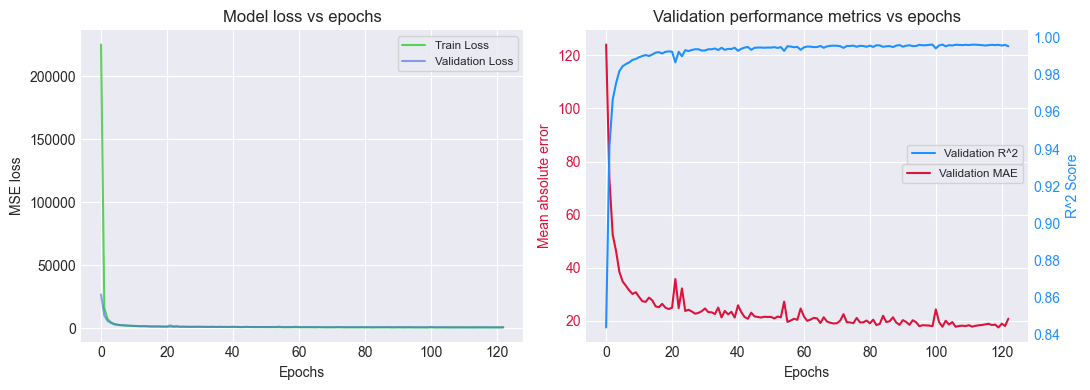

In [44]:
# Plotting the model losses and metrics vs epochs
ModelLoss_MAE_R2S_epochPlot(history_M1['Model_history train loss'],
                           history_M1['Model_history val loss'],
                           history_M1['Model_history val MAE'],
                           history_M1['Model_history val R2S'])

From the above 2 plots, we can see the trend of the curves for the training/validation loss and the model performance metrics with respect to the number of epochs taken. 
- As depicted from the model loss curves, there is a general decreasing trend for the training and validation loss curves which shows that as the number of epochs increases, the losses keep decreasing. This shows that the control model is converging to a solution.
- Furthermore, from the model performance metric curves, we can see that MAE keeps decreasing (trending towards 0) with the number of epochs while the R^2 score keeps increasing (trending towards 1) as the epochs increase. This shows that the control model is capable of generalizing well to the validation set.
- From the plots above, the model does not appear to over fit or under fit, as the loss curves decrease significantly and there is no increasing trend. Due to the large scale of the MSE loss, the curves appear to plateau but this is not the case, as shown in the plots below. Additionally, the MAE and R^2 plots keep decreasing and increasing respectively thus indicating that model is not under fitting to the validation dataset, and is able to capture the underlying regression trends.  

In [45]:
def zoomModelLoss_MAE_R2S_epochPlot(model_trainLoss, model_valLoss, model_valMAE, model_valR2S, model_bestEpoch, YlossLimit, 
                                    YmaeLimit, Yr2sLimit, wrmTuneEpoch=0):
    fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(8,10), sharex=True)
    # Train and test validation loss vs epochs
    axes[0].plot(model_trainLoss, color='#32CD32', label="Train Loss")
    axes[0].plot(model_valLoss, color='#4169E1', label="Validation Loss")
    axes[0].set_title("Model loss vs epochs")
    axes[0].set_ylabel("MSE loss")
    axes[0].set_ylim(YlossLimit[0], YlossLimit[1])
    axes[0].axvline(model_bestEpoch, color='k', linestyle='--', alpha=0.65)
    if wrmTuneEpoch>0:
        axes[0].axvline(wrmTuneEpoch, color='#FF8C00', linestyle=':', alpha=0.65)
    axes[0].legend(frameon=True, fontsize='small')
    # MAE vs epochs
    axes[1].plot(model_valMAE, color='#DC143C', label="Validation MAE")
    axes[1].set_title("Model val MAE vs epochs")
    axes[1].set_ylabel("Mean absolute error")
    axes[1].set_ylim(YmaeLimit[0], YmaeLimit[1])
    axes[1].axvline(model_bestEpoch, color='k', linestyle='--', alpha=0.65)
    if wrmTuneEpoch>0:
        axes[1].axvline(wrmTuneEpoch, color='#FF8C00', linestyle=':', alpha=0.65)
    axes[1].legend(frameon=True, fontsize='small')
    # R^2 score vs epochs
    axes[2].plot(model_valR2S, color='#1E90FF', label="Validation R^2")
    axes[2].set_title("Model val R^2 vs epochs")
    axes[2].set_ylabel("R^2 score")
    axes[2].set_ylim(Yr2sLimit[0], Yr2sLimit[1])
    axes[2].axvline(model_bestEpoch, color='k', linestyle='--', alpha=0.65)
    if wrmTuneEpoch>0:
        axes[2].axvline(wrmTuneEpoch, color='#FF8C00', linestyle=':', alpha=0.8)
    axes[2].legend(frameon=True, fontsize='small')
    
    if wrmTuneEpoch>0:
        axes[-1].set_xlabel(f"Epochs (Fine tune start epoch: {wrmTuneEpoch}, Best epoch: {model_bestEpoch})")
    else:
        axes[-1].set_xlabel(f"Epochs (Best epoch: {model_bestEpoch})")
    plt.show()

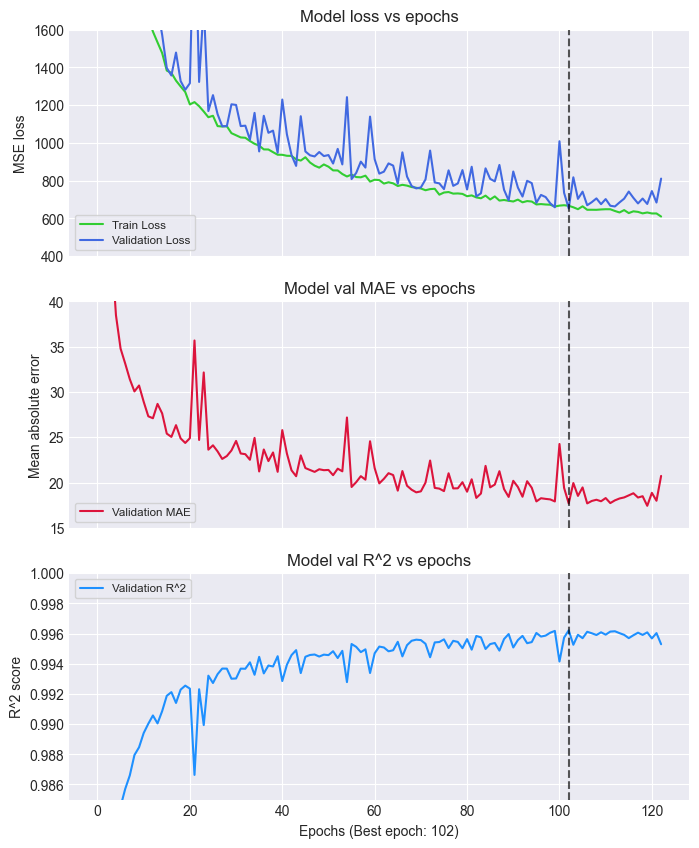

In [46]:
zoomModelLoss_MAE_R2S_epochPlot(history_M1['Model_history train loss'],
                                history_M1['Model_history val loss'],
                                history_M1['Model_history val MAE'],
                                history_M1['Model_history val R2S'], 
                                bestStat_M1['Model_best epoch'], 
                                [400, 1600], 
                                [15, 40], 
                                [0.985,1])

Due to the varying scales of the MSE, MAE and R^2 metrics, separate zoomed plots were created to show the underlying trends in the curves. With the peaks in the validation loss curves, the corresponding changes can also be observed in the validation MAE and R^2 plots. 
- The vertical line plotted in each plot, denotes the best epoch (with the lowest validation loss) encountered by the model during its training stage. Beyond this point, no significant decrease in the validation loss was found by the model and hence the early stopping criterion was triggered.
- The decreasing loss and MAE curve trends and increasing R^2 score curve trends reinforce the previous observations about the model performance and thus indicate that the model is performing well compared to the validation set and there does not appear to be any notable presence of under fitting in the model. The lack of model over fitting is also indicated by the closeness between the best validation and test R^2 scores and thus the control model is able to generalize well even over the test dataset.

In [47]:
def propMAE_piePlot(predOutcome, model_bestvalMAE, modelTest_MAE):
    predOutcome_Mean = np.mean(predOutcome)
    predOutcome_Std = np.std(predOutcome)
    predOutcome_Range = np.max(predOutcome) - np.min(predOutcome) 
    explode = (0.1, 0.001, 0)
    stat_Label = ['Mean', 'Standard Deviation', 'Range']
    stat_Value = [predOutcome_Mean, predOutcome_Std, predOutcome_Range]
    model_MAE = [model_bestvalMAE, modelTest_MAE]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    pie_colors = ['#AFEEEE', '#FF4500', '#9932CC']
    for i, (stat, value) in enumerate(zip(stat_Label, stat_Value)):
        pie_Size = [value] + model_MAE
        pie_Label = [stat] + ['Validation MAE', 'Test MAE']
        wedges, _ = axes[i].pie(pie_Size, explode=explode, colors=pie_colors, startangle=90)
        axes[i].axis('equal')
        axes[i].set_title(f'MAE proportions compared to {stat}')
        axes[i].legend(wedges, pie_Label, loc='upper right', bbox_to_anchor=(1.2, 1), frameon=True, fontsize='small')
    plt.show()
    print("Compared to Mean",'\t\t\t\t',"Compared to Standard Deviation",'\t\t',"Compared to Range")
    print(f"Validation MAE: {(model_bestvalMAE / predOutcome_Mean) * 100:.2f}%\t\t\t\t", f"Validation MAE: {(model_bestvalMAE / predOutcome_Std) * 100:.2f}%\t\t\t\t", f"Validation MAE: {(model_bestvalMAE / predOutcome_Range) * 100:.2f}%")
    print(f"Test MAE: {(modelTest_MAE / predOutcome_Mean) * 100:.2f}%\t\t\t\t\t", f"Test MAE: {(modelTest_MAE / predOutcome_Std) * 100:.2f}%\t\t\t\t", f"Test MAE: {(modelTest_MAE / predOutcome_Range) * 100:.2f}%")

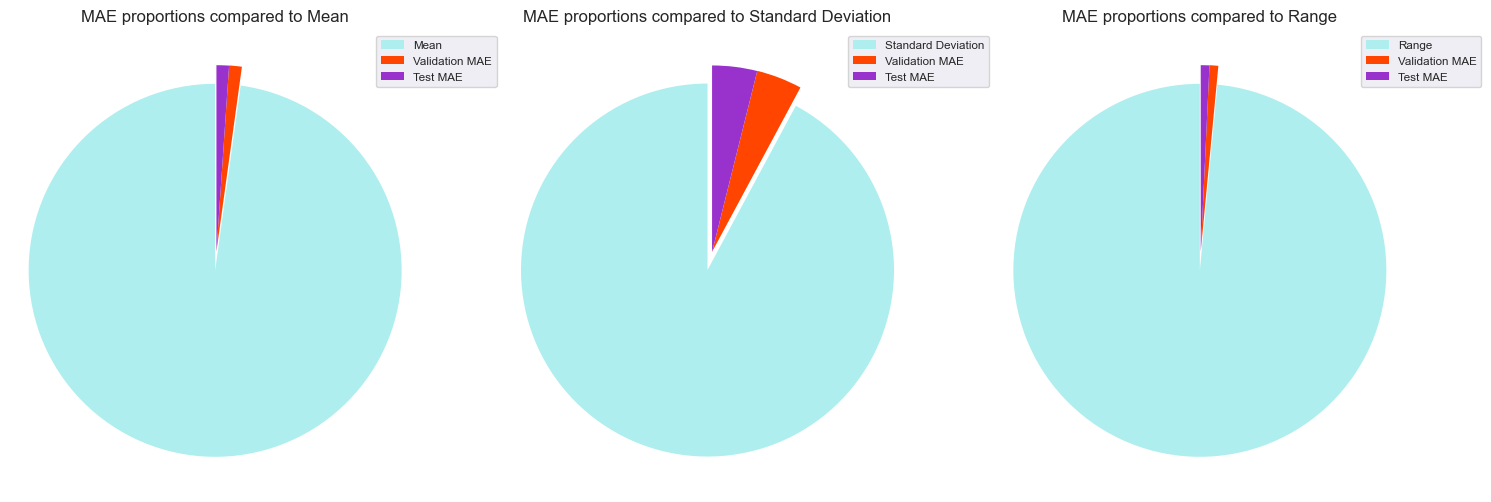

Compared to Mean 				 Compared to Standard Deviation 		 Compared to Range
Validation MAE: 1.12%				 Validation MAE: 4.29%				 Validation MAE: 0.77%
Test MAE: 1.11%					 Test MAE: 4.23%				 Test MAE: 0.76%


In [48]:
# To compare the model MAE to the scale predicted outcome
propMAE_piePlot(actualData_clean['OutgoingThickness'].to_numpy(), bestStat_M1["Model_best val MAE"], testMAE_M1)

From the 3 pie charts above, we can see a comparison between the model's best validation and test MAE with respective to the mean, standard deviation and range of the predicted outcome (Outgoing Thickness).
- We can see that the magnitude of the MAE percentages compared to the mean, standard deviation and range metrics of the predicted outcome are small. This shows that the model's errors are small compared to the general scale of the predicted outcome. 
    - MAE compared to the mean is an indication of the magnitude of the model's average errors and in this case, both the validation and test MAEs are small. This shows that the average error across the predicted outcomes is small.
    - MAE compared to the standard deviation is an indication of the magnitude of the model's errors with respect to the variability (dispersion) in the data and in this case, both the validation and test MAEs are small. This shows that the model is able to generalize well to the dispersion in the predicted outcome.
    - MAE compared to the range is an indication of the magnitude of the model's errors with respect to the overall spread of the data and in this case, both the validation and test MAEs are small. This shows that the model is capable of predicting the outcomes well despite the presence of outliers (as indicated in the box plot earlier).
    
- We can also observe a consistent performance of the model in the validation and test sequences since the plotted portions of the MAEs are equal. This further proves that the model is neither over fitting nor under fitting to the actual dataset.

In [49]:
def modelTrue_vsPredvalue(predValue, trueValue):
    # Experiment prediction error threshold set at (+/-) 50 microns from actual value
    predThresh = 50
    # Absolute difference between predicted and true values (residuals)
    diff = np.abs(trueValue - predValue)
    sc = plt.scatter(trueValue, predValue, c=diff, cmap='crest', marker='o', edgecolors='black', linewidths=0.18)
    plt.xlabel("True test values")
    plt.ylabel("Predicted test values")
    plt.title("Outgoing Thickness true vs predicted test values")
    # Plotting a regression line
    lims = [np.min([plt.gca().get_xlim(), plt.gca().get_ylim()]), np.max([plt.gca().get_xlim(), plt.gca().get_ylim()])]
    plt.gca().plot(lims, lims, 'k--', alpha=0.7, zorder=0)
    cbar = plt.colorbar(sc, location='right', drawedges = True, spacing = 'proportional')
    cbar.set_label('Absolute difference (microns)')
    
    # Displaying residuals statistics
    diffCount = len(diff)
    diffMean = diff.mean()
    diffStd = diff.std()
    diffMin = diff.min()
    diff25Q1 = np.percentile(diff, 25)
    diff50Q2 = np.percentile(diff, 50)
    diff75Q3 = np.percentile(diff, 75)
    diffMax = diff.max()
    diffBound_ctr = 0
    
    # Counting the number of predictions greater than the error threshold
    for error in diff:
        if error > predThresh: 
            diffBound_ctr += 1
            
    # POB -> number of Predictions Outside acceptable error Bound
    resDiff_Stat  = "Residual Stats" \
        "\n" + '-'*20 + "\n" \
        f"Count: {diffCount}\n" \
        f"Mean: {diffMean:.2f}\n" \
        f"Std: {diffStd:.2f}\n" \
        f"Min: {diffMin:.2f}\n" \
        f"25%: {diff25Q1:.2f}\n" \
        f"50%: {diff50Q2:.2f}\n" \
        f"75%: {diff75Q3:.2f}\n" \
        f"Max: {diffMax:.2f}\n" \
        f"POB: {diffBound_ctr:.0f}"
   
    plt.text(0.86, 0.045, resDiff_Stat, fontsize = 'small', bbox = dict(facecolor=plt.gca().get_facecolor(), alpha=0.8, edgecolor='black'),
            transform=plt.gca().transAxes, ha='center', va='bottom')    
    plt.show()
    
    return diffBound_ctr

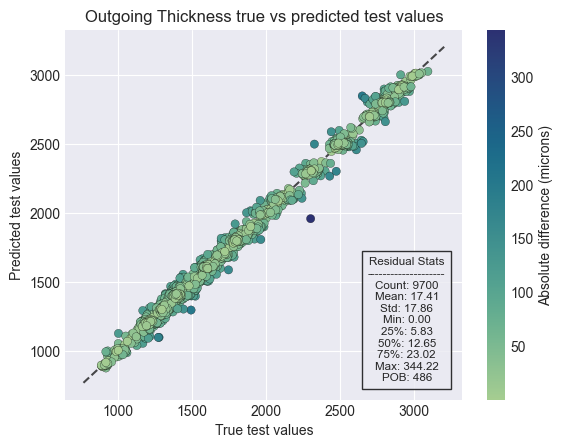

In [50]:
# To plot the predicted vs true outcomes
M1Sample_predThreshCount = modelTrue_vsPredvalue(Yact_testTensor.numpy(), testPred_M1)

From the plot above, we can see a scatter plot distribution between the predicted and actual outcomes. The diagonal line (line of fit) represents the ideal set of points such that the difference between the predicted and the true values is minimum (in this case 0); therefore the closer the points are to the line, the better. The lighter colors fit closer to the line of fit and indicate the closeness in the model predictions between the actual and predicted values while the darker colors indicate a larger difference between the predicted and actual (true) values.
(Note: This line is not an ANN's regression line, but rather a visualization of a diagonal line and is not an indication of the linearity of the regression process.)
- We can see that a large proportion of the points are light green colored and are close to the line of fit. This indicates that the model is able to consistently predict values which are close to the true values and this resonates with the high test R^2 values.
- There are sparse dark colored points and this shows that there are few outliers in this distribution and the error margins (denoted in this case by the MAE scores) are low, and hence the variance in the model is low.
- Most of the points fall on the line of fit and this shows that model is able to fit the data well to the testing processes and is neither over fitting not under fitting to the dataset. Furthermore, due to the lack of systematic deviations (bias) in the predicted outcomes, the model's predicted outcome is representative (and generalizable) to the outcome predicted. 
- In the case of the test R^2 score, since the model achieves a score close to 1.0 (~=0.99), we can say that the model can account for well over 99% of the data observations and with a test MAE of less than 20, it would mean that on average the predicted points are generally less than (+/-) 20 units from the true values.

Thus the control model has a good overall performance on the training dataset (but it takes a long training time to achieve this performance).

### Model to be pre-trained upon: Base model (model trained on the simulation training dataset)

#### Creating the PyTorch dataset tensors and data loader objects for the simulated dataset

In [55]:
# Loading and transforming the datasets into tensors
Xsim_trainTensor = torch.tensor(Xsim_trainStdPCA, dtype=torch.float32)
Xsim_valTensor = torch.tensor(Xsim_valStdPCA, dtype=torch.float32)
# Converting series into numpy array and reshaping to (n, 1)
Ysim_trainTensor = torch.tensor(Ysim_train.to_numpy(), dtype=torch.float32).unsqueeze(1)
Ysim_valTensor = torch.tensor(Ysim_val.to_numpy(), dtype=torch.float32).unsqueeze(1)

print("Simulated training set tensor sizes")
print("Xtrain:", Xsim_trainTensor.size(), " Ytrain:", Ysim_trainTensor.size())
print("\nSimulated validation set tensor sizes")
print("Xval:", Xsim_valTensor.size(), " Yval:", Ysim_valTensor.size())

# Creating train and validation torch datasets
SimTrain_torchSet = TensorDataset(Xsim_trainTensor, Ysim_trainTensor)
SimVal_torchSet = TensorDataset(Xsim_valTensor, Ysim_valTensor)

# Using same batch sizes
SimTrain_torchLoad = DataLoader(SimTrain_torchSet, batch_size=trainBatchSize, shuffle=True)
SimVal_torchLoad = DataLoader(SimVal_torchSet, batch_size=val_testBatchSize, shuffle=False)
print("\nNumber of batches created")
print("Train:", len(SimTrain_torchLoad), "   Validation:", len(SimVal_torchLoad))

Simulated training set tensor sizes
Xtrain: torch.Size([157641, 21])  Ytrain: torch.Size([157641, 1])

Simulated validation set tensor sizes
Xval: torch.Size([17516, 21])  Yval: torch.Size([17516, 1])

Number of batches created
Train: 4927    Validation: 18


#### Defining the base model architecture

In [56]:
# Using the same control model hyperparameters
inputDimension = 21
hiddenDimension = [35, 28, 24, 15]
outputDimension = 1
activationFunction = F.relu
learnRate = 1e-3
# L2 regularization strength
weightDecay = 1e-4

# Instantiating the base model and moving it to GPU
Sim_baseModel = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)
# Initializing the weights
Sim_baseModel.init_WeightBias()
# Loss function
criterion = nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(Sim_baseModel.parameters(), lr = learnRate, weight_decay = weightDecay)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(Sim_baseModel)
print(summary(Sim_baseModel, input_size=(trainBatchSize, Xsim_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         True
├─ModuleList: 1-1                        --              --              --                   --         True
│    └─Linear: 2-1                       [32, 21]        [32, 35]        770              26.88%         True
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29%      

In [57]:
# Visualize (and view the weights and biases of) the untrained model (uncomment the last line)
model_FileName = 'Model_untrain_WB/baseModel_untrain.onnx'
Sim_baseModel_CPU = Sim_baseModel.to('cpu')
torch.onnx.export(Sim_baseModel_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Training the base model on the simulated dataset

In [58]:
# Move the model to GPU
Sim_baseModel = Sim_baseModel.to(device)
# To train the base model
trainTime_bM, trained_bM, bestStat_bM, history_bM = train_NNRegModel(
     Sim_baseModel, 
     SimTrain_torchLoad, 
     SimVal_torchLoad, 
     optimizer, 
     criterion, 
     device, 
     epochs=500, 
     patience=20
)

Epoch [1/500] ==> Train Loss: 150415.1613, Validation Loss: 18181.0758, Validation MAE: 99.6429, Validation R^2: 0.9015

Epoch [20/500] ==> Train Loss: 2934.7238, Validation Loss: 2803.5971, Validation MAE: 38.9124, Validation R^2: 0.9848
Epoch [40/500] ==> Train Loss: 2447.4956, Validation Loss: 2407.3356, Validation MAE: 35.2999, Validation R^2: 0.9870
Epoch [60/500] ==> Train Loss: 2180.8560, Validation Loss: 2137.3569, Validation MAE: 33.3664, Validation R^2: 0.9884
Epoch [80/500] ==> Train Loss: 1983.7867, Validation Loss: 1861.9291, Validation MAE: 31.1322, Validation R^2: 0.9899
Epoch [100/500] ==> Train Loss: 1826.7108, Validation Loss: 2264.9008, Validation MAE: 35.9200, Validation R^2: 0.9877

Epoch [120/500] ==> Train Loss: 1697.2072, Validation Loss: 1742.9146, Validation MAE: 30.0066, Validation R^2: 0.9906
Epoch [140/500] ==> Train Loss: 1633.1743, Validation Loss: 1637.9344, Validation MAE: 29.3848, Validation R^2: 0.9911

Early stopping triggered. Training halted.

Trai

In [59]:
# Visualize (and view the weights and biases of) the trained model (uncomment the last line)
model_FileName = 'Model_train_WB/baseModel_train.onnx'
trained_bM_CPU = trained_bM.to('cpu')
torch.onnx.export(trained_bM_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Predicting actual data using the base model (trained on the simulated dataset)

In [60]:
# To evaluate the model's performance on the actual data test set
trained_bM = trained_bM.to(device)
testTime_bM, testPred_bM, testMAE_bM, testR2S_bM = predict_NNRegModel(trained_bM, ActTest_torchLoad, device)

Prediction completed in 0.14 seconds.
--------------------------------------------------------------------------------------------------------------------------
Test MAE: 531.9975 || Test R^2: -1.5752
--------------------------------------------------------------------------------------------------------------------------


#### Visualizing the base model results

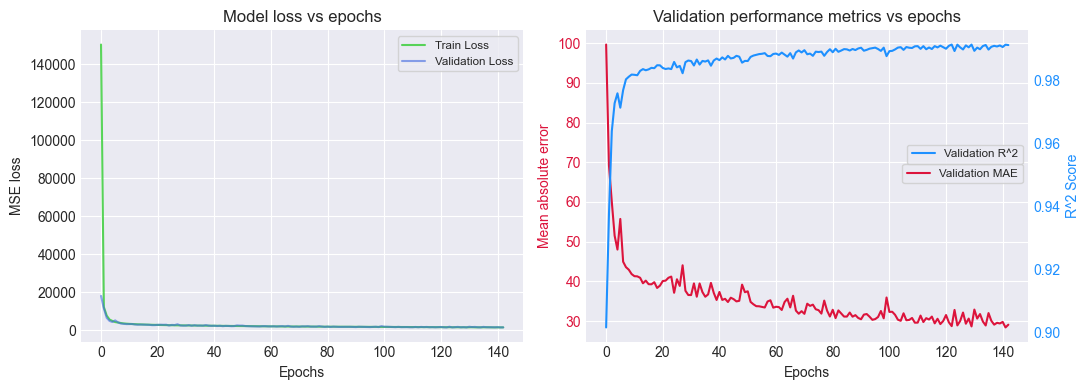

In [61]:
ModelLoss_MAE_R2S_epochPlot(history_bM['Model_history train loss'],
                           history_bM['Model_history val loss'],
                           history_bM['Model_history val MAE'],
                           history_bM['Model_history val R2S'])

From the above 2 plots, we can see the trend of the curves for the training/validation loss and the model performance metrics with respect to the number of epochs taken. 
- As depicted from the model loss curves, there is a general decreasing trend for the training and validation loss curves which shows that as the number of epochs increases, the losses keep decreasing. This shows that the base model is converging to a solution.
- Furthermore, from the model performance metric curves, we can see that MAE keeps decreasing (trending towards 0) with the number of epochs while the R^2 score keeps increasing (trending towards 1) as the epochs increase. This shows that the base model is capable of generalizing well to the simulated validation set.
- From the plots above, the model does not appear to over fit or under fit, as the loss curves decrease significantly and there is no increasing trend. Due to the large scale of the MSE loss, the curves appear to plateau but this is not the case, as shown in the plots below. Additionally, the MAE and R^2 plots keep decreasing and increasing respectively thus indicating that model is not under fitting to the validation dataset, and is able to capture the underlying regression trends.  

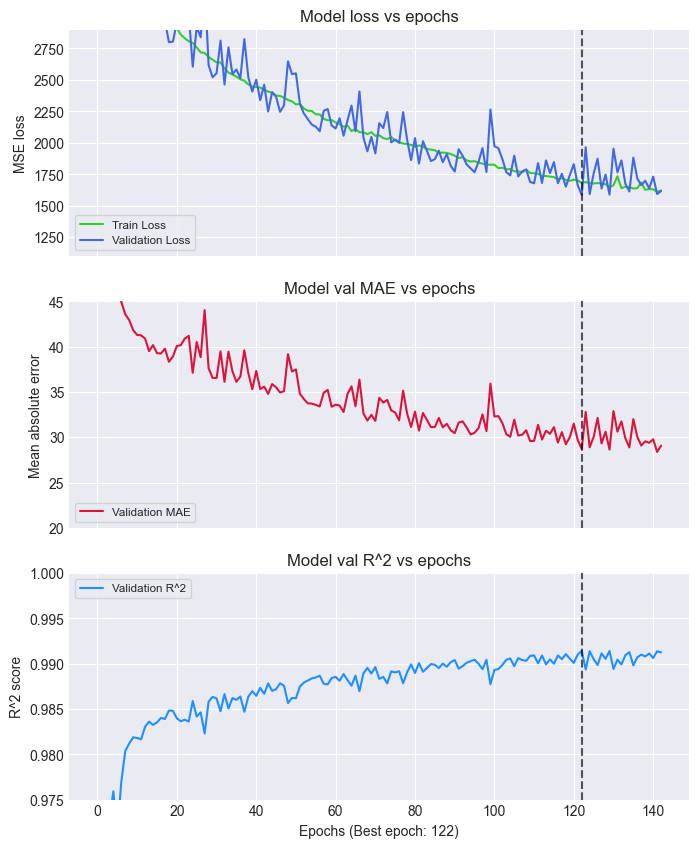

In [62]:
zoomModelLoss_MAE_R2S_epochPlot(history_bM['Model_history train loss'],
                                history_bM['Model_history val loss'],
                                history_bM['Model_history val MAE'],
                                history_bM['Model_history val R2S'], 
                                bestStat_bM['Model_best epoch'], 
                                [1100, 2900], 
                                [20, 45], 
                                [0.975, 1])

Due to the varying scales of the MSE, MAE and R^2 metrics, separate zoomed plots were created to show the underlying trends in the curves. With the peaks in the validation loss curves, the corresponding changes can also be observed in the validation MAE and R^2 plots. 
- The vertical line plotted in each plot, denotes the best epoch (with the lowest validation loss) encountered by the model during its training stage. Beyond this point, no significant decrease in the validation loss was found by the model and hence the early stopping criterion was triggered.
- The decreasing loss and MAE curve trends and increasing R^2 score curve trends reinforce the previous observations about the model performance and thus indicate that the model is performing well compared to the validation set and there does not appear to be any notable presence of under fitting in the model. The lack of model over fitting is also indicated by the closeness between the best validation and test R^2 scores and thus the control model is able to generalize well even over the test dataset.
- Given the similarity between the simulated and the actual datasets, one can see that a higher magnitude of R^2 score was obtained on the control model and a lesser magnitude R^2 score was obtained on the base model and this can be attributed due to the fact that the base model (like every other model) was trained on the control model hyperparameters to allow for easier comparisons. Hence the base model hyperparameters may not representative of the global optimum hyperparameters for the base model ANN regression function.
- Regardless of the lack of optimum hyperparameter choices (and other dataset factors), the base model appears to be performing well against the simulated dataset and has converged to a generalizable solution for the simulated dataset without appearing to over fit or under fit (as seen from the validation MAE and R^2 metrics).

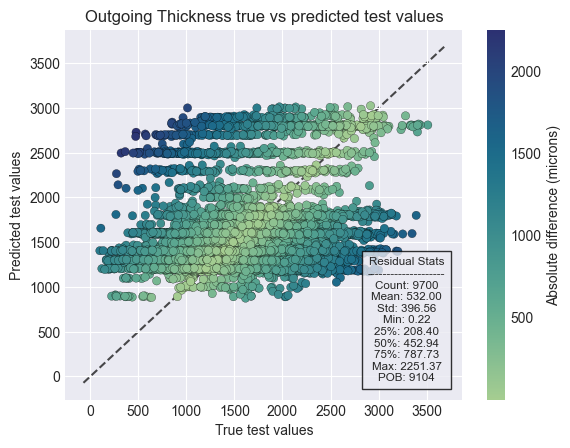

In [63]:
bMSample_predThreshCount = modelTrue_vsPredvalue(Yact_testTensor.numpy(), testPred_bM)

From the plot above, we can see a scatter plot distribution between the predicted and actual outcomes. The diagonal line (line of fit) represents the ideal set of points such that the difference between the predicted and the true values is minimum (in this case 0); therefore the closer the points are to the line, the better. The lighter colors fit closer to the line of fit and indicate the closeness in the model predictions between the actual and predicted values while the darker colors indicate a larger difference between the predicted and actual (true) values.
(Note: This line is not an ANN's regression line, but rather a visualization of a diagonal line and is not an indication of the linearity of the regression process.)
- We can see that a lesser proportion (as compared to the plot of the control model) of the points are light green colored and are close to the line of fit. This indicates that the model is not able to consistently predict test values (from the actual dataset) which are close to the true values and this resonates with the lower test R^2 values.
- There are more dark colored points and this shows that there are many outliers in this distribution and the error margins (denoted in this case by the MAE scores) are higher, and hence the variance in the model is higher than the control model.
- Many of the points do not fall on the line of fit and this shows that model is not able to fit the actual data well to the testing processes (given that it has knowledge only of the simulated dataset). Furthermore, there are systematic deviations (bias) in the predicted outcomes, and the base model's predicted outcome is not representative (and not generalizable) to the outcome predicted from the actual dataset. 
- In the case of the test R^2 score, while the base model achieves a score close to 1.0 (~= 0.94), this score is achieved only on account of the similarity between the simulated and the actual datasets. While the base model can account for 94% of the data observations (from the actual dataset) and with a test MAE of greater than 50, it would mean that on average the predicted points are more than (+/-) 50 units from the true values. Given the high scale of performance metrics attainable (as seen from the control model), the values returned from the base model are sub-par and indicate a poor performance of the base model in generalizing to actual test dataset.
- On the contrary, the base model performs significantly well on the simulated dataset by achieving validation R^2 scores of greater than 0.99 and validation MAE of less than 20 and this shows that the base model performs well on the simulated dataset, but when given a new dataset (despite the similarity), the base model struggles to achieve good scores. This shows that the features learned by the base model from the simulation dataset are not enough to represent the underlying patterns in the actual dataset.
- In fact, this observation is expected from ANNs (and other ML and DL models), since these models can perform well only on the dataset on which it has been trained upon. The model's perspective and performance is highly localized to the dataset it was trained upon and when presented with a similar (but unique) dataset, it under performs on this new dataset. Training the model again from scratch can be expensive as already seen during the experiments given how long each model takes to train and this is driving force behind transfer learning (TL); to create models that take the knowledge gained from one (or many) source tasks and apply this knowledge while learning a similar (but unique) task so as to gain a performance headstart and requiring lesser computational resources. This ideology is especially and beneficial (than training from scratch) as the number of features in the dataset task increase.

Thus the base model has a good overall performance on the simulated training dataset and makes an ideal model to be designated as the *pre-trained* model upon which the TL models will be built upon.

#### Saving the base model weights and biases (to be used for pre-training the TL models)

In [64]:
# Saving the base model weights and biases
torch.save(trained_bM.state_dict(), "SimPTrain_bModel_weight_bias.pth")

# Saving the base model architecture and other hyperparameters
preTrainSave_modelInfo = {
    "inputDimension": inputDimension,
    "hiddenDimension": hiddenDimension,
    "outputDimension": outputDimension,
    "activationFunction": "relu",
    "learnRate": learnRate,
    "weightDecay": weightDecay
}
with open("SimPTrain_bModel_arch.json", 'w') as outfile:
    json.dump(preTrainSave_modelInfo, outfile)

### (TL) Model 2: *Frozen* model approach (TL model built upon the frozen lower layers of the base model) (similar to the CNN feature extraction method)

This model is built upon the lower layers obtained from the base model (pre-trained on the simulated dataset) while the upper layers of the model are trainable newly created layers trained upon the actual dataset. The reasoning behind this model is that due to the similarity between the simulated and actual datasets, the lower layers of the base model have effectively captured features that can be generalizable to the actual dataset and hence new upper layers are added to capture the specifics of the actual dataset using the general knowledge obtained by once training upon the simulated dataset. The process of freezing the base layers is done to ensure that the prior simulation knowledge obtained is not lost while training the model on the actual dataset. This will be similar to the case of building a fixed simulated dataset feature extractor to which new layers are added and these new layers will adapted to the actual dataset.

The exact ratio and combinations of layers to be frozen and newly added layers that can be trained, the learning rates to be used, the hyperparameters chosen all determine the feasibility and performance of this model; which is in turn subject to experimentation. Furthermore, multiple variations of the freezing base layers exist, for example, instead of adding new layers, the upper layers of the model can be taken from the base model as well and trained on the actual dataset, the learning rates of these trainable layers can be increased or decreasing accordingly to speed up the learning process or to not disturb the underlying source (in this case the simulated dataset) data (and this is useful if the source and target datasets are very similar to each other); there exists countless variants of freezing layers that exist in practice.

Consequently, we will be only focusing on one variant of a frozen model approach. The lower layers (27% of the layers and this comprises of layer 0 of the base model) of this model are obtained from the base model and frozen (the weights and biases of these layers cannot be updated). The remaining upper layers (73%, since we want to keep the same architecture as defined in the control model) will be new fresh layers initialized with the He initializer and then trained upon the actual dataset and the model performance will be subsequently evaluated. The learning rate and the loss function for this model will be the same as defined in the base and control models. 

#### Loading the base pre-trained model and defining the frozen TL model 2

In [68]:
# Loading the base model architecture and hyperparameters
with open("SimPTrain_bModel_arch.json", 'r') as infile:
    preTrainLoad_modelInfo = json.load(infile)

# Defining the base model hyperparameters for the model
inputDimension = preTrainLoad_modelInfo["inputDimension"]
hiddenDimension = preTrainLoad_modelInfo["hiddenDimension"]
outputDimension = preTrainLoad_modelInfo["outputDimension"]
activationFunction = F.relu if preTrainLoad_modelInfo["activationFunction"]=="relu" else None
learnRate = preTrainLoad_modelInfo["learnRate"]
weightDecay = preTrainLoad_modelInfo["weightDecay"]
# Defining the layers to be frozen
id_layersFreeze = [0]
# Defining the new layer indices to be created
id_newLayers = [1, 2, 3, 4]

# Creating the model
Act_TL_frzModel2 = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)

# Loading the base model weights into the model
Act_TL_frzModel2.load_state_dict(torch.load("SimPTrain_bModel_weight_bias.pth"))

<All keys matched successfully>

#### Freezing the base layers of the frozen model

In [69]:
# Freezing the base layers of the frozen model (since the frozen model has been initialized with the base model's weights and biases)
for i, layer in enumerate(Act_TL_frzModel2.layers):
    if i in id_layersFreeze:
        for param_WB in layer.parameters():
            param_WB.requires_grad = False

#### Defining new upper layers for the frozen model and combining them to the frozen model

In [70]:
# Replacing the frozen model's upper layers with new layers
for i in range(len(id_newLayers)):
    if id_newLayers[i] == id_newLayers[-1]:
        Act_TL_frzModel2.layers[id_newLayers[i]] = nn.Linear(hiddenDimension[id_newLayers[i]-1], outputDimension).to(device)
    else:
        Act_TL_frzModel2.layers[id_newLayers[i]] = nn.Linear(hiddenDimension[id_newLayers[i]-1], hiddenDimension[id_newLayers[i]]).to(device)
# Initializing the new layers weights with He initializer and bias with zero
for i in range(len(id_newLayers)):
    nn.init.kaiming_uniform_(Act_TL_frzModel2.layers[id_newLayers[i]].weight, nonlinearity='relu')
    nn.init.zeros_(Act_TL_frzModel2.layers[id_newLayers[i]].bias)
    
# Loss function
criterion = nn.MSELoss()
# Optimizer (keeping the same control model learning rate of 1e-2)
optimizer = torch.optim.Adam(Act_TL_frzModel2.parameters(), lr = learnRate, weight_decay = weightDecay)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(Act_TL_frzModel2)
print(summary(Act_TL_frzModel2, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         Partial
├─ModuleList: 1-1                        --              --              --                   --         Partial
│    └─Linear: 2-1                       [32, 21]        [32, 35]        (770)            26.88%         False
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29

In [71]:
# Visualize (and view the weights and biases of) the untrained model (uncomment the last line)
model_FileName = 'Model_untrain_WB/M2_frzModel_untrain.onnx'
Act_TL_frzModel2_CPU = Act_TL_frzModel2.to('cpu')
torch.onnx.export(Act_TL_frzModel2_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Training the frozen model on the actual dataset

In [72]:
# Move the model to GPU
Act_TL_frzModel2 = Act_TL_frzModel2.to(device)
# To train the model
trainTime_M2, trained_M2, bestStat_M2, history_M2 = train_NNRegModel(
     Act_TL_frzModel2, 
     ActTrain_torchLoad, 
     ActVal_torchLoad, 
     optimizer, 
     criterion, 
     device, 
     epochs=500, 
     patience=20
)

Epoch [1/500] ==> Train Loss: 172236.1244, Validation Loss: 20859.2262, Validation MAE: 101.6178, Validation R^2: 0.8789

Epoch [20/500] ==> Train Loss: 4649.2162, Validation Loss: 4486.5705, Validation MAE: 46.4601, Validation R^2: 0.9739
Epoch [40/500] ==> Train Loss: 3535.8545, Validation Loss: 3665.9504, Validation MAE: 41.0493, Validation R^2: 0.9787
Epoch [60/500] ==> Train Loss: 2888.9635, Validation Loss: 3022.2729, Validation MAE: 36.4844, Validation R^2: 0.9824
Epoch [80/500] ==> Train Loss: 2474.4798, Validation Loss: 2486.6588, Validation MAE: 34.0456, Validation R^2: 0.9856
Epoch [100/500] ==> Train Loss: 2213.0032, Validation Loss: 3071.0843, Validation MAE: 39.5025, Validation R^2: 0.9822

Epoch [120/500] ==> Train Loss: 2088.8311, Validation Loss: 2865.8247, Validation MAE: 38.6921, Validation R^2: 0.9833
Epoch [140/500] ==> Train Loss: 1997.9578, Validation Loss: 2506.7208, Validation MAE: 33.0734, Validation R^2: 0.9854
Epoch [160/500] ==> Train Loss: 1869.0667, Valid

In [73]:
# Visualize (and view the weights and biases of) the trained model (uncomment the last line)
model_FileName = 'Model_train_WB/M2_frzModel_train.onnx'
trained_M2_CPU = trained_M2.to('cpu')
torch.onnx.export(trained_M2_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Predicting actual data using the frozen model

In [74]:
# To evaluate the model's performance on the actual data test set
trained_M2 = trained_M2.to(device)
testTime_M2, testPred_M2, testMAE_M2, testR2S_M2 = predict_NNRegModel(trained_M2, ActTest_torchLoad, device)

Prediction completed in 0.15 seconds.
--------------------------------------------------------------------------------------------------------------------------
Test MAE: 28.3864 || Test R^2: 0.9900
--------------------------------------------------------------------------------------------------------------------------


#### Visualizing the frozen model results

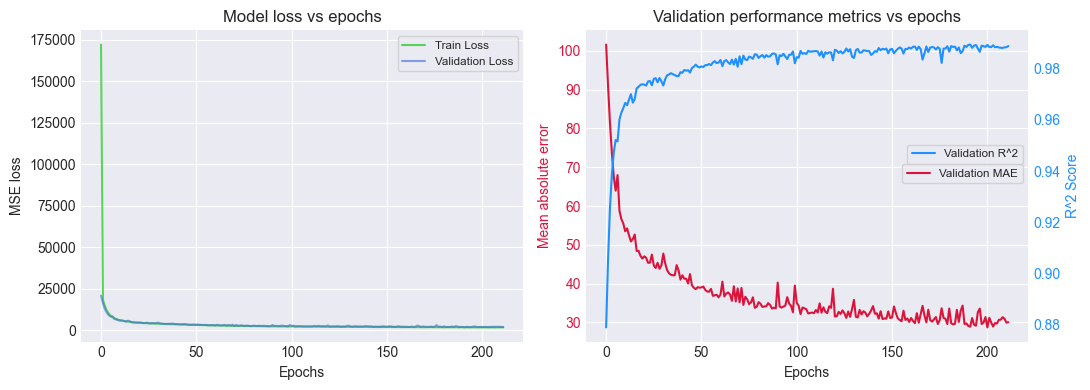

In [75]:
# Plotting the model losses and metrics vs epochs
ModelLoss_MAE_R2S_epochPlot(history_M2['Model_history train loss'],
                           history_M2['Model_history val loss'],
                           history_M2['Model_history val MAE'],
                           history_M2['Model_history val R2S'])

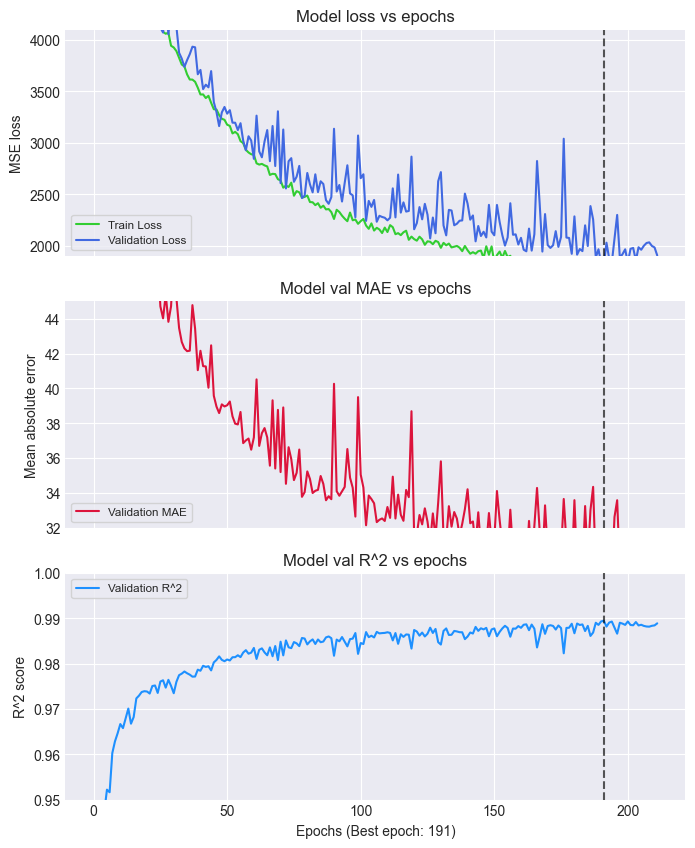

In [76]:
zoomModelLoss_MAE_R2S_epochPlot(history_M2['Model_history train loss'],
                                history_M2['Model_history val loss'],
                                history_M2['Model_history val MAE'],
                                history_M2['Model_history val R2S'], 
                                bestStat_M2['Model_best epoch'], 
                                [1900, 4100], 
                                [32, 45], 
                                [0.950, 1])

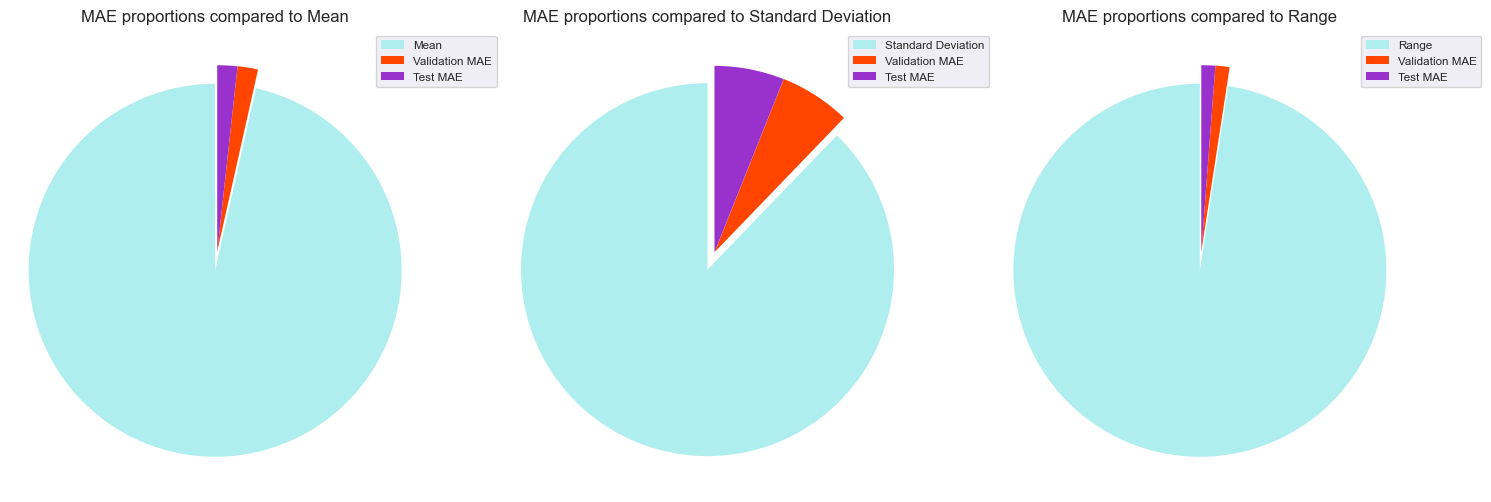

Compared to Mean 				 Compared to Standard Deviation 		 Compared to Range
Validation MAE: 1.84%				 Validation MAE: 7.02%				 Validation MAE: 1.26%
Test MAE: 1.80%					 Test MAE: 6.89%				 Test MAE: 1.24%


In [77]:
# To compare the model MAE to the scale of the predicted outcome
propMAE_piePlot(actualData_clean['OutgoingThickness'].to_numpy(), bestStat_M2["Model_best val MAE"], testMAE_M2)

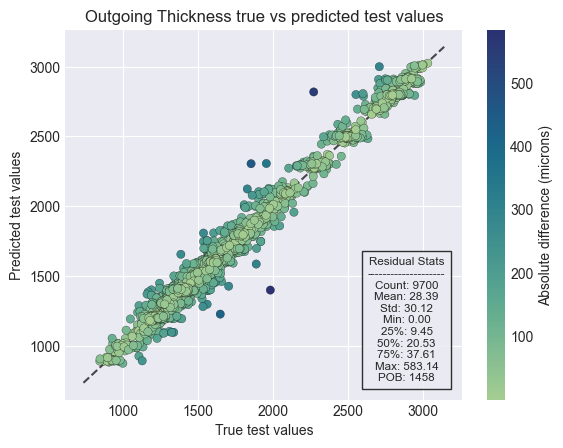

In [78]:
M2Sample_predThreshCount = modelTrue_vsPredvalue(Yact_testTensor.numpy(), testPred_M2)

### (TL) Model 3: Soft-start model approach (TL model built upon all the layers of the base model additionally trained on the actual dataset with a lower learning rate) (similar to the method proposed by Tercan et al. (2018))

#### Loading the base pre-trained model

In [79]:
# Loading the base model architecture and hyperparameters
with open("SimPTrain_bModel_arch.json", 'r') as infile:
    preTrainLoad_modelInfo = json.load(infile)

# Defining the base model hyperparameters for the frozen model
inputDimension = preTrainLoad_modelInfo["inputDimension"]
hiddenDimension = preTrainLoad_modelInfo["hiddenDimension"]
outputDimension = preTrainLoad_modelInfo["outputDimension"]
activationFunction = F.relu if preTrainLoad_modelInfo["activationFunction"]=="relu" else None
learnRate = preTrainLoad_modelInfo["learnRate"]
weightDecay = preTrainLoad_modelInfo["weightDecay"]

#### Defining the soft start model architecture

In [80]:
# Creating the soft start model
Act_TL_sftModel3 = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)

# Loading the base model weights into the model
Act_TL_sftModel3.load_state_dict(torch.load("SimPTrain_bModel_weight_bias.pth"))

# Reduce the learning rate by factor of 10 (common approach, other values can be experimented)
tune_learnRate = learnRate * 1e-1

# Loss function
criterion = nn.MSELoss()
# Optimizer (keeping the same base model learning rate of 1e-2)
optimizer = torch.optim.Adam(Act_TL_sftModel3.parameters(), lr = tune_learnRate, weight_decay = weightDecay)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(Act_TL_sftModel3)
print(summary(Act_TL_sftModel3, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         True
├─ModuleList: 1-1                        --              --              --                   --         True
│    └─Linear: 2-1                       [32, 21]        [32, 35]        770              26.88%         True
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29%      

In [81]:
# Visualize (and view the weights and biases of) the untrained model (uncomment the last line)
model_FileName = 'Model_untrain_WB/M3_sftModel_untrain.onnx'
Act_TL_sftModel3_CPU = Act_TL_sftModel3.to('cpu')
torch.onnx.export(Act_TL_sftModel3_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Training the soft start model on the actual dataset

In [82]:
# Move the model to GPU
Act_TL_sftModel3 = Act_TL_sftModel3.to(device)
# To train the model
trainTime_M3, trained_M3, bestStat_M3, history_M3 = train_NNRegModel(
     Act_TL_sftModel3, 
     ActTrain_torchLoad, 
     ActVal_torchLoad, 
     optimizer, 
     criterion, 
     device, 
     epochs=500, 
     patience=20
)

Epoch [1/500] ==> Train Loss: 115363.4988, Validation Loss: 31247.3448, Validation MAE: 129.6661, Validation R^2: 0.8183

Epoch [20/500] ==> Train Loss: 3559.1395, Validation Loss: 3768.1154, Validation MAE: 41.3242, Validation R^2: 0.9781
Epoch [40/500] ==> Train Loss: 2222.8030, Validation Loss: 2366.4297, Validation MAE: 33.0949, Validation R^2: 0.9862
Epoch [60/500] ==> Train Loss: 1726.7526, Validation Loss: 1884.0912, Validation MAE: 29.5207, Validation R^2: 0.9890
Epoch [80/500] ==> Train Loss: 1444.3773, Validation Loss: 1610.9564, Validation MAE: 27.2442, Validation R^2: 0.9906
Epoch [100/500] ==> Train Loss: 1268.6281, Validation Loss: 1400.4807, Validation MAE: 25.6234, Validation R^2: 0.9919

Epoch [120/500] ==> Train Loss: 1147.7998, Validation Loss: 1297.3014, Validation MAE: 24.7867, Validation R^2: 0.9925
Epoch [140/500] ==> Train Loss: 1054.6773, Validation Loss: 1161.1006, Validation MAE: 23.4662, Validation R^2: 0.9932
Epoch [160/500] ==> Train Loss: 969.4895, Valida

In [83]:
# Visualize (and view the weights and biases of) the trained model (uncomment the last line)
model_FileName = 'Model_train_WB/M3_sftModel_train.onnx'
trained_M3_CPU = trained_M3.to('cpu')
torch.onnx.export(trained_M3_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Predicting actual data using the soft start model

In [84]:
# To evaluate the model's performance on the actual data test set
trained_M3 = trained_M3.to(device)
testTime_M3, testPred_M3, testMAE_M3, testR2S_M3 = predict_NNRegModel(trained_M3, ActTest_torchLoad, device)

Prediction completed in 0.15 seconds.
--------------------------------------------------------------------------------------------------------------------------
Test MAE: 18.2827 || Test R^2: 0.9962
--------------------------------------------------------------------------------------------------------------------------


#### Visualizing the soft start model results

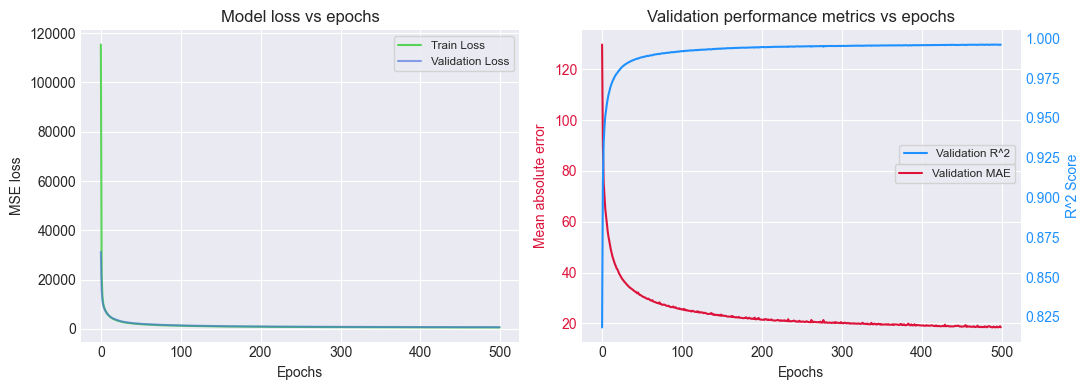

In [85]:
# Plotting the model losses and metrics vs epochs
ModelLoss_MAE_R2S_epochPlot(history_M3['Model_history train loss'],
                           history_M3['Model_history val loss'],
                           history_M3['Model_history val MAE'],
                           history_M3['Model_history val R2S'])

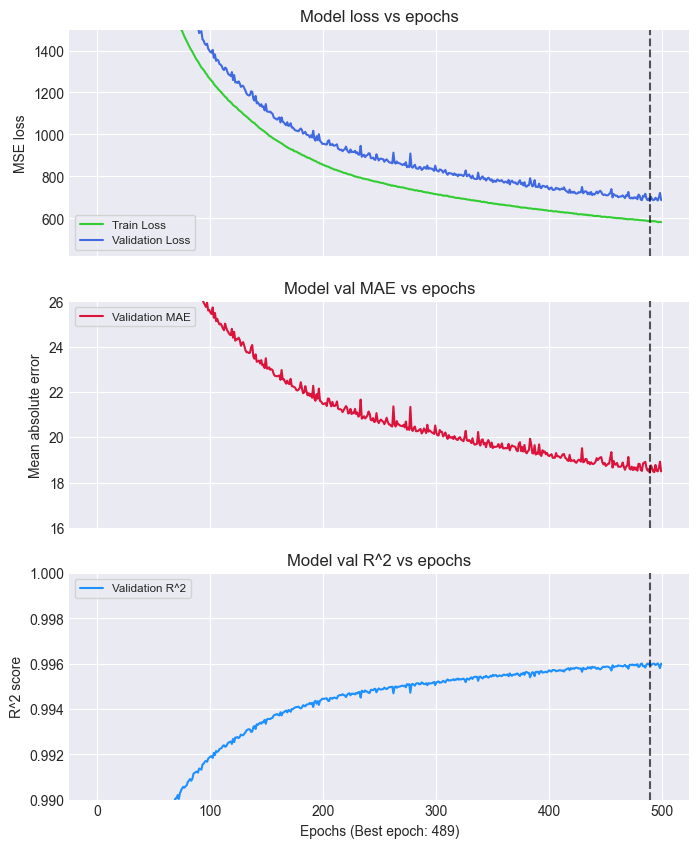

In [86]:
zoomModelLoss_MAE_R2S_epochPlot(history_M3['Model_history train loss'],
                                history_M3['Model_history val loss'],
                                history_M3['Model_history val MAE'],
                                history_M3['Model_history val R2S'], 
                                bestStat_M3['Model_best epoch'], 
                                [420, 1500], 
                                [16, 26], 
                                [0.990, 1])

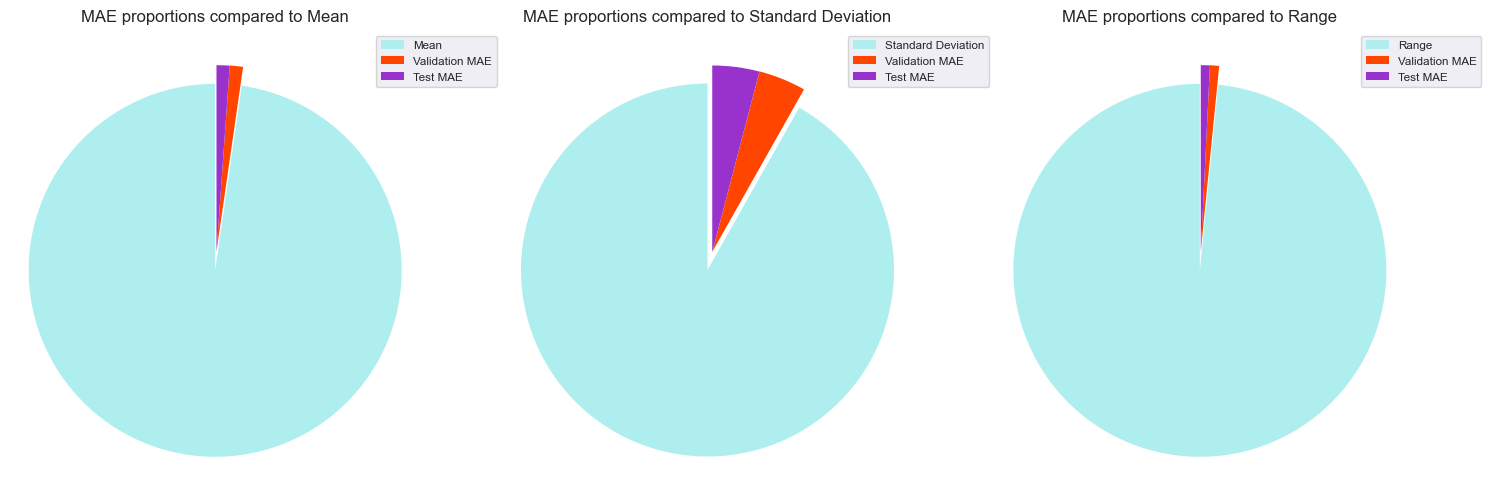

Compared to Mean 				 Compared to Standard Deviation 		 Compared to Range
Validation MAE: 1.17%				 Validation MAE: 4.47%				 Validation MAE: 0.80%
Test MAE: 1.16%					 Test MAE: 4.44%				 Test MAE: 0.80%


In [87]:
# To compare the model MAE to the scale predicted outcome
propMAE_piePlot(actualData_clean['OutgoingThickness'].to_numpy(), bestStat_M3["Model_best val MAE"], testMAE_M3)

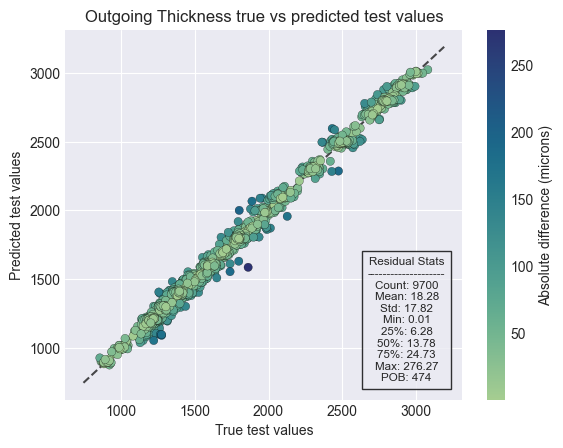

In [88]:
M3Sample_predThreshCount = modelTrue_vsPredvalue(Yact_testTensor.numpy(), testPred_M3)

### (TL) Model 4: Standard fine-tuning model approach (TL model built upon the principle of having new upper layers trained at a higher learning rate while the pre-trained lower layers are trained at a lower learning rate)

#### Loading the base pre-trained model and defining the standard fine tuned TL model 4

In [89]:
# Loading the base model architecture and hyperparameters
with open("SimPTrain_bModel_arch.json", 'r') as infile:
    preTrainLoad_modelInfo = json.load(infile)

# Defining the base model hyperparameters for the standard fine tuned model
inputDimension = preTrainLoad_modelInfo["inputDimension"]
hiddenDimension = preTrainLoad_modelInfo["hiddenDimension"]
outputDimension = preTrainLoad_modelInfo["outputDimension"]
activationFunction = F.relu if preTrainLoad_modelInfo["activationFunction"]=="relu" else None
learnRate = preTrainLoad_modelInfo["learnRate"]
weightDecay = preTrainLoad_modelInfo["weightDecay"]
# Reduce the learning rate by factor of 10 (common approach, other values can be experimented)
tune_learnRate = learnRate * 1e-1
# Defining the lower layers
id_lowerLayers = [0]
# Defining the new upper layer indices to be created
id_upperLayers = [1, 2, 3, 4]

# Creating the standard fine tuned model
Act_TL_stdFTune_Model4 = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)

# Loading the base model weights into the standard fine tuned model
Act_TL_stdFTune_Model4.load_state_dict(torch.load("SimPTrain_bModel_weight_bias.pth"))

<All keys matched successfully>

#### Defining standard fine tuning model architecture with new upper layers

In [90]:
def RplcInitLayer_FineTune(model, newLayer):
    # Replacing the standard fine tuned model's upper layers with new layers
    for i in range(len(newLayer)):
        if newLayer[i] == newLayer[-1]:
            model.layers[newLayer[i]] = nn.Linear(hiddenDimension[newLayer[i]-1], outputDimension).to(device)
        else:
            model.layers[newLayer[i]] = nn.Linear(hiddenDimension[newLayer[i]-1], hiddenDimension[newLayer[i]]).to(device)
    
    # Initializing the new layers weights with He initializer and bias with zero
    for i in range(len(newLayer)):
        nn.init.kaiming_uniform_(model.layers[newLayer[i]].weight, nonlinearity='relu')
        nn.init.zeros_(model.layers[newLayer[i]].bias)
        
# PyTorch models are passed by reference
RplcInitLayer_FineTune(Act_TL_stdFTune_Model4, id_upperLayers)

#### Defining separate learning rates for upper and lower layers

In [91]:
# Function to create seperate parameter groups with different learning rates for lower and upper layers
def optimLayer_learnRate(model, lowLayer, lower_learnRate, upper_learnRate):
    lower_param = []
    upper_param = []
    for i, layer in enumerate(model.layers):
        if i in lowLayer:
            lower_param.extend(list(layer.parameters()))
        else:
            upper_param.extend(list(layer.parameters()))
    # Create the paramter groups for the lower and upper layers
    paramLayer_group = [
        {'params': lower_param, 'lr': lower_learnRate},
        {'params': upper_param, 'lr': upper_learnRate}
    ]
    optimizer = torch.optim.Adam(paramLayer_group, weight_decay = weightDecay)
    return optimizer

In [92]:
# Loss function
criterion = nn.MSELoss()
# Optimizer (keeping the control model learning rate of 1e-2 for upper layers and fine tuned learning rate of
#            1e-3 for lower pre-trained layers)
optimizer = optimLayer_learnRate(Act_TL_stdFTune_Model4, id_lowerLayers, tune_learnRate, learnRate)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(Act_TL_stdFTune_Model4)
print(summary(Act_TL_stdFTune_Model4, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         True
├─ModuleList: 1-1                        --              --              --                   --         True
│    └─Linear: 2-1                       [32, 21]        [32, 35]        770              26.88%         True
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29%      

In [93]:
# Visualize (and view the weights and biases of) the model (uncomment the last line)
model_FileName = 'Model_untrain_WB/M4_StdftuneModel_untrain.onnx'
Act_TL_stdFTune_Model4_CPU = Act_TL_stdFTune_Model4.to('cpu')
torch.onnx.export(Act_TL_stdFTune_Model4_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Training the standard fine tuned model (with different learning rates for upper and lower layers) on the actual dataset
Note: The model is trained on the actual dataset from epoch 0 (the first epoch).

In [94]:
# Move the model to GPU
Act_TL_stdFTune_Model4 = Act_TL_stdFTune_Model4.to(device)
# To train the model
trainTime_M4, trained_M4, bestStat_M4, history_M4 = train_NNRegModel(
     Act_TL_stdFTune_Model4, 
     ActTrain_torchLoad, 
     ActVal_torchLoad, 
     optimizer, 
     criterion, 
     device, 
     epochs=500, 
     patience=20
)

Epoch [1/500] ==> Train Loss: 168805.0232, Validation Loss: 11733.1404, Validation MAE: 76.4366, Validation R^2: 0.9318

Epoch [20/500] ==> Train Loss: 1969.1652, Validation Loss: 2050.6705, Validation MAE: 31.1791, Validation R^2: 0.9881
Epoch [40/500] ==> Train Loss: 1355.0304, Validation Loss: 1321.8244, Validation MAE: 25.1426, Validation R^2: 0.9923
Epoch [60/500] ==> Train Loss: 1126.4183, Validation Loss: 1232.7164, Validation MAE: 24.8682, Validation R^2: 0.9928
Epoch [80/500] ==> Train Loss: 999.6559, Validation Loss: 1115.8165, Validation MAE: 23.7020, Validation R^2: 0.9935
Epoch [100/500] ==> Train Loss: 909.5735, Validation Loss: 1060.6358, Validation MAE: 23.7394, Validation R^2: 0.9938

Epoch [120/500] ==> Train Loss: 844.1905, Validation Loss: 1030.3265, Validation MAE: 23.3811, Validation R^2: 0.9940
Epoch [140/500] ==> Train Loss: 784.2290, Validation Loss: 940.9027, Validation MAE: 21.7140, Validation R^2: 0.9945
Epoch [160/500] ==> Train Loss: 725.0482, Validation L

In [95]:
# Visualize (and view the weights and biases of) the trained model (uncomment the last line)
model_FileName = 'Model_train_WB/M4_StdftuneModel_train.onnx'
trained_M4_CPU = trained_M4.to('cpu')
torch.onnx.export(trained_M4_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Predicting actual data using the standard fine tuned model

In [96]:
# To evaluate the model's performance on the actual data test set
# After phase 2
trained_M4 = trained_M4.to(device)
testTime_M4, testPred_M4, testMAE_M4, testR2S_M4 = predict_NNRegModel(trained_M4, ActTest_torchLoad, device)

Prediction completed in 0.16 seconds.
--------------------------------------------------------------------------------------------------------------------------
Test MAE: 13.9961 || Test R^2: 0.9975
--------------------------------------------------------------------------------------------------------------------------


#### Visualizing the standard fine tuned model results

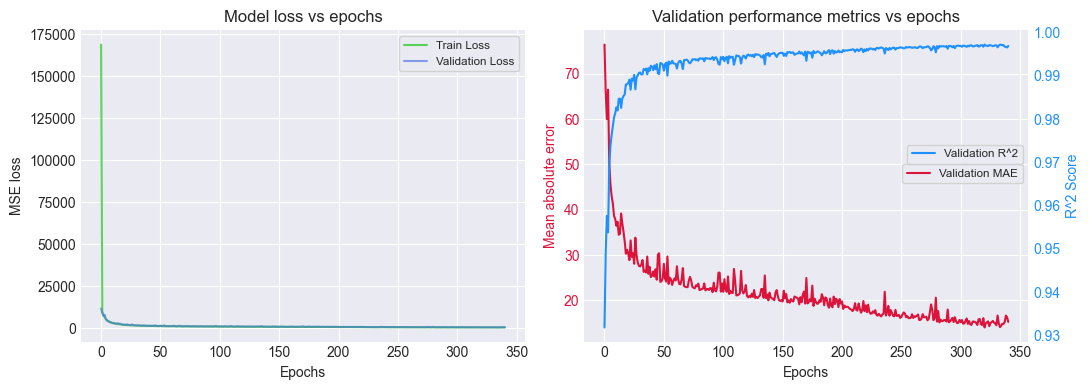

In [97]:
# Plotting the model losses and metrics vs epochs
ModelLoss_MAE_R2S_epochPlot(history_M4['Model_history train loss'],
                           history_M4['Model_history val loss'],
                           history_M4['Model_history val MAE'],
                           history_M4['Model_history val R2S'])

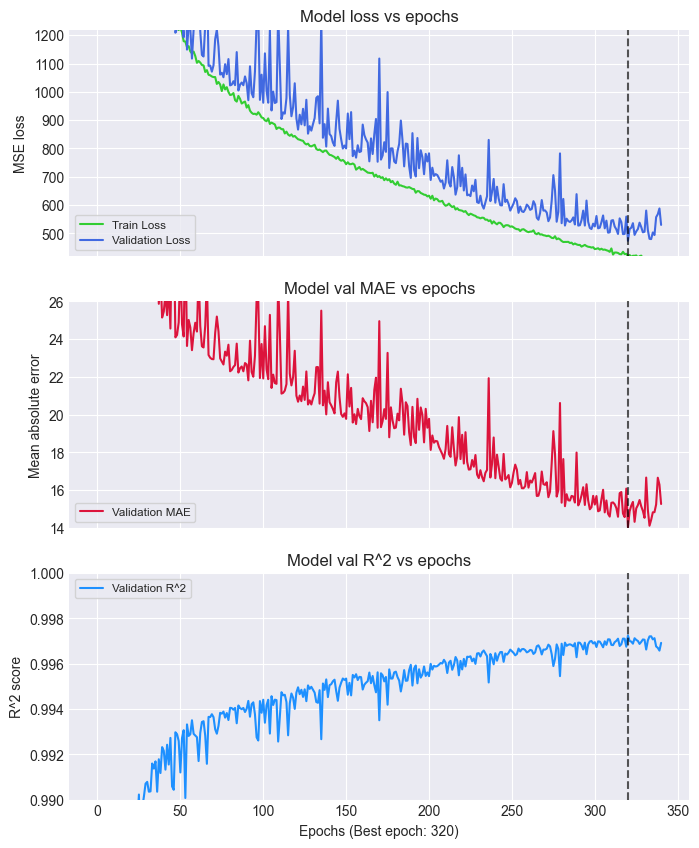

In [98]:
zoomModelLoss_MAE_R2S_epochPlot(history_M4['Model_history train loss'],
                                history_M4['Model_history val loss'],
                                history_M4['Model_history val MAE'],
                                history_M4['Model_history val R2S'], 
                                bestStat_M4['Model_best epoch'], 
                                [420, 1220], 
                                [14, 26], 
                                [0.990, 1])

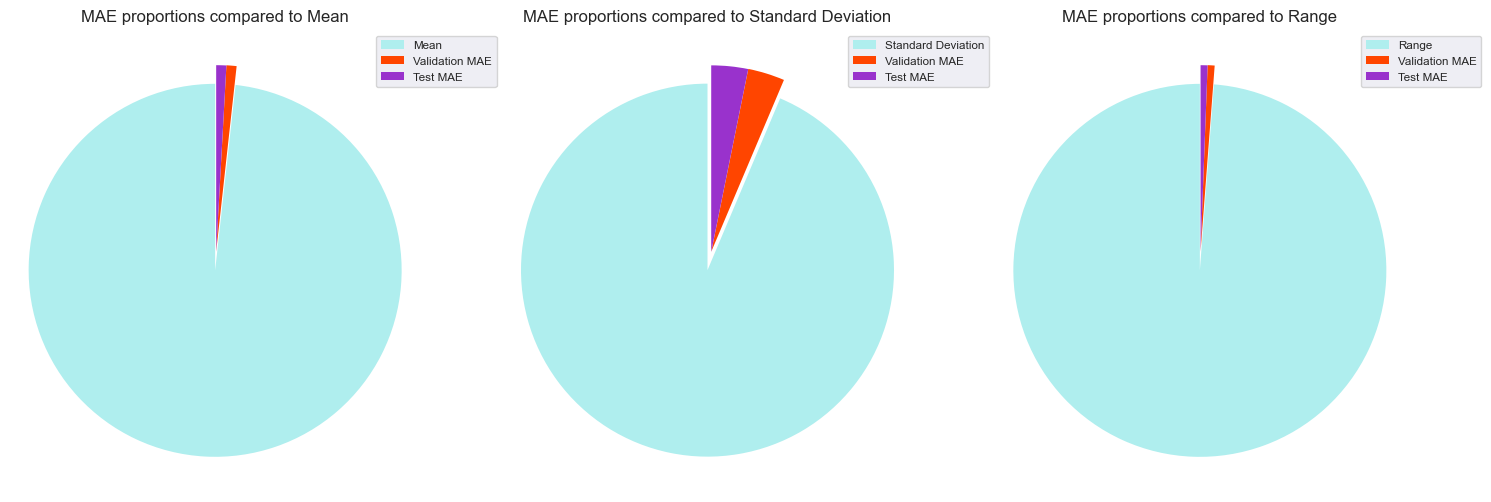

Compared to Mean 				 Compared to Standard Deviation 		 Compared to Range
Validation MAE: 0.89%				 Validation MAE: 3.41%				 Validation MAE: 0.61%
Test MAE: 0.89%					 Test MAE: 3.40%				 Test MAE: 0.61%


In [99]:
# To compare the model MAE to the scale predicted outcome
propMAE_piePlot(actualData_clean['OutgoingThickness'].to_numpy(), bestStat_M4["Model_best val MAE"], testMAE_M4)

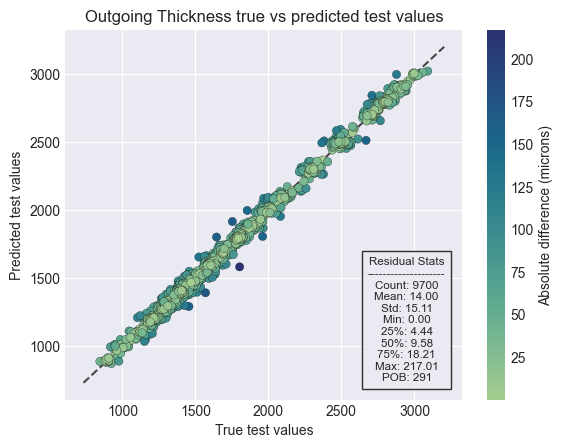

In [100]:
M4Sample_predThreshCount = modelTrue_vsPredvalue(Yact_testTensor.numpy(), testPred_M4)

### (TL) Model 5: Frozen start fine-tuning model approach (TL model built upon the a hybrid of the frozen and soft start model wherein the phase 1 training is like the frozen model and the phase 2 training begins from the best epoch of phase 1 checkpoint, with lower learning rates) (Also can be viewed as warm-starting the soft start training process)

#### Loading the base pre-trained model and defining the frozen start fine tuned TL model 5

In [101]:
# Loading the base model architecture and hyperparameters
with open("SimPTrain_bModel_arch.json", 'r') as infile:
    preTrainLoad_modelInfo = json.load(infile)

# Defining the base model hyperparameters for the frozen start fine tuned model
inputDimension = preTrainLoad_modelInfo["inputDimension"]
hiddenDimension = preTrainLoad_modelInfo["hiddenDimension"]
outputDimension = preTrainLoad_modelInfo["outputDimension"]
activationFunction = F.relu if preTrainLoad_modelInfo["activationFunction"]=="relu" else None
learnRate = preTrainLoad_modelInfo["learnRate"]
# Reduce the learning rate by factor of 10 (common approach, other values can be experimented)
tune_learnRate = learnRate * 1e-1
weightDecay = preTrainLoad_modelInfo["weightDecay"]
# Defining the lower layers
id_lowerLayers = [0]
# Defining the new upper layer indices to be created
id_upperLayers = [1, 2, 3, 4]

# Creating the frozen start fine tuned model
Act_TL_frzFTune_Model5 = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)

# Loading the base model weights into the frozen start fine tuned model
Act_TL_frzFTune_Model5.load_state_dict(torch.load("SimPTrain_bModel_weight_bias.pth"))

<All keys matched successfully>

#### Defining frozen start fine tuning model architecture with frozen base layers

In [102]:
def frzRplcInitLayer_FineTune(model, frozenLayer, newLayer):
    # Freezing the base layers of the standard fine tuned model (since the standard fine tuned model has been initialized with the base model's weights and biases)
    # Defining the layers to be frozen
    for i, layer in enumerate(model.layers):
        if i in frozenLayer:
            for param_WB in layer.parameters():
                param_WB.requires_grad = False
                
    # Replacing the standard fine tuned model's upper layers with new layers
    for i in range(len(newLayer)):
        if newLayer[i] == newLayer[-1]:
            model.layers[newLayer[i]] = nn.Linear(hiddenDimension[newLayer[i]-1], outputDimension).to(device)
        else:
            model.layers[newLayer[i]] = nn.Linear(hiddenDimension[newLayer[i]-1], hiddenDimension[newLayer[i]]).to(device)
    
    # Initializing the new layers weights with He initializer and bias with zero
    for i in range(len(newLayer)):
        nn.init.kaiming_uniform_(model.layers[newLayer[i]].weight, nonlinearity='relu')
        nn.init.zeros_(model.layers[newLayer[i]].bias)

In [103]:
# PyTorch models are passed by reference
frzRplcInitLayer_FineTune(Act_TL_frzFTune_Model5, id_lowerLayers, id_upperLayers)

# Loss function
criterion = nn.MSELoss()
# Optimizer (keeping the same control model learning rate of 1e-2)
optimizer = torch.optim.Adam(Act_TL_frzFTune_Model5.parameters(), lr = learnRate, weight_decay = weightDecay)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(Act_TL_frzFTune_Model5)
print(summary(Act_TL_frzFTune_Model5, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         Partial
├─ModuleList: 1-1                        --              --              --                   --         Partial
│    └─Linear: 2-1                       [32, 21]        [32, 35]        (770)            26.88%         False
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29

In [104]:
# Visualize (and view the weights and biases of) the model with upper layers trainable (uncomment the last line)
model_FileName = 'Model_untrain_WB/M5_frzFTuneModel_ph1untrain.onnx'
Act_TL_frzFTune_Model5_CPU = Act_TL_frzFTune_Model5.to('cpu')
torch.onnx.export(Act_TL_frzFTune_Model5_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Phase 1: Training the frozen start fine tuned model (with base layers frozen) on the actual dataset

In [105]:
# Move the model to GPU
Act_TL_frzFTune_Model5 = Act_TL_frzFTune_Model5.to(device)
phase1_savePTH = 'Model_Checkpoints/M5_ph1_checkPT.pth'
# To train the model
print('[' + '-'*52, "Phase 1 training", '-'*52 + ']')
trainTime_ph1M5, trained_ph1M5, bestStat_ph1M5, history_ph1M5 = train_NNRegModel(
     Act_TL_frzFTune_Model5, 
     ActTrain_torchLoad, 
     ActVal_torchLoad, 
     optimizer, 
     criterion, 
     device, 
     epochs=500, 
     patience=10,
     epoch_StartPT=0,
     checkPT_savePTH=phase1_savePTH
)

[---------------------------------------------------- Phase 1 training ----------------------------------------------------]
Epoch [1/500] ==> Train Loss: 159272.3968, Validation Loss: 22469.5833, Validation MAE: 106.4589, Validation R^2: 0.8695

Epoch [20/500] ==> Train Loss: 5152.8525, Validation Loss: 5564.6971, Validation MAE: 51.0246, Validation R^2: 0.9677
Epoch [40/500] ==> Train Loss: 3745.7923, Validation Loss: 3806.1899, Validation MAE: 41.3708, Validation R^2: 0.9779
Epoch [60/500] ==> Train Loss: 2927.4398, Validation Loss: 3342.9136, Validation MAE: 39.9192, Validation R^2: 0.9806
Epoch [80/500] ==> Train Loss: 2532.0653, Validation Loss: 2883.3210, Validation MAE: 36.9363, Validation R^2: 0.9832
Epoch [100/500] ==> Train Loss: 2376.7796, Validation Loss: 2922.8704, Validation MAE: 36.2051, Validation R^2: 0.9830


Early stopping triggered. Training halted.

Training completed in 14 minutes and 52 seconds.
-------------------------------------------------------------------

#### Unfreezing the base layers of the frozen start fine tuned model (after phase 1) and defining the frozen start fine tuned model architecture for phase 2

In [106]:
# Setting all the layers of the model as trainable
for layer in trained_ph1M5.layers:
    for param_WB in layer.parameters():
        param_WB.requires_grad = True

# Same criterion (MSE loss) and performance metrics (MSE and R^2)
# Optimizer (with reduced learning rate for all the layers) will be created from the saved checkpoint

# Viewing a summary of the model created after the phase 1 of training
print(trained_ph1M5)
print(summary(trained_ph1M5, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         True
├─ModuleList: 1-1                        --              --              --                   --         True
│    └─Linear: 2-1                       [32, 21]        [32, 35]        770              26.88%         True
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29%      

In [107]:
# Visualize (and view the weights and biases of) the model with all layers trainable (uncomment the last line)
model_FileName = 'Model_untrain_WB/M5_frzFTuneModel_ph2untrain.onnx'
trained_ph1M5_CPU = trained_ph1M5.to('cpu')
torch.onnx.export(trained_ph1M5_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



### Phase 2: Training the frozen start fine tuned model (with all layers trainable and reduced learning rate) on the actual dataset
Note: The model is trained again on the actual dataset from the best epoch and best optimizer initialization obtained in the phase 1 training.

In [108]:
# Move the model to GPU
trained_ph1M5 = trained_ph1M5.to(device)
phase2_loadPTH = 'Model_Checkpoints/M5_ph1_checkPT.pth'
# To train the model
print('\n[' + '-'*52, "Phase 2 training", '-'*52 + ']')
trainTime_ph2M5, trained_ph2M5, bestStat_ph2M5, history_ph2M5 = train_NNRegModel(
     trained_ph1M5, 
     ActTrain_torchLoad, 
     ActVal_torchLoad, 
     optimizer, 
     criterion, 
     device, 
     epochs=500, 
     patience=20,
     epoch_StartPT=bestStat_ph1M5['Model_best epoch'],
     checkPT_savePTH=None,
     checkPT_loadPTH=phase2_loadPTH,
     ph2_learnRate=tune_learnRate
)


[---------------------------------------------------- Phase 2 training ----------------------------------------------------]
Epoch [103/500] ==> Train Loss: 1896.8793, Validation Loss: 2120.9585, Validation MAE: 30.8202, Validation R^2: 0.9877

Epoch [120/500] ==> Train Loss: 1286.1697, Validation Loss: 1483.4256, Validation MAE: 26.1713, Validation R^2: 0.9914
Epoch [140/500] ==> Train Loss: 1116.2531, Validation Loss: 1325.6504, Validation MAE: 24.9550, Validation R^2: 0.9923
Epoch [160/500] ==> Train Loss: 1018.3374, Validation Loss: 1200.6721, Validation MAE: 23.7349, Validation R^2: 0.9930
Epoch [180/500] ==> Train Loss: 948.0905, Validation Loss: 1148.0166, Validation MAE: 23.1126, Validation R^2: 0.9933
Epoch [200/500] ==> Train Loss: 886.9745, Validation Loss: 1067.7732, Validation MAE: 22.3370, Validation R^2: 0.9938

Epoch [220/500] ==> Train Loss: 833.8748, Validation Loss: 1042.6814, Validation MAE: 22.3111, Validation R^2: 0.9939
Epoch [240/500] ==> Train Loss: 798.4625, 

In [109]:
# Visualize (and view the weights and biases of) the trained model
model_FileName = 'Model_train_WB/M5_frzFTuneModel_train.onnx'
trained_ph2M5_CPU = trained_ph2M5.to('cpu')
torch.onnx.export(trained_ph2M5_CPU, randomInput, model_FileName, input_names=["Feature instances"], output_names=["Outgoing Thickness"], verbose=False)
# netron.start(model_FileName)

============= Diagnostic Run torch.onnx.export version 2.0.0+cu117 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



#### Predicting actual data using the frozen start fine tuned model

In [110]:
# To evaluate the model's performance on the actual data test set
# After phase 2
trained_ph2M5 = trained_ph2M5.to(device)
testTime_M5, testPred_M5, testMAE_M5, testR2S_M5 = predict_NNRegModel(trained_ph2M5, ActTest_torchLoad, device)

Prediction completed in 0.16 seconds.
--------------------------------------------------------------------------------------------------------------------------
Test MAE: 17.8965 || Test R^2: 0.9961
--------------------------------------------------------------------------------------------------------------------------


#### Visualizing the frozen start fine tuned model results

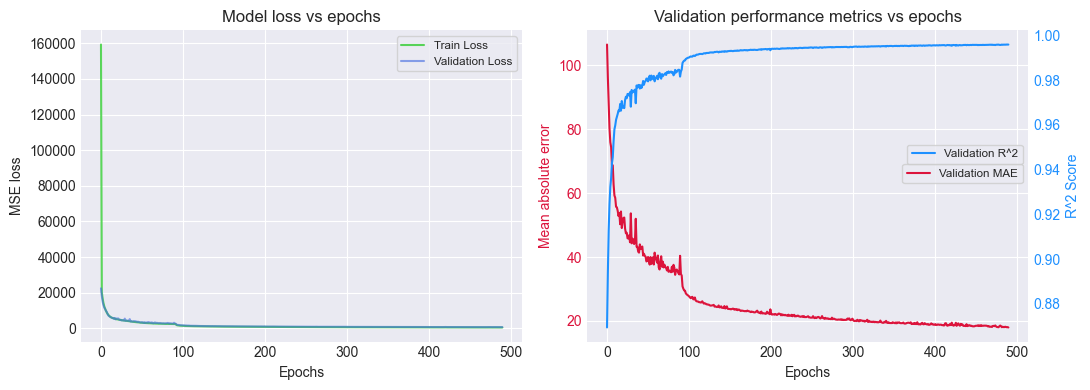

In [111]:
# Combining phase 1 and phase 2 results
# Dropping the last 21 records from phase 1 since it will be repeated again in phase 2
combine_M5trainLoss = history_ph1M5['Model_history train loss'][:-21] + history_ph2M5['Model_history train loss']
combine_M5valLoss = history_ph1M5['Model_history val loss'][:-21] + history_ph2M5['Model_history val loss']
combine_M5valMAE = history_ph1M5['Model_history val MAE'][:-21] + history_ph2M5['Model_history val MAE']
combine_M5valR2S = history_ph1M5['Model_history val R2S'][:-21] + history_ph2M5['Model_history val R2S']
# Plotting the model losses and metrics vs epochs
ModelLoss_MAE_R2S_epochPlot(combine_M5trainLoss,
                           combine_M5valLoss,
                           combine_M5valMAE,
                           combine_M5valR2S)

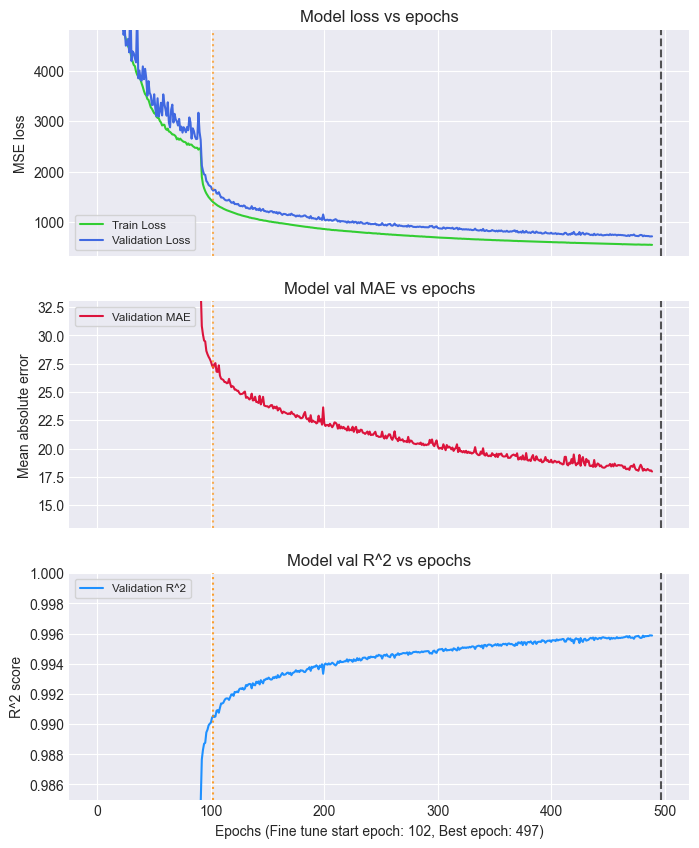

In [112]:
# Combining phase 1 and phase 2 results
zoomModelLoss_MAE_R2S_epochPlot(combine_M5trainLoss,
                                combine_M5valLoss,
                                combine_M5valMAE,
                                combine_M5valR2S, 
                                bestStat_ph2M5['Model_best epoch'], 
                                [320, 4820], 
                                [13, 33], 
                                [0.985, 1],
                                bestStat_ph1M5['Model_best epoch'])

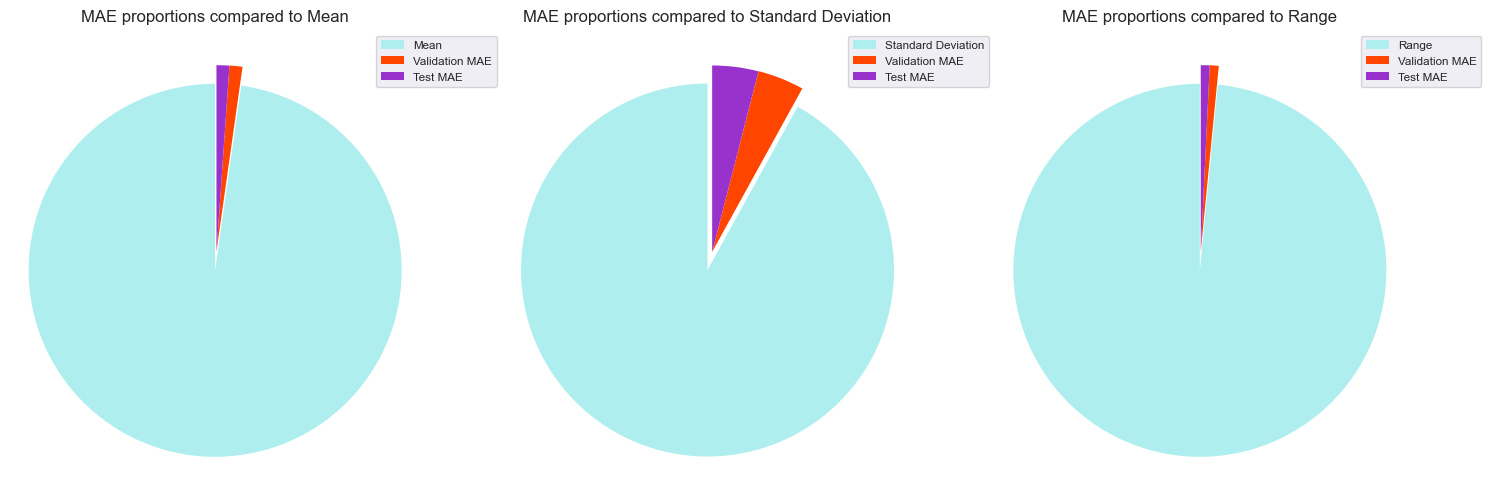

Compared to Mean 				 Compared to Standard Deviation 		 Compared to Range
Validation MAE: 1.15%				 Validation MAE: 4.38%				 Validation MAE: 0.79%
Test MAE: 1.14%					 Test MAE: 4.34%				 Test MAE: 0.78%


In [113]:
propMAE_piePlot(actualData_clean['OutgoingThickness'].to_numpy(), bestStat_ph2M5["Model_best val MAE"], testMAE_M5)

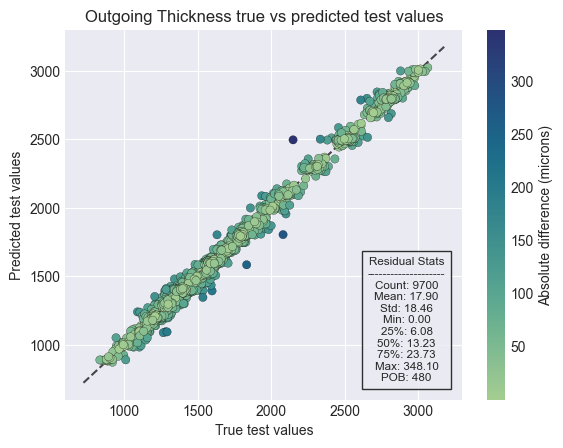

In [114]:
M5Sample_predThreshCount = modelTrue_vsPredvalue(Yact_testTensor.numpy(), testPred_M5)

### Model benchmarking

#### Train losses vs epochs

In [115]:
def benchMK_Metric_Line(M1_perfMetric, M2_perfMetric, M3_perfMetric, M4_perfMetric, M5_perfMetric, Ylimit, metric):
    fig = plt.figure(figsize=(11,4))
    ax1 = fig.add_subplot(121)
    M1_col = '#7D1C08'
    M2_col = '#CC8822'
    M3_col = '#56087D'
    M4_col = '#006400'
    M5_col = '#08697D'

    # Metric vs epochs
    ax1.plot(M1_perfMetric, color=M1_col, label="M1 Control")
    ax1.plot(M2_perfMetric, color=M2_col, label="M2 Frozen")
    ax1.plot(M3_perfMetric, color=M3_col, label="M3 Soft Start")
    ax1.plot(M4_perfMetric, color=M4_col, label="M4 Standard Fine Tune")
    ax1.plot(M5_perfMetric, color=M5_col, label="M5 Frozen Start Fine Tune")
    if metric=="train loss":
        ax1.set_title("Train losses vs epochs")
        ax1.set_ylabel("MSE train loss")
    elif metric=="val loss":
        ax1.set_title("Validation losses vs epochs")
        ax1.set_ylabel("MSE val loss")
    elif metric=="val MAE":
        ax1.set_title("Validation MAE vs epochs")
        ax1.set_ylabel("Mean absolute error")
    elif metric=="val R2S":
        ax1.set_title("Validation R2S vs epochs")
        ax1.set_ylabel("R^2 Score")
    ax1.set_xlabel("Epochs")
    ax1.legend(frameon=True, fontsize='small')
    
    # Zoomed metric vs epochs
    ax2 = fig.add_subplot(122)
    ax2.plot(M1_perfMetric, color=M1_col, label="M1 Control")
    ax2.plot(M2_perfMetric, color=M2_col, label="M2 Frozen")
    ax2.plot(M3_perfMetric, color=M3_col, label="M3 Soft Start")
    ax2.plot(M4_perfMetric, color=M4_col, label="M4 Standard Fine Tune")
    ax2.plot(M5_perfMetric, color=M5_col, label="M5 Frozen Start Fine Tune")
    if metric=="train loss":
        ax2.set_title("Zoomed train losses vs epochs")
        ax2.set_ylabel("MSE train loss")
    elif metric=="val loss":
        ax2.set_title("Zoomed validation losses vs epochs")
        ax2.set_ylabel("MSE val loss")
    elif metric=="val MAE":
        ax2.set_title("Zoomed validation MAE vs epochs")
        ax2.set_ylabel("Mean absolute error")
    elif metric=="val R2S":
        ax2.set_title("Zoomed validation R2S vs epochs")
        ax2.set_ylabel("R^2 Score ")
    else:
        ax1.set_title("")
        ax1.set_ylabel("")
    ax2.set_ylim(Ylimit[0], Ylimit[1])
    ax2.set_xlabel("Epochs")
    ax2.legend(frameon=True, fontsize='small')
    
    plt.tight_layout()
    plt.show()

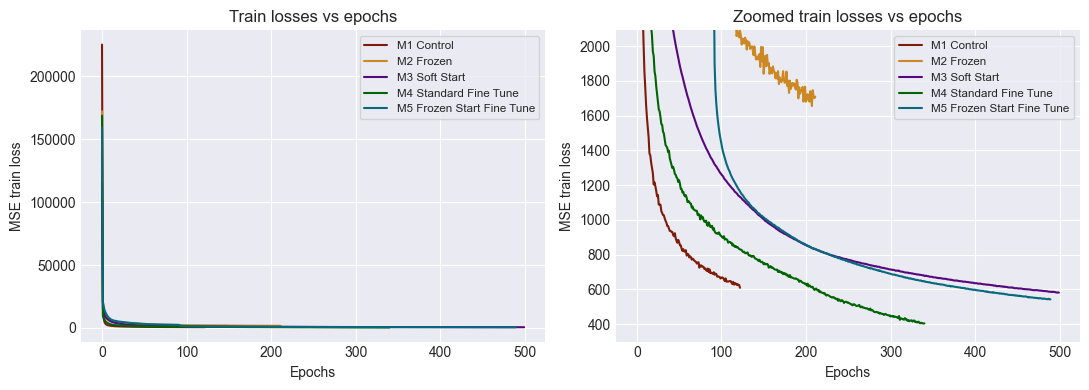

In [116]:
benchMK_Metric_Line(history_M1['Model_history train loss'],
                history_M2['Model_history train loss'],
                history_M3['Model_history train loss'],
                history_M4['Model_history train loss'],
                combine_M5trainLoss,
                [300, 2090],
                metric="train loss")

#### Validation losses vs epochs

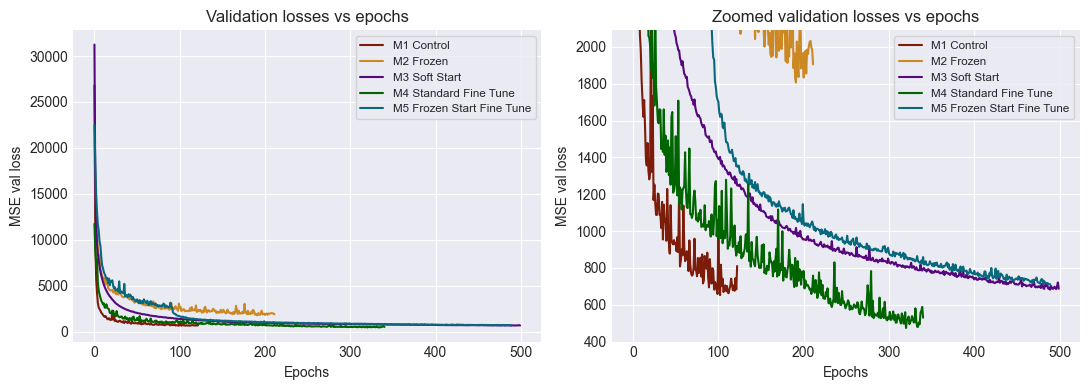

In [117]:
benchMK_Metric_Line(history_M1['Model_history val loss'],
                history_M2['Model_history val loss'],
                history_M3['Model_history val loss'],
                history_M4['Model_history val loss'],
                combine_M5valLoss,
                [400, 2090],
                metric="val loss")

#### Validation MAE vs epochs

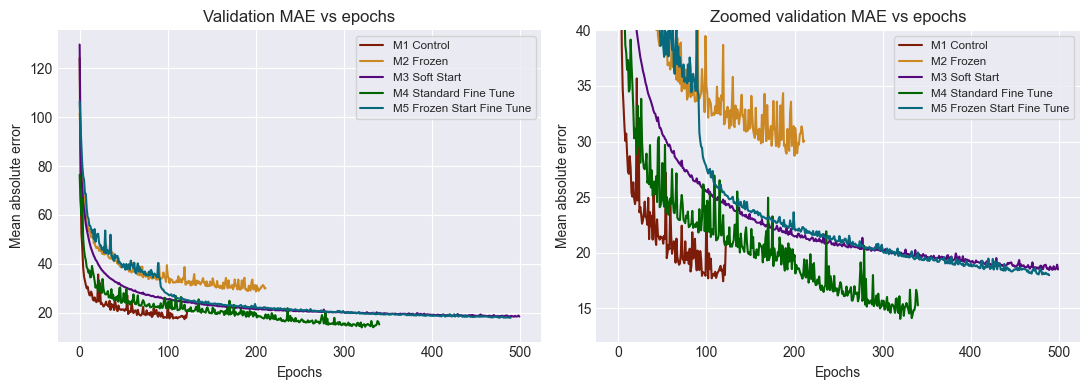

In [118]:
benchMK_Metric_Line(history_M1['Model_history val MAE'],
            history_M2['Model_history val MAE'],
            history_M3['Model_history val MAE'],
            history_M4['Model_history val MAE'],
            combine_M5valMAE,
            [12, 40],
            metric="val MAE")

#### Validation R^2 vs epochs

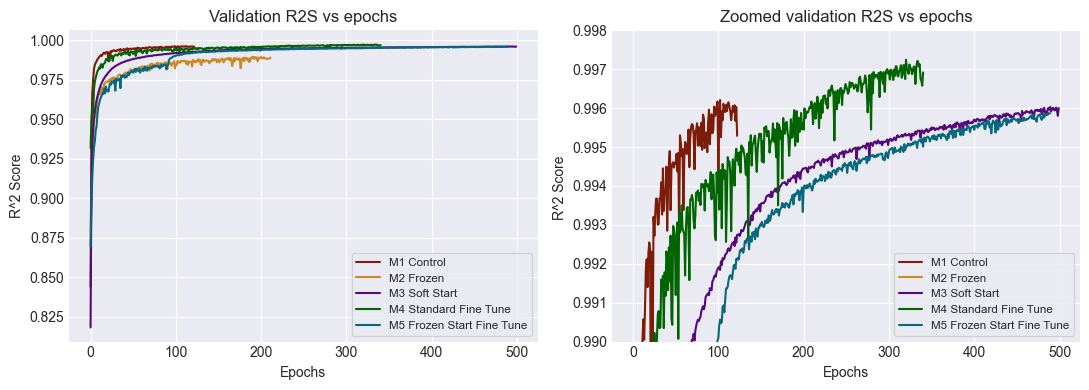

In [119]:
benchMK_Metric_Line(history_M1['Model_history val R2S'],
            history_M2['Model_history val R2S'],
            history_M3['Model_history val R2S'],
            history_M4['Model_history val R2S'],
            combine_M5valR2S,
            [0.990, 0.998],
            metric="val R2S")

#### Test MAE metrics

In [120]:
def benchMK_Metric_Bar(M1_perfMetricL, M2_perfMetricL, M3_perfMetricL, M4_perfMetricL, M5_perfMetricL, metricL, left_txtAdj, 
                       M1_perfMetricR, M2_perfMetricR, M3_perfMetricR, M4_perfMetricR, M5_perfMetricR, metricR, right_txtAdj,
                       M1_trnTime=None, M2_trnTime=None, M3_trnTime=None, M4_trnTime=None, M5_trnTime=None, line_txtAdj=None):
    fig = plt.figure(figsize=(11,4))
    ax1 = fig.add_subplot(121)
    M1_col = '#7D1C08'
    M2_col = '#CC8822'
    M3_col = '#56087D'
    M4_col = '#006400'
    M5_col = '#08697D'
    
    widthBar = 0.6
    posBar = np.arange(1, 6)
    ax1.bar(x=posBar[0], height=M1_perfMetricL, width=widthBar, color=M1_col, label="M1 Control")
    ax1.bar(x=posBar[1], height=M2_perfMetricL, width=widthBar, color=M2_col, label="M2 Frozen")
    ax1.bar(x=posBar[2], height=M3_perfMetricL, width=widthBar, color=M3_col, label="M3 Soft Start")
    ax1.bar(x=posBar[3], height=M4_perfMetricL, width=widthBar, color=M4_col, label="M4 Standard Fine Tune")
    ax1.bar(x=posBar[4], height=M5_perfMetricL, width=widthBar, color=M5_col, label="M5 Frozen Start Fine Tune")
    if metricL=="test MAE":
        ax1.set_ylabel("Mean absolute error (microns)")
        ax1.set_title("Model test MAE scores")
#         ax1.set_ylim(0.0, 25.5)
        roundFactor = 2
    elif metricL=="test R2S":
        ax1.set_ylabel("R^2 score")
        ax1.set_title("Model test R^2 scores")
        ax1.set_ylim(0.987, 1)
        roundFactor = 4
    for i, (value, edgeCol) in enumerate(zip([M1_perfMetricL, M2_perfMetricL, M3_perfMetricL, M4_perfMetricL, M5_perfMetricL], [M1_col, M2_col, M3_col, M4_col, M5_col])):
        ax1.text(posBar[i]-left_txtAdj[0], value+left_txtAdj[1], str(round(value, roundFactor)), bbox=dict(facecolor='white', alpha=0.7, edgecolor=edgeCol))
    ax1.legend(frameon=True, fontsize='small')
    ax1.set_xticks(posBar, [f'M{i}'for i in posBar])
    
    ax2 = fig.add_subplot(122)
    ax2.bar(x=posBar[0], height=M1_perfMetricR, width=widthBar, color=M1_col, label="M1 Control")
    ax2.bar(x=posBar[1], height=M2_perfMetricR, width=widthBar, color=M2_col, label="M2 Frozen")
    ax2.bar(x=posBar[2], height=M3_perfMetricR, width=widthBar, color=M3_col, label="M3 Soft Start")
    ax2.bar(x=posBar[3], height=M4_perfMetricR, width=widthBar, color=M4_col, label="M4 Standard Fine Tune")
    ax2.bar(x=posBar[4], height=M5_perfMetricR, width=widthBar, color=M5_col, label="M5 Frozen Start Fine Tune")
    if metricR=="Epoch Time":
        ax2.plot(posBar, [M1_trnTime, M2_trnTime, M3_trnTime, M4_trnTime, M5_trnTime], marker='^', linestyle=':', c='#B2BEB5', label='Model train time')
        for i, (EpochValue, TimeValue, edgeCol) in enumerate(zip([M1_perfMetricR, M2_perfMetricR, M3_perfMetricR, M4_perfMetricR, M5_perfMetricR], [M1_trnTime, M2_trnTime, M3_trnTime, M4_trnTime, M5_trnTime], [M1_col, M2_col, M3_col, M4_col, M5_col])):
            ax2.text(posBar[i]-right_txtAdj[0], EpochValue+right_txtAdj[1], str(EpochValue), bbox=dict(facecolor='white', alpha=0.7, edgecolor=edgeCol))
            ax2.text(posBar[i]-line_txtAdj[0], TimeValue-line_txtAdj[1], str(int(round(TimeValue,0))), color='white', fontsize='medium', ha='center', va='center', fontweight='bold')
        ax2.set_ylabel("Epochs and training time (minutes)")
        ax2.set_title("Model best epochs and training time")
    elif metricR=="Threshold":
        roundFactor = 0
        for i, (value, edgeCol) in enumerate(zip([M1_perfMetricR, M2_perfMetricR, M3_perfMetricR, M4_perfMetricR, M5_perfMetricR], [M1_col, M2_col, M3_col, M4_col, M5_col])):
            ax2.text(posBar[i]-right_txtAdj[0], value+right_txtAdj[1], str(round(value, roundFactor)), bbox=dict(facecolor='white', alpha=0.7, edgecolor=edgeCol))
        ax2.set_ylabel("Count")
        ax2.set_title("Model predictions greater than acceptable threshold")
    ax2.legend(frameon=True, fontsize='small')
    ax2.set_xticks(posBar, [f'M{i}'for i in posBar])
    
    plt.tight_layout()
    plt.show()

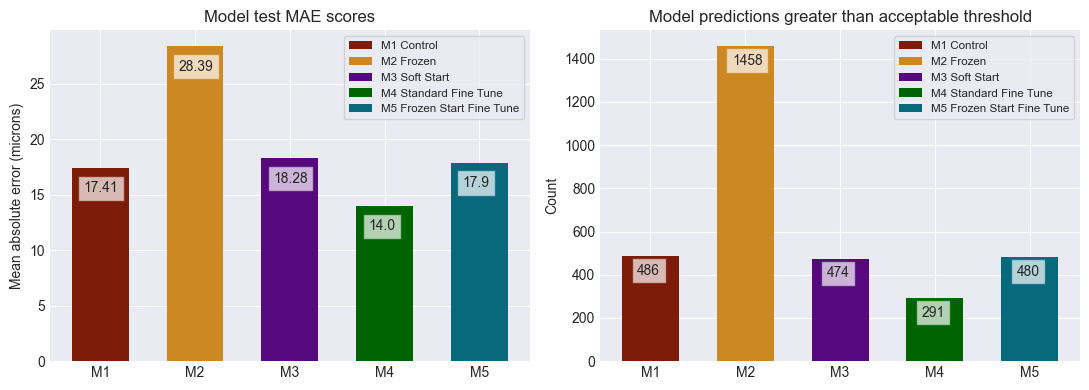

In [121]:
benchMK_Metric_Bar(testMAE_M1, testMAE_M2, testMAE_M3, testMAE_M4, testMAE_M5, "test MAE", [0.175, -2.2],
                   M1Sample_predThreshCount, M2Sample_predThreshCount, M3Sample_predThreshCount,
                   M4Sample_predThreshCount, M5Sample_predThreshCount, "Threshold", [0.14, -85])

#### Test R^2 metrics

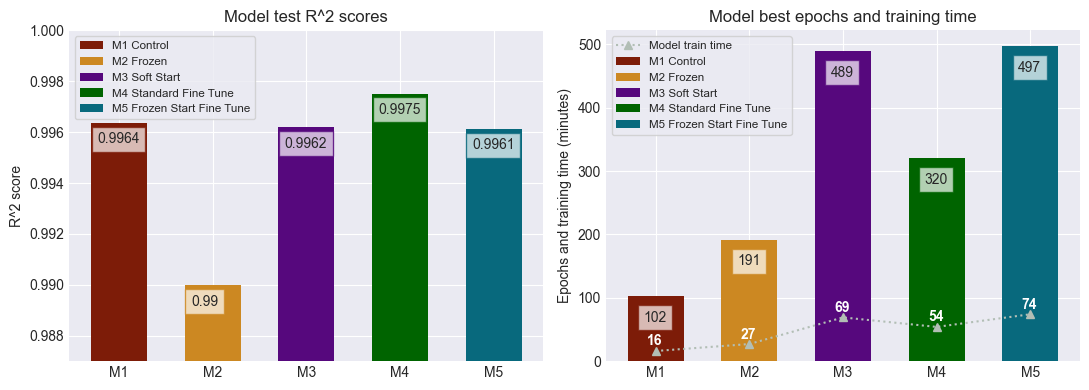

In [122]:
benchMK_Metric_Bar(testR2S_M1, testR2S_M2, testR2S_M3, testR2S_M4, testR2S_M5, "test R2S", [0.231, -0.0008],
                  bestStat_M1['Model_best epoch'], bestStat_M2['Model_best epoch'], bestStat_M3['Model_best epoch'], 
                  bestStat_M4['Model_best epoch'], bestStat_ph2M5['Model_best epoch'], "Epoch Time", [0.13, -40],
                  trainTime_M1//60, trainTime_M2//60, trainTime_M3//60, trainTime_M4//60, 
                  (trainTime_ph1M5+trainTime_ph2M5)//60, [0.01, -15])

In [123]:
# To save actual and predicted results of each model in an excel workbook
Model1_actPred_Dict = {
    "Actual values": Yact_test.to_numpy(),
    "Predicted values": testPred_M1.flatten()
}
Model2_actPred_Dict = {
    "Actual values": Yact_test.to_numpy(),
    "Predicted values": testPred_M2.flatten()
}
Model3_actPred_Dict = {
    "Actual values": Yact_test.to_numpy(),
    "Predicted values": testPred_M3.flatten()
}
Model4_actPred_Dict = {
    "Actual values": Yact_test.to_numpy(),
    "Predicted values": testPred_M4.flatten()
}
Model5_actPred_Dict = {
    "Actual values": Yact_test.to_numpy(),
    "Predicted values": testPred_M5.flatten()
}
ModelbM_actPred_Dict = {
    "Actual values": Yact_test.to_numpy(),
    "Predicted values": testPred_bM.flatten()
}
dfRes_M1 = pd.DataFrame(Model1_actPred_Dict)
dfRes_M2 = pd.DataFrame(Model2_actPred_Dict)
dfRes_M3 = pd.DataFrame(Model3_actPred_Dict)
dfRes_M4 = pd.DataFrame(Model4_actPred_Dict)
dfRes_M5 = pd.DataFrame(Model5_actPred_Dict)
dfRes_MbM = pd.DataFrame(ModelbM_actPred_Dict)

with pd.ExcelWriter('TL_Production_tables/Model prediction.xlsx') as writer:
    dfRes_M1.to_excel(writer, sheet_name='M1 Control', index=False)
    dfRes_M2.to_excel(writer, sheet_name='M2 Frozen', index=False)
    dfRes_M3.to_excel(writer, sheet_name='M3 Soft start', index=False)
    dfRes_M4.to_excel(writer, sheet_name='M4 Standard Fine Tune', index=False)
    dfRes_M5.to_excel(writer, sheet_name='M5 frozen start Fine Tune', index=False)
    dfRes_MbM.to_excel(writer, sheet_name='bM Base Pretrain', index=False)

In [124]:
# To save the training, validation and prediction summary of each model in an excel workbook
Model1_TrainValTest_Summ = copy.deepcopy(bestStat_M1)
Model1_TrainValTest_Summ["Model_test MAE"] = testMAE_M1
Model1_TrainValTest_Summ["Model_test R2S"] = testR2S_M1
Model1_TrainValTest_Summ["Model_train time (sec)"]  = trainTime_M1
Model1_TrainValTest_Summ["Model_pred time (sec)"]  = testTime_M1
Model1_TrainValTest_Summ["Predictions outside bound"]  = M1Sample_predThreshCount

Model2_TrainValTest_Summ = copy.deepcopy(bestStat_M2)
Model2_TrainValTest_Summ["Model_test MAE"] = testMAE_M2
Model2_TrainValTest_Summ["Model_test R2S"] = testR2S_M2
Model2_TrainValTest_Summ["Model_train time (sec)"]  = trainTime_M2
Model2_TrainValTest_Summ["Model_pred time (sec)"]  = testTime_M2
Model2_TrainValTest_Summ["Predictions outside bound"]  = M2Sample_predThreshCount

Model3_TrainValTest_Summ = copy.deepcopy(bestStat_M3)
Model3_TrainValTest_Summ["Model_test MAE"] = testMAE_M3
Model3_TrainValTest_Summ["Model_test R2S"] = testR2S_M3
Model3_TrainValTest_Summ["Model_train time (sec)"]  = trainTime_M3
Model3_TrainValTest_Summ["Model_pred time (sec)"]  = testTime_M3
Model3_TrainValTest_Summ["Predictions outside bound"]  = M3Sample_predThreshCount

Model4_TrainValTest_Summ = copy.deepcopy(bestStat_M4)
Model4_TrainValTest_Summ["Model_test MAE"] = testMAE_M4
Model4_TrainValTest_Summ["Model_test R2S"] = testR2S_M4
Model4_TrainValTest_Summ["Model_train time (sec)"]  = trainTime_M4
Model4_TrainValTest_Summ["Model_pred time (sec)"]  = testTime_M4
Model4_TrainValTest_Summ["Predictions outside bound"]  = M4Sample_predThreshCount

Model5_TrainValTest_Summ = copy.deepcopy(bestStat_ph2M5)
Model5_TrainValTest_Summ["Model_test MAE"] = testMAE_M5
Model5_TrainValTest_Summ["Model_test R2S"] = testR2S_M5
Model5_TrainValTest_Summ["Model_train time (sec)"]  = trainTime_ph1M5 + trainTime_ph2M5
Model5_TrainValTest_Summ["Model_pred time (sec)"]  = testTime_M5
Model5_TrainValTest_Summ["Predictions outside bound"]  = M5Sample_predThreshCount

ModelbM_TrainValTest_Summ = copy.deepcopy(bestStat_bM)
ModelbM_TrainValTest_Summ["Model_test MAE"] = testMAE_bM
ModelbM_TrainValTest_Summ["Model_test R2S"] = testR2S_bM
ModelbM_TrainValTest_Summ["Model_train time (sec)"]  = trainTime_M1
ModelbM_TrainValTest_Summ["Model_pred time (sec)"] = testTime_bM
ModelbM_TrainValTest_Summ["Predictions outside bound"]  = bMSample_predThreshCount

dfModel1_Summ = pd.DataFrame(Model1_TrainValTest_Summ, index=['Model 1']).T
dfModel2_Summ = pd.DataFrame(Model2_TrainValTest_Summ, index=['Model 2']).T
dfModel3_Summ = pd.DataFrame(Model3_TrainValTest_Summ, index=['Model 3']).T
dfModel4_Summ = pd.DataFrame(Model4_TrainValTest_Summ, index=['Model 4']).T
dfModel5_Summ = pd.DataFrame(Model5_TrainValTest_Summ, index=['Model 5']).T
dfModelbM_Summ = pd.DataFrame(ModelbM_TrainValTest_Summ, index=['Base model']).T

with pd.ExcelWriter('TL_Production_tables/Model train_val_test summary.xlsx') as writer:
    dfModel1_Summ.to_excel(writer, sheet_name='M1 Control')
    dfModel2_Summ.to_excel(writer, sheet_name='M2 Frozen')
    dfModel3_Summ.to_excel(writer, sheet_name='M3 Soft start')
    dfModel4_Summ.to_excel(writer, sheet_name='M4 Standard Fine Tune')
    dfModel5_Summ.to_excel(writer, sheet_name='M5 frozen start Fine Tune')
    dfModelbM_Summ.to_excel(writer, sheet_name='bM Base Pretrain')

## [EXPERIMENT 2]: Comparison of model performances vs actual training data proportions
Note: The same hyper parameters and the same base pre-trained model weights will be used for the models.

### Defining data proportions

In [125]:
dProp_min = 0.1
dProp_max = 1.0
num_prop = 10
# Batch sizes for train, validation and test sets
trainBatchSize = 32
val_testBatchSize = 1024

actProp_sizeList = np.linspace(dProp_min, dProp_max, num_prop)
df_DataProp = pd.DataFrame({"Training data proportions": [perc *100 for perc in actProp_sizeList]})
df_DataProp["Total number of samples"] = [round(Xact_trainTensor.size(0) * propPerc) for propPerc in actProp_sizeList]
df_DataProp["Batch size"] = [int(trainBatchSize * propPerc) for propPerc in actProp_sizeList]
# The last batch can have fewer samples especially if it is not perfectly divisible by the batch size
df_DataProp["Number of samples per batch (approx)"] = [np.ceil(prop_sample / prop_batch) for prop_sample, prop_batch in zip(df_DataProp["Total number of samples"], df_DataProp["Batch size"])]
print(df_DataProp.to_markdown(index=False, tablefmt="mixed_grid"))

┍━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┯━━━━━━━━━━━━━━━━━━━━━━━━━━━┯━━━━━━━━━━━━━━┯━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┑
│   Training data proportions │   Total number of samples │   Batch size │   Number of samples per batch (approx) │
┝━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┿━━━━━━━━━━━━━━━━━━━━━━━━━━━┿━━━━━━━━━━━━━━┿━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┥
│                          10 │                      6789 │            3 │                                   2263 │
├─────────────────────────────┼───────────────────────────┼──────────────┼────────────────────────────────────────┤
│                          20 │                     13579 │            6 │                                   2264 │
├─────────────────────────────┼───────────────────────────┼──────────────┼────────────────────────────────────────┤
│                          30 │                     20368 │            9 │                                   2264 │
├─────────────────────────────┼───────────────────────────┼─────────────

### Defining hyper parameters

In [126]:
# Seeding random number generators for discreteness 
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Defining the model hyperparameters
inputDimension = 21
hiddenDimension = [35, 28, 24, 15]
outputDimension = 1
activationFunction = F.relu
learnRate = 1e-3
# Reduce the learning rate by factor of 10 (common approach, other values can be experimented)
tune_learnRate = learnRate * 1e-1
# L2 regularization strength
weightDecay = 1e-4
# Loss function
criterion = nn.MSELoss()
# Performance metrics: MAE and R^2

### Defining datasets and data loader objects for each data proportion

In [127]:
# Function to create training dataloader objects for each specified proportion from the training data
def dprop_trainLoad(trainDataset, dataProp, propBatchSize):
    # Number of samples in each proportion
    prop_sampleNum = round(len(trainDataset) * dataProp)
    # Indices selected to be included in each sample
    prop_sampleId = np.random.choice(len(trainDataset), prop_sampleNum, replace=False)
    subset_trainDataset = Subset(trainDataset, prop_sampleId)
    # Dataloader object
    loader_trainDataset = DataLoader(subset_trainDataset, batch_size=propBatchSize, shuffle=True) 
    return loader_trainDataset

# Validation and testing dataloader objects
ActVal_dPropLoad = DataLoader(ActVal_torchSet, batch_size=val_testBatchSize, shuffle=False)
ActTest_dPropLoad = DataLoader(ActTest_torchSet, batch_size=val_testBatchSize, shuffle=False)

### Model 1: Control model

#### Creating the model architecture

In [128]:
# Instantiating the untrained model and moving it to GPU
dProp_ctrlModel1_untrain = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)
# Optimizer
optimizer = torch.optim.Adam(dProp_ctrlModel1_untrain.parameters(), lr = learnRate, weight_decay = weightDecay)
# Initialize the model weights
dProp_ctrlModel1_untrain.init_WeightBias()
# Viewing a summary of the model created
print(dProp_ctrlModel1_untrain)
# Note: The actual train batch size is dynamic according to the defined proportions and ranges from [1, 32]
print(summary(dProp_ctrlModel1_untrain, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         True
├─ModuleList: 1-1                        --              --              --                   --         True
│    └─Linear: 2-1                       [32, 21]        [32, 35]        770              26.88%         True
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29%      

#### Training the control model and using it for prediction on each data proportion

In [129]:
# Store results for each data proportion
dProp_M1_trainTime = []
dProp_M1best_epoch = []
dProp_M1best_trainLoss = []
dProp_M1best_valLoss = []
dProp_M1best_valMAE = []
dProp_M1best_valR2S = []
dProp_M1_testMAE = []
dProp_M1_testR2S = []

for propPerc in actProp_sizeList:
    print('='*48, f'[Dataset Proportion: {int(round(propPerc*100,2))}%]', '='*48)
    # Copy the untrained model weights to the model to be trained 
    # By using deepcopy we reset the learned weights and biases of the trained model with the untrained model for every proportion
    dProp_ctrlModel1_train = copy.deepcopy(dProp_ctrlModel1_untrain)
    dProp_ctrlModel1_train = dProp_ctrlModel1_train.to(device)
    # To reset the optimizer
    optimizer = torch.optim.Adam(dProp_ctrlModel1_train.parameters(), lr = learnRate, weight_decay = weightDecay)
    # Adjusted batch size for each proportion
    dProp_trainBatchSize = int(trainBatchSize * propPerc)
    # Train data loader for each proportion
    ActTrain_dPropLoad = dprop_trainLoad(ActTrain_torchSet, propPerc, dProp_trainBatchSize)
    
    # Train the model for each proportion
    propM1_trainTime, dProp_ctrlModel1_train, propM1_bestStat, _ = train_NNRegModel(
         dProp_ctrlModel1_train, 
         ActTrain_dPropLoad, 
         ActVal_dPropLoad, 
         optimizer, 
         criterion, 
         device, 
         epochs=500, 
         patience=20
    )
    # Store the train results for each proportion
    dProp_M1_trainTime.append(propM1_trainTime)
    dProp_M1best_epoch.append(propM1_bestStat["Model_best epoch"])
    dProp_M1best_trainLoss.append(propM1_bestStat["Model_best train loss"])
    dProp_M1best_valLoss.append(propM1_bestStat["Model_best val loss"])
    dProp_M1best_valMAE.append(propM1_bestStat["Model_best val MAE"])
    dProp_M1best_valR2S.append(propM1_bestStat["Model_best val R2S"])  
    # Run predictions on model for each proportion
    dProp_ctrlModel1_train = dProp_ctrlModel1_train.to(device)
    _, _, propM1_testMAE, propM1_testR2S = predict_NNRegModel(dProp_ctrlModel1_train, ActTest_dPropLoad, device)
    # Store the prediction results for each proportion
    dProp_M1_testMAE.append(propM1_testMAE)
    dProp_M1_testR2S.append(propM1_testR2S)
    print()

================================================ [Dataset Proportion: 10%] ================================================
Epoch [1/500] ==> Train Loss: 289997.7313, Validation Loss: 49672.3056, Validation MAE: 169.9355, Validation R^2: 0.7112

Epoch [20/500] ==> Train Loss: 3058.7744, Validation Loss: 4061.2555, Validation MAE: 43.6157, Validation R^2: 0.9764
Epoch [40/500] ==> Train Loss: 2038.6323, Validation Loss: 2504.8655, Validation MAE: 31.8596, Validation R^2: 0.9854
Epoch [60/500] ==> Train Loss: 1508.0441, Validation Loss: 2294.3170, Validation MAE: 31.3200, Validation R^2: 0.9867
Epoch [80/500] ==> Train Loss: 1475.4661, Validation Loss: 2274.9415, Validation MAE: 31.8887, Validation R^2: 0.9868
Epoch [100/500] ==> Train Loss: 1155.2222, Validation Loss: 1677.4108, Validation MAE: 25.4596, Validation R^2: 0.9902


Early stopping triggered. Training halted.

Training completed in 17 minutes and 21 seconds.
--------------------------------------------------------------------

Epoch [1/500] ==> Train Loss: 239283.6585, Validation Loss: 31194.0866, Validation MAE: 133.5771, Validation R^2: 0.8186

Epoch [20/500] ==> Train Loss: 1590.4895, Validation Loss: 1586.5976, Validation MAE: 27.1110, Validation R^2: 0.9908
Epoch [40/500] ==> Train Loss: 1216.0143, Validation Loss: 1374.3436, Validation MAE: 25.7388, Validation R^2: 0.9920
Epoch [60/500] ==> Train Loss: 1043.9194, Validation Loss: 1044.5195, Validation MAE: 21.7648, Validation R^2: 0.9939
Epoch [80/500] ==> Train Loss: 907.0554, Validation Loss: 995.2244, Validation MAE: 21.6154, Validation R^2: 0.9942
Epoch [100/500] ==> Train Loss: 821.3136, Validation Loss: 866.9250, Validation MAE: 20.0604, Validation R^2: 0.9950

Epoch [120/500] ==> Train Loss: 756.6746, Validation Loss: 783.5948, Validation MAE: 18.4036, Validation R^2: 0.9954
Epoch [140/500] ==> Train Loss: 691.9900, Validation Loss: 829.8872, Validation MAE: 18.5875, Validation R^2: 0.9952
Epoch [160/500] ==> Train Loss: 676.2940, Validation Los

Epoch [80/500] ==> Train Loss: 733.8788, Validation Loss: 764.7050, Validation MAE: 19.2067, Validation R^2: 0.9956
Epoch [100/500] ==> Train Loss: 674.6890, Validation Loss: 740.8376, Validation MAE: 18.8681, Validation R^2: 0.9957

Epoch [120/500] ==> Train Loss: 636.0433, Validation Loss: 668.9334, Validation MAE: 17.8917, Validation R^2: 0.9961
Epoch [140/500] ==> Train Loss: 609.9714, Validation Loss: 655.6282, Validation MAE: 17.4283, Validation R^2: 0.9962
Epoch [160/500] ==> Train Loss: 577.5752, Validation Loss: 662.6827, Validation MAE: 17.6399, Validation R^2: 0.9961
Epoch [180/500] ==> Train Loss: 549.8408, Validation Loss: 577.3202, Validation MAE: 16.6855, Validation R^2: 0.9966
Epoch [200/500] ==> Train Loss: 500.9554, Validation Loss: 543.4539, Validation MAE: 15.9320, Validation R^2: 0.9968

Epoch [220/500] ==> Train Loss: 481.1710, Validation Loss: 600.0409, Validation MAE: 16.6465, Validation R^2: 0.9965
Epoch [240/500] ==> Train Loss: 469.7755, Validation Loss: 643.

#### Visualizing the control model performances for the data proportions

In [130]:
def dProp_ModelLoss_MAE_R2S_epoch_timePlot(mProp_trainLoss, mProp_valLoss, mProp_valMAE, mProp_valR2S,
                                          mProp_testMAE, mProp_testR2S, mProp_bestEpoch, mProp_trainTime):
    fig, ((ax1, ax2), (ax4, ax5)) = plt.subplots(2, 2, figsize=(11, 8))
    actProp_sizeList_perc = [prop * 100 for prop in actProp_sizeList]
    mProp_trainTime_minute = [int(minute//60) for minute in mProp_trainTime]
    # Best training and validation loss vs data proportions
    ax1.plot(actProp_sizeList_perc, mProp_trainLoss, color='#32CD32', label="Best train loss", marker='X')
    ax1.plot(actProp_sizeList_perc, mProp_valLoss, color='#4169E1', label="Best validation Loss", marker='o')
    ax1.set_title("Model best loss vs data proportions")
    ax1.set_xlabel("Data proportions (%)")
    ax1.set_ylabel("MSE loss")
    ax1.set_xlim(0, 110)
    ax1.set_xticks(range(0, 110, 10))
    ax1.legend(frameon=True, fontsize='small')
    # Validation MAE and R2S score vs data proportions
    ax2.plot(actProp_sizeList_perc, mProp_valMAE, color='#DC143C', label="Best validation MAE", marker='^')
    ax2.set_xlabel("Data proportions (%)")
    ax2.set_ylabel("Mean absolute error", color='#DC143C')
    ax2.tick_params(axis='y', labelcolor='#DC143C')
    ax3 = ax2.twinx()
    ax3.plot(actProp_sizeList_perc, mProp_valR2S, color='#1E90FF', label="Best validation R^2", marker='s')
    ax3.set_ylabel("R^2 Score", color='#1E90FF')
    ax3.tick_params(axis='y', labelcolor='#1E90FF')
    ax2.set_xlim(0, 110)
    ax2.set_xticks(range(0, 110, 10))
    ax2.legend(frameon=True, fontsize='small', loc='center right', bbox_to_anchor=(0.5, 0.29, 0.5, 0.5))
    ax3.legend(frameon=True, fontsize='small', loc='center right', bbox_to_anchor=(0.5, 0.352, 0.5, 0.5))
    ax3.grid(False)
    ax2.set_title("Model best validation metrics vs data proportions")
    # Best epochs and training time vs data proportions
    ax4.plot(actProp_sizeList_perc, mProp_bestEpoch, color='#B1624EFF', label="Best epoch", marker='P')
    ax4.plot(actProp_sizeList_perc, mProp_trainTime_minute, color='#08777D', label="Train time", marker='*')
    ax4.set_title("Model best epochs and training time vs data proportions")
    ax4.set_xlabel("Data proportions (%)")
    ax4.set_ylabel("Epochs and training time (minutes)")
    ax4.set_xlim(0, 110)
    ax4.set_xticks(range(0, 110, 10))
    ax4.legend(frameon=True, fontsize='small')
    # Test MAE and R2S score vs data proportions
    ax5.plot(actProp_sizeList_perc, mProp_testMAE, color='#2E7D08', label="Test MAE", marker='H')
    ax5.set_xlabel("Data proportions (%)")
    ax5.set_ylabel("Mean absolute error", color='#2E7D08')
    ax5.tick_params(axis='y', labelcolor='#2E7D08')
    ax6 = ax5.twinx()
    ax6.plot(actProp_sizeList_perc, mProp_testR2S, color='#57087D', label="Test R^2", marker='D')
    ax6.set_ylabel("R^2 Score", color='#57087D')
    ax6.tick_params(axis='y', labelcolor='#57087D')
    ax5.set_xlim(0, 110)
    ax5.set_xticks(range(0, 110, 10))
    ax5.legend(frameon=True, fontsize='small', loc='center right', bbox_to_anchor=(0.5, 0.29, 0.5, 0.5))
    ax6.legend(frameon=True, fontsize='small', loc='center right', bbox_to_anchor=(0.5, 0.352, 0.5, 0.5))
    ax6.grid(False)
    ax5.set_title("Model best validation metrics vs data proportions")
    fig.tight_layout()
    plt.show()
    
    propModel_InfoDict = {
        "Propotion": actProp_sizeList_perc,
        "Train loss": mProp_trainLoss,
        "Val loss": mProp_valLoss,
        "Best epoch": mProp_bestEpoch,
        "Train time": mProp_trainTime_minute,
        "Val MAE": mProp_valMAE,
        "Test MAE": mProp_testMAE,
        "Val R2S": mProp_valR2S,
        "Test R2S": mProp_testR2S
    }
    print(tabulate(propModel_InfoDict, headers='keys', tablefmt="rounded_grid", floatfmt=('.0f', '.4f', '.4f', '.0f',
                                                                                           '.0f', '.4f', '.4f', '.4f',
                                                                                           '.4f')))

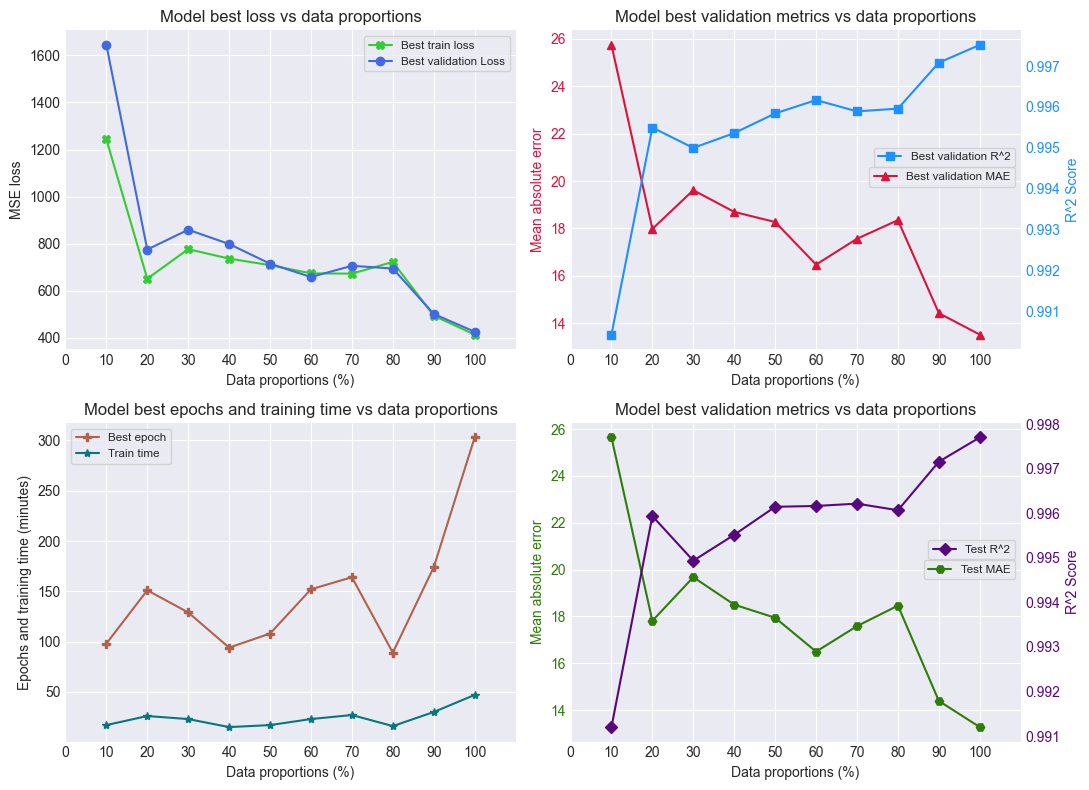

╭─────────────┬──────────────┬────────────┬──────────────┬──────────────┬───────────┬────────────┬───────────┬────────────╮
│   Propotion │   Train loss │   Val loss │   Best epoch │   Train time │   Val MAE │   Test MAE │   Val R2S │   Test R2S │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          10 │    1243.6973 │  1644.3351 │           98 │           17 │   25.7467 │    25.6434 │    0.9904 │     0.9912 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          20 │     651.6573 │   775.5090 │          151 │           26 │   17.9788 │    17.8136 │    0.9955 │     0.9959 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          30 │     777.1215 │   859.5807 │          129 │           23 │   19.6141 │    19.6761 │    0.9950 │     0.9949 │
├───────

In [131]:
dProp_ModelLoss_MAE_R2S_epoch_timePlot(dProp_M1best_trainLoss, dProp_M1best_valLoss, dProp_M1best_valMAE, 
                                       dProp_M1best_valR2S, dProp_M1_testMAE, dProp_M1_testR2S, dProp_M1best_epoch,
                                       dProp_M1_trainTime)

### Model 2: TL Frozen model

#### Creating the model architecture

In [132]:
# Loading the base model architecture and hyperparameters
with open("SimPTrain_bModel_arch.json", 'r') as infile:
    preTrainLoad_modelInfo = json.load(infile)

# Defining the base model hyperparameters for the model
inputDimension = preTrainLoad_modelInfo["inputDimension"]
hiddenDimension = preTrainLoad_modelInfo["hiddenDimension"]
outputDimension = preTrainLoad_modelInfo["outputDimension"]
activationFunction = F.relu if preTrainLoad_modelInfo["activationFunction"]=="relu" else None
learnRate = preTrainLoad_modelInfo["learnRate"]
weightDecay = preTrainLoad_modelInfo["weightDecay"]
# Defining the layers to be frozen
id_layersFreeze = [0]
# Defining the new layer indices to be created
id_newLayers = [1, 2, 3, 4]

# Creating the model
dProp_TL_frzModel2_untrain = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)

# Loading the base model weights into the model
dProp_TL_frzModel2_untrain.load_state_dict(torch.load("SimPTrain_bModel_weight_bias.pth"))

<All keys matched successfully>

In [133]:
# Freezing the base layers of the frozen model (since the frozen model has been initialized with the base model's weights and biases)
for i, layer in enumerate(dProp_TL_frzModel2_untrain.layers):
    if i in id_layersFreeze:
        for param_WB in layer.parameters():
            param_WB.requires_grad = False
            
# Replacing the frozen model's upper layers with new layers
for i in range(len(id_newLayers)):
    if id_newLayers[i] == id_newLayers[-1]:
        Act_TL_frzModel2.layers[id_newLayers[i]] = nn.Linear(hiddenDimension[id_newLayers[i]-1], outputDimension).to(device)
    else:
        Act_TL_frzModel2.layers[id_newLayers[i]] = nn.Linear(hiddenDimension[id_newLayers[i]-1], hiddenDimension[id_newLayers[i]]).to(device)

# Initializing the new layers weights with He initializer and bias with zero
for i in range(len(id_newLayers)):
    nn.init.kaiming_uniform_(Act_TL_frzModel2.layers[id_newLayers[i]].weight, nonlinearity='relu')
    nn.init.zeros_(Act_TL_frzModel2.layers[id_newLayers[i]].bias)
    
# Loss function
criterion = nn.MSELoss()
# Optimizer (keeping the same control model learning rate of 1e-2)
optimizer = torch.optim.Adam(dProp_TL_frzModel2_untrain.parameters(), lr = learnRate, weight_decay = weightDecay)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(dProp_TL_frzModel2_untrain)
print(summary(dProp_TL_frzModel2_untrain, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         Partial
├─ModuleList: 1-1                        --              --              --                   --         Partial
│    └─Linear: 2-1                       [32, 21]        [32, 35]        (770)            26.88%         False
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29

#### Training the frozen model and using it for prediction on each data proportion

In [134]:
# Store results for each data proportion
dProp_M2_trainTime = []
dProp_M2best_epoch = []
dProp_M2best_trainLoss = []
dProp_M2best_valLoss = []
dProp_M2best_valMAE = []
dProp_M2best_valR2S = []
dProp_M2_testMAE = []
dProp_M2_testR2S = []

for propPerc in actProp_sizeList:
    print('='*48, f'[Dataset Proportion: {int(round(propPerc*100,2))}%]', '='*48)
    # Copy the untrained model weights to the model to be trained 
    # By using deepcopy we reset the learned weights and biases of the trained model with the untrained model for every proportion
    dProp_TL_frzModel2_train = copy.deepcopy(dProp_TL_frzModel2_untrain)
    dProp_TL_frzModel2_train = dProp_TL_frzModel2_train.to(device)
    # To reset the optimizer
    optimizer = torch.optim.Adam(dProp_TL_frzModel2_train.parameters(), lr = learnRate, weight_decay = weightDecay)
    # Adjusted batch size for each proportion
    dProp_trainBatchSize = int(trainBatchSize * propPerc)
    # Train data loader for each proportion
    ActTrain_dPropLoad = dprop_trainLoad(ActTrain_torchSet, propPerc, dProp_trainBatchSize)
    
    # Train the model for each proportion
    propM2_trainTime, dProp_TL_frzModel2_train, propM2_bestStat, _ = train_NNRegModel(
         dProp_TL_frzModel2_train, 
         ActTrain_dPropLoad, 
         ActVal_dPropLoad, 
         optimizer, 
         criterion, 
         device, 
         epochs=500, 
         patience=20
    )
    # Store the train results for each proportion
    dProp_M2_trainTime.append(propM2_trainTime)
    dProp_M2best_epoch.append(propM2_bestStat["Model_best epoch"])
    dProp_M2best_trainLoss.append(propM2_bestStat["Model_best train loss"])
    dProp_M2best_valLoss.append(propM2_bestStat["Model_best val loss"])
    dProp_M2best_valMAE.append(propM2_bestStat["Model_best val MAE"])
    dProp_M2best_valR2S.append(propM2_bestStat["Model_best val R2S"])  
    # Run predictions on model for each proportion
    dProp_TL_frzModel2_train = dProp_TL_frzModel2_train.to(device)
    _, _, propM2_testMAE, propM2_testR2S = predict_NNRegModel(dProp_TL_frzModel2_train, ActTest_dPropLoad, device)
    # Store the prediction results for each proportion
    dProp_M2_testMAE.append(propM2_testMAE)
    dProp_M2_testR2S.append(propM2_testR2S)
    print()

================================================ [Dataset Proportion: 10%] ================================================
Epoch [1/500] ==> Train Loss: 79816.4423, Validation Loss: 36468.7600, Validation MAE: 136.8515, Validation R^2: 0.7881

Epoch [20/500] ==> Train Loss: 11123.0063, Validation Loss: 12078.6516, Validation MAE: 75.5136, Validation R^2: 0.9298
Epoch [40/500] ==> Train Loss: 7745.3721, Validation Loss: 9481.8182, Validation MAE: 66.0155, Validation R^2: 0.9449
Epoch [60/500] ==> Train Loss: 6413.0923, Validation Loss: 7916.2677, Validation MAE: 60.0444, Validation R^2: 0.9540
Epoch [80/500] ==> Train Loss: 5478.7948, Validation Loss: 7411.0364, Validation MAE: 58.4148, Validation R^2: 0.9569
Epoch [100/500] ==> Train Loss: 4705.5097, Validation Loss: 6980.3269, Validation MAE: 54.8966, Validation R^2: 0.9594

Epoch [120/500] ==> Train Loss: 4324.7503, Validation Loss: 7197.8688, Validation MAE: 56.6308, Validation R^2: 0.9582
Epoch [140/500] ==> Train Loss: 4062.0290,

Epoch [1/500] ==> Train Loss: 57564.8737, Validation Loss: 25953.3321, Validation MAE: 114.9430, Validation R^2: 0.8493

Epoch [20/500] ==> Train Loss: 6401.7906, Validation Loss: 6807.3382, Validation MAE: 57.3090, Validation R^2: 0.9604
Epoch [40/500] ==> Train Loss: 4451.5800, Validation Loss: 5148.8396, Validation MAE: 50.0004, Validation R^2: 0.9701
Epoch [60/500] ==> Train Loss: 3589.9496, Validation Loss: 4143.3195, Validation MAE: 42.8129, Validation R^2: 0.9759
Epoch [80/500] ==> Train Loss: 3100.5446, Validation Loss: 3808.5520, Validation MAE: 41.9675, Validation R^2: 0.9778
Epoch [100/500] ==> Train Loss: 2796.2620, Validation Loss: 3333.6458, Validation MAE: 37.3176, Validation R^2: 0.9806

Epoch [120/500] ==> Train Loss: 2568.9915, Validation Loss: 3334.6603, Validation MAE: 37.9678, Validation R^2: 0.9806
Epoch [140/500] ==> Train Loss: 2462.8675, Validation Loss: 2977.5249, Validation MAE: 35.3587, Validation R^2: 0.9826
Epoch [160/500] ==> Train Loss: 2356.1974, Valida

Epoch [1/500] ==> Train Loss: 49944.5675, Validation Loss: 22791.7345, Validation MAE: 107.5926, Validation R^2: 0.8677

Epoch [20/500] ==> Train Loss: 5544.6849, Validation Loss: 5563.2691, Validation MAE: 50.8852, Validation R^2: 0.9677
Epoch [40/500] ==> Train Loss: 4131.9989, Validation Loss: 4328.3052, Validation MAE: 45.0210, Validation R^2: 0.9748
Epoch [60/500] ==> Train Loss: 3378.3842, Validation Loss: 3805.4006, Validation MAE: 42.6624, Validation R^2: 0.9779
Epoch [80/500] ==> Train Loss: 2949.0788, Validation Loss: 3227.2644, Validation MAE: 38.2704, Validation R^2: 0.9812
Epoch [100/500] ==> Train Loss: 2611.0040, Validation Loss: 2942.5614, Validation MAE: 35.8067, Validation R^2: 0.9829

Epoch [120/500] ==> Train Loss: 2438.1635, Validation Loss: 3044.6199, Validation MAE: 37.8679, Validation R^2: 0.9823
Epoch [140/500] ==> Train Loss: 2286.5504, Validation Loss: 2833.2866, Validation MAE: 37.0874, Validation R^2: 0.9835
Epoch [160/500] ==> Train Loss: 2166.2320, Valida

#### Visualizing the frozen model performances for the data proportions

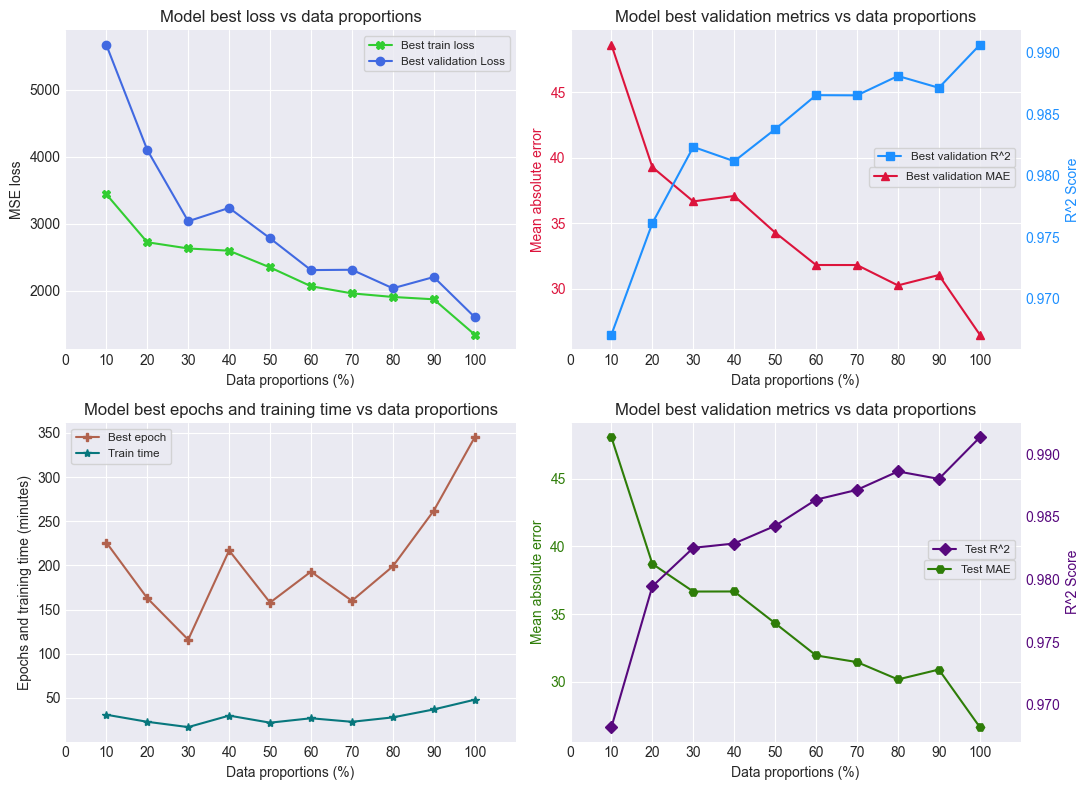

╭─────────────┬──────────────┬────────────┬──────────────┬──────────────┬───────────┬────────────┬───────────┬────────────╮
│   Propotion │   Train loss │   Val loss │   Best epoch │   Train time │   Val MAE │   Test MAE │   Val R2S │   Test R2S │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          10 │    3440.1458 │  5669.4370 │          226 │           31 │   48.6223 │    48.0412 │    0.9671 │     0.9682 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          20 │    2724.0922 │  4101.8109 │          163 │           23 │   39.2754 │    38.7039 │    0.9761 │     0.9794 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          30 │    2631.3685 │  3037.4068 │          116 │           17 │   36.6583 │    36.6625 │    0.9823 │     0.9825 │
├───────

In [135]:
dProp_ModelLoss_MAE_R2S_epoch_timePlot(dProp_M2best_trainLoss, dProp_M2best_valLoss, dProp_M2best_valMAE, 
                                       dProp_M2best_valR2S, dProp_M2_testMAE, dProp_M2_testR2S, dProp_M2best_epoch,
                                       dProp_M2_trainTime)

### Model 3: TL Soft Start model

#### Creating the model architecture

In [136]:
# Loading the base model architecture and hyperparameters
with open("SimPTrain_bModel_arch.json", 'r') as infile:
    preTrainLoad_modelInfo = json.load(infile)

# Defining the base model hyperparameters for the model
inputDimension = preTrainLoad_modelInfo["inputDimension"]
hiddenDimension = preTrainLoad_modelInfo["hiddenDimension"]
outputDimension = preTrainLoad_modelInfo["outputDimension"]
activationFunction = F.relu if preTrainLoad_modelInfo["activationFunction"]=="relu" else None
learnRate = preTrainLoad_modelInfo["learnRate"]
weightDecay = preTrainLoad_modelInfo["weightDecay"]
# Reduce the learning rate by factor of 10 (common approach, other values can be experimented)
tune_learnRate = learnRate * 1e-1

In [137]:
# Creating the soft start model
dProp_TL_sftModel3_untrain = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)

# Loading the base model weights into the model
dProp_TL_sftModel3_untrain.load_state_dict(torch.load("SimPTrain_bModel_weight_bias.pth"))

# Loss function
criterion = nn.MSELoss()
# Optimizer (keeping the same base model learning rate of 1e-2)
optimizer = torch.optim.Adam(dProp_TL_sftModel3_untrain.parameters(), lr = tune_learnRate, weight_decay = weightDecay)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(dProp_TL_sftModel3_untrain)
print(summary(dProp_TL_sftModel3_untrain, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         True
├─ModuleList: 1-1                        --              --              --                   --         True
│    └─Linear: 2-1                       [32, 21]        [32, 35]        770              26.88%         True
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29%      

#### Training the soft start model and using it for prediction on each data proportion

In [138]:
# Store results for each data proportion
dProp_M3_trainTime = []
dProp_M3best_epoch = []
dProp_M3best_trainLoss = []
dProp_M3best_valLoss = []
dProp_M3best_valMAE = []
dProp_M3best_valR2S = []
dProp_M3_testMAE = []
dProp_M3_testR2S = []

for propPerc in actProp_sizeList:
    print('='*48, f'[Dataset Proportion: {int(round(propPerc*100,2))}%]', '='*48)
    # Copy the untrained model weights to the model to be trained 
    # By using deepcopy we reset the learned weights and biases of the trained model with the untrained model for every proportion
    dProp_TL_sftModel3_train = copy.deepcopy(dProp_TL_sftModel3_untrain)
    dProp_TL_sftModel3_train = dProp_TL_sftModel3_train.to(device)
    # To reset the optimizer
    optimizer = torch.optim.Adam(dProp_TL_sftModel3_train.parameters(), lr = tune_learnRate, weight_decay = weightDecay)
    # Adjusted batch size for each proportion
    dProp_trainBatchSize = int(trainBatchSize * propPerc)
    # Train data loader for each proportion
    ActTrain_dPropLoad = dprop_trainLoad(ActTrain_torchSet, propPerc, dProp_trainBatchSize)
    
    # Train the model for each proportion
    propM3_trainTime, dProp_TL_sftModel3_train, propM3_bestStat, _ = train_NNRegModel(
         dProp_TL_sftModel3_train, 
         ActTrain_dPropLoad, 
         ActVal_dPropLoad, 
         optimizer, 
         criterion, 
         device, 
         epochs=500, 
         patience=20
    )
    # Store the train results for each proportion
    dProp_M3_trainTime.append(propM3_trainTime)
    dProp_M3best_epoch.append(propM3_bestStat["Model_best epoch"])
    dProp_M3best_trainLoss.append(propM3_bestStat["Model_best train loss"])
    dProp_M3best_valLoss.append(propM3_bestStat["Model_best val loss"])
    dProp_M3best_valMAE.append(propM3_bestStat["Model_best val MAE"])
    dProp_M3best_valR2S.append(propM3_bestStat["Model_best val R2S"])  
    # Run predictions on model for each proportion
    dProp_TL_sftModel3_train = dProp_TL_sftModel3_train.to(device)
    _, _, propM3_testMAE, propM3_testR2S = predict_NNRegModel(dProp_TL_sftModel3_train, ActTest_dPropLoad, device)
    # Store the prediction results for each proportion
    dProp_M3_testMAE.append(propM3_testMAE)
    dProp_M3_testR2S.append(propM3_testR2S)
    print()

================================================ [Dataset Proportion: 10%] ================================================
Epoch [1/500] ==> Train Loss: 184254.0778, Validation Loss: 70373.5794, Validation MAE: 200.4496, Validation R^2: 0.5911

Epoch [20/500] ==> Train Loss: 6446.4612, Validation Loss: 7040.4132, Validation MAE: 57.9417, Validation R^2: 0.9591
Epoch [40/500] ==> Train Loss: 4000.1435, Validation Loss: 4895.8819, Validation MAE: 46.3877, Validation R^2: 0.9716
Epoch [60/500] ==> Train Loss: 2952.7526, Validation Loss: 4178.2766, Validation MAE: 42.4168, Validation R^2: 0.9757
Epoch [80/500] ==> Train Loss: 2387.7384, Validation Loss: 3532.9831, Validation MAE: 39.1060, Validation R^2: 0.9795
Epoch [100/500] ==> Train Loss: 2038.9246, Validation Loss: 3211.7303, Validation MAE: 36.8439, Validation R^2: 0.9813

Epoch [120/500] ==> Train Loss: 1778.2590, Validation Loss: 2995.1008, Validation MAE: 35.5568, Validation R^2: 0.9826
Epoch [140/500] ==> Train Loss: 1581.9882, 

Epoch [80/500] ==> Train Loss: 1967.0626, Validation Loss: 2321.3945, Validation MAE: 32.1538, Validation R^2: 0.9865
Epoch [100/500] ==> Train Loss: 1708.0383, Validation Loss: 2126.1930, Validation MAE: 31.3840, Validation R^2: 0.9876

Epoch [120/500] ==> Train Loss: 1519.0700, Validation Loss: 1872.8939, Validation MAE: 29.0835, Validation R^2: 0.9891
Epoch [140/500] ==> Train Loss: 1383.5258, Validation Loss: 1734.6889, Validation MAE: 28.0616, Validation R^2: 0.9899
Epoch [160/500] ==> Train Loss: 1290.6700, Validation Loss: 1663.8975, Validation MAE: 27.3872, Validation R^2: 0.9903
Epoch [180/500] ==> Train Loss: 1215.4633, Validation Loss: 1575.6598, Validation MAE: 26.5929, Validation R^2: 0.9908
Epoch [200/500] ==> Train Loss: 1152.0035, Validation Loss: 1525.9622, Validation MAE: 26.2018, Validation R^2: 0.9911

Epoch [220/500] ==> Train Loss: 1092.2326, Validation Loss: 1467.2342, Validation MAE: 25.7470, Validation R^2: 0.9915
Epoch [240/500] ==> Train Loss: 1044.2218, Vali

Epoch [140/500] ==> Train Loss: 1246.7724, Validation Loss: 1471.4699, Validation MAE: 25.9137, Validation R^2: 0.9914
Epoch [160/500] ==> Train Loss: 1149.5362, Validation Loss: 1358.6892, Validation MAE: 25.0064, Validation R^2: 0.9921
Epoch [180/500] ==> Train Loss: 1067.6034, Validation Loss: 1294.2093, Validation MAE: 24.4564, Validation R^2: 0.9925
Epoch [200/500] ==> Train Loss: 1003.2482, Validation Loss: 1227.2606, Validation MAE: 23.7258, Validation R^2: 0.9929

Epoch [220/500] ==> Train Loss: 948.7617, Validation Loss: 1184.9865, Validation MAE: 23.6728, Validation R^2: 0.9931
Epoch [240/500] ==> Train Loss: 906.7843, Validation Loss: 1126.2760, Validation MAE: 22.9108, Validation R^2: 0.9935
Epoch [260/500] ==> Train Loss: 871.6802, Validation Loss: 1118.0647, Validation MAE: 22.8000, Validation R^2: 0.9935
Epoch [280/500] ==> Train Loss: 840.0701, Validation Loss: 1082.6375, Validation MAE: 22.5328, Validation R^2: 0.9937
Epoch [300/500] ==> Train Loss: 813.1832, Validatio

Epoch [200/500] ==> Train Loss: 934.0612, Validation Loss: 1078.8359, Validation MAE: 22.5808, Validation R^2: 0.9937

Epoch [220/500] ==> Train Loss: 885.3389, Validation Loss: 1043.5880, Validation MAE: 22.2128, Validation R^2: 0.9939
Epoch [240/500] ==> Train Loss: 843.3890, Validation Loss: 979.9252, Validation MAE: 21.6365, Validation R^2: 0.9943
Epoch [260/500] ==> Train Loss: 808.9617, Validation Loss: 964.6142, Validation MAE: 21.4293, Validation R^2: 0.9944
Epoch [280/500] ==> Train Loss: 781.5826, Validation Loss: 929.3631, Validation MAE: 21.1388, Validation R^2: 0.9946
Epoch [300/500] ==> Train Loss: 762.1950, Validation Loss: 932.4344, Validation MAE: 21.2748, Validation R^2: 0.9946

Epoch [320/500] ==> Train Loss: 743.8773, Validation Loss: 902.5683, Validation MAE: 20.7716, Validation R^2: 0.9948
Epoch [340/500] ==> Train Loss: 726.7252, Validation Loss: 872.2435, Validation MAE: 20.5499, Validation R^2: 0.9949
Epoch [360/500] ==> Train Loss: 712.8642, Validation Loss: 8

Epoch [260/500] ==> Train Loss: 771.2257, Validation Loss: 888.1851, Validation MAE: 21.0386, Validation R^2: 0.9948
Epoch [280/500] ==> Train Loss: 743.7435, Validation Loss: 869.0254, Validation MAE: 20.9641, Validation R^2: 0.9949
Epoch [300/500] ==> Train Loss: 721.8359, Validation Loss: 837.2437, Validation MAE: 20.4395, Validation R^2: 0.9951

Epoch [320/500] ==> Train Loss: 700.4464, Validation Loss: 811.9598, Validation MAE: 20.1506, Validation R^2: 0.9953
Epoch [340/500] ==> Train Loss: 684.1722, Validation Loss: 818.9760, Validation MAE: 20.4186, Validation R^2: 0.9952
Epoch [360/500] ==> Train Loss: 668.1378, Validation Loss: 812.3449, Validation MAE: 20.1055, Validation R^2: 0.9953
Epoch [380/500] ==> Train Loss: 655.6112, Validation Loss: 772.4345, Validation MAE: 19.5812, Validation R^2: 0.9955
Epoch [400/500] ==> Train Loss: 640.7959, Validation Loss: 760.5524, Validation MAE: 19.3868, Validation R^2: 0.9956

Epoch [420/500] ==> Train Loss: 629.7346, Validation Loss: 753

#### Visualizing the soft start model performances for the data proportions

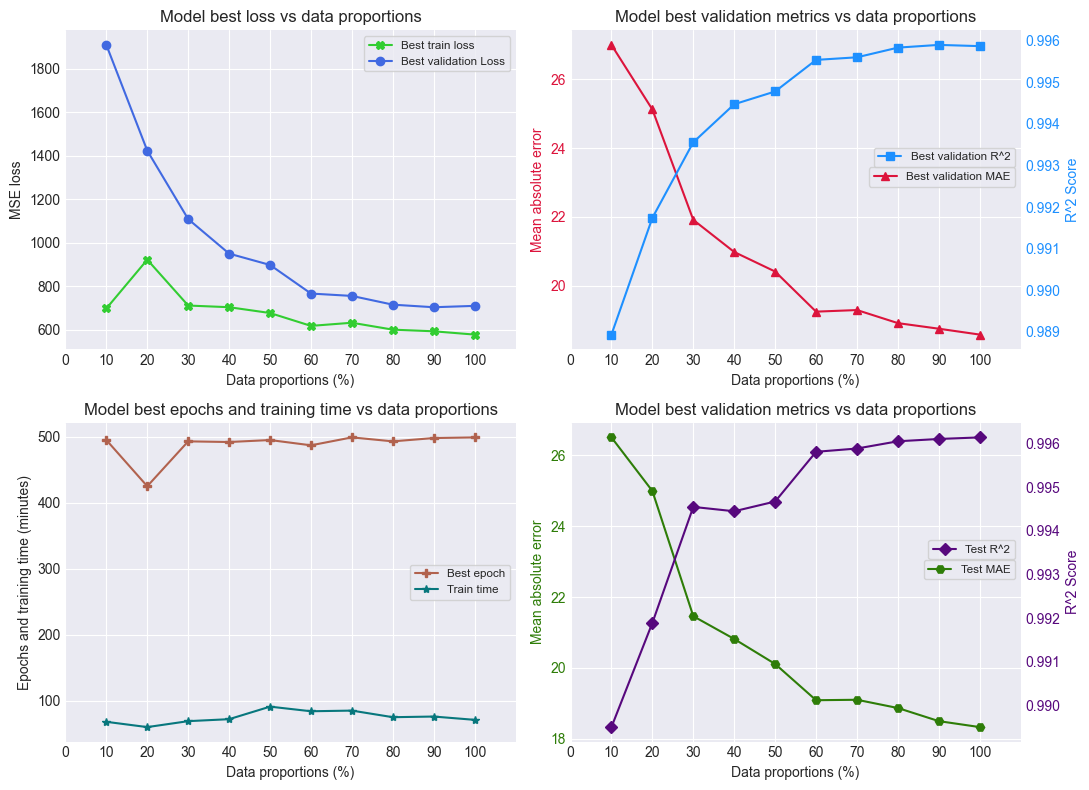

╭─────────────┬──────────────┬────────────┬──────────────┬──────────────┬───────────┬────────────┬───────────┬────────────╮
│   Propotion │   Train loss │   Val loss │   Best epoch │   Train time │   Val MAE │   Test MAE │   Val R2S │   Test R2S │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          10 │     698.3100 │  1908.7536 │          495 │           68 │   26.9906 │    26.5112 │    0.9889 │     0.9895 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          20 │     922.3866 │  1423.0682 │          425 │           60 │   25.1177 │    24.9965 │    0.9917 │     0.9919 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          30 │     711.8223 │  1108.7131 │          493 │           69 │   21.9149 │    21.4573 │    0.9936 │     0.9945 │
├───────

In [139]:
dProp_ModelLoss_MAE_R2S_epoch_timePlot(dProp_M3best_trainLoss, dProp_M3best_valLoss, dProp_M3best_valMAE, 
                                       dProp_M3best_valR2S, dProp_M3_testMAE, dProp_M3_testR2S, dProp_M3best_epoch,
                                       dProp_M3_trainTime)

### Model 4: TL Standard Fine Tune model

#### Creating the model architecture

In [140]:
# Loading the base model architecture and hyperparameters
with open("SimPTrain_bModel_arch.json", 'r') as infile:
    preTrainLoad_modelInfo = json.load(infile)

# Defining the base model hyperparameters for the standard fine tuned model
inputDimension = preTrainLoad_modelInfo["inputDimension"]
hiddenDimension = preTrainLoad_modelInfo["hiddenDimension"]
outputDimension = preTrainLoad_modelInfo["outputDimension"]
activationFunction = F.relu if preTrainLoad_modelInfo["activationFunction"]=="relu" else None
learnRate = preTrainLoad_modelInfo["learnRate"]
weightDecay = preTrainLoad_modelInfo["weightDecay"]
# Reduce the learning rate by factor of 10 (common approach, other values can be experimented)
tune_learnRate = learnRate * 1e-1
# Defining the lower layers
id_lowerLayers = [0]
# Defining the new upper layer indices to be created
id_upperLayers = [1, 2, 3, 4]

# Creating the standard fine tuned model
dProp_TL_stdFTuneModel4_untrain = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)

# Loading the base model weights into the standard fine tuned model
dProp_TL_stdFTuneModel4_untrain.load_state_dict(torch.load("SimPTrain_bModel_weight_bias.pth"))

<All keys matched successfully>

In [141]:
# The untrained model is set with base layers and re-initalized upper layers
# PyTorch models are passed by reference
RplcInitLayer_FineTune(dProp_TL_stdFTuneModel4_untrain, id_upperLayers)

# Loss function
criterion = nn.MSELoss()
# Optimizer (keeping the control model learning rate of 1e-2 for upper layers and fine tuned learning rate of
#            1e-3 for lower pre-trained layers)
optimizer = optimLayer_learnRate(dProp_TL_stdFTuneModel4_untrain, id_lowerLayers, tune_learnRate, learnRate)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(dProp_TL_stdFTuneModel4_untrain)
print(summary(dProp_TL_stdFTuneModel4_untrain, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         True
├─ModuleList: 1-1                        --              --              --                   --         True
│    └─Linear: 2-1                       [32, 21]        [32, 35]        770              26.88%         True
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29%      

In [142]:
# Store results for each data proportion
dProp_M4_trainTime = []
dProp_M4best_epoch = []
dProp_M4best_trainLoss = []
dProp_M4best_valLoss = []
dProp_M4best_valMAE = []
dProp_M4best_valR2S = []
dProp_M4_testMAE = []
dProp_M4_testR2S = []

for propPerc in actProp_sizeList:
    print('='*48, f'[Dataset Proportion: {int(round(propPerc*100,2))}%]', '='*48)
    # Copy the untrained model weights to the model to be trained 
    # By using deepcopy we reset the learned weights and biases of the trained model with the untrained model for every proportion
    dProp_TL_stdFTuneModel4_train = copy.deepcopy(dProp_TL_stdFTuneModel4_untrain)
    dProp_TL_stdFTuneModel4_train = dProp_TL_stdFTuneModel4_train.to(device)
    # To reset the optimizer
    optimizer = optimLayer_learnRate(dProp_TL_stdFTuneModel4_train, id_lowerLayers, tune_learnRate, learnRate)
    # Adjusted batch size for each proportion
    dProp_trainBatchSize = int(trainBatchSize * propPerc)
    # Train data loader for each proportion
    ActTrain_dPropLoad = dprop_trainLoad(ActTrain_torchSet, propPerc, dProp_trainBatchSize)
    
    # Move the model to GPU
    dProp_TL_stdFTuneModel4_train = dProp_TL_stdFTuneModel4_train.to(device)
    # To train the model
    propM4_trainTime, dProp_TL_stdFTuneModel4_train, propM4_bestStat, _ = train_NNRegModel(
         dProp_TL_stdFTuneModel4_train, 
         ActTrain_dPropLoad, 
         ActVal_dPropLoad,
         optimizer, 
         criterion, 
         device, 
         epochs=500, 
         patience=20
    )

    # Store the train results for each proportion
    dProp_M4_trainTime.append(propM4_trainTime)
    dProp_M4best_epoch.append(propM4_bestStat["Model_best epoch"])
    dProp_M4best_trainLoss.append(propM4_bestStat["Model_best train loss"])
    dProp_M4best_valLoss.append(propM4_bestStat["Model_best val loss"])
    dProp_M4best_valMAE.append(propM4_bestStat["Model_best val MAE"])
    dProp_M4best_valR2S.append(propM4_bestStat["Model_best val R2S"])  
    # Run predictions on model for each proportion
    dProp_TL_stdFTuneModel4_train = dProp_TL_stdFTuneModel4_train.to(device)
    _, _, propM4_testMAE, propM4_testR2S = predict_NNRegModel(dProp_TL_stdFTuneModel4_train, ActTest_dPropLoad, device)
    # Store the prediction results for each proportion
    dProp_M4_testMAE.append(propM4_testMAE)
    dProp_M4_testR2S.append(propM4_testR2S)
    print()

================================================ [Dataset Proportion: 10%] ================================================
Epoch [1/500] ==> Train Loss: 192759.3684, Validation Loss: 26490.4721, Validation MAE: 107.0855, Validation R^2: 0.8461

Epoch [20/500] ==> Train Loss: 3790.2971, Validation Loss: 5505.0476, Validation MAE: 52.9352, Validation R^2: 0.9680
Epoch [40/500] ==> Train Loss: 2410.7068, Validation Loss: 4294.5395, Validation MAE: 46.9846, Validation R^2: 0.9750
Epoch [60/500] ==> Train Loss: 1870.8910, Validation Loss: 3211.2168, Validation MAE: 36.7346, Validation R^2: 0.9813
Epoch [80/500] ==> Train Loss: 1589.6972, Validation Loss: 2689.5316, Validation MAE: 31.6640, Validation R^2: 0.9844
Epoch [100/500] ==> Train Loss: 1367.0689, Validation Loss: 2805.5209, Validation MAE: 31.4818, Validation R^2: 0.9837

Epoch [120/500] ==> Train Loss: 1202.8632, Validation Loss: 2810.0893, Validation MAE: 31.4272, Validation R^2: 0.9837
Epoch [140/500] ==> Train Loss: 1133.0435, 

Epoch [1/500] ==> Train Loss: 169138.9011, Validation Loss: 14689.0018, Validation MAE: 83.1991, Validation R^2: 0.9147

Epoch [20/500] ==> Train Loss: 2624.8972, Validation Loss: 2678.2825, Validation MAE: 34.3051, Validation R^2: 0.9844
Epoch [40/500] ==> Train Loss: 1720.9935, Validation Loss: 2104.3296, Validation MAE: 30.8662, Validation R^2: 0.9878
Epoch [60/500] ==> Train Loss: 1388.4165, Validation Loss: 1500.6102, Validation MAE: 26.0405, Validation R^2: 0.9913
Epoch [80/500] ==> Train Loss: 1184.0221, Validation Loss: 1332.4607, Validation MAE: 24.6743, Validation R^2: 0.9923
Epoch [100/500] ==> Train Loss: 1074.6600, Validation Loss: 1222.9294, Validation MAE: 23.8021, Validation R^2: 0.9929

Epoch [120/500] ==> Train Loss: 972.6273, Validation Loss: 1192.5680, Validation MAE: 23.7655, Validation R^2: 0.9931
Epoch [140/500] ==> Train Loss: 895.6900, Validation Loss: 1071.9399, Validation MAE: 22.4254, Validation R^2: 0.9938
Epoch [160/500] ==> Train Loss: 848.3862, Validatio

Epoch [20/500] ==> Train Loss: 2216.9081, Validation Loss: 2439.6724, Validation MAE: 32.1539, Validation R^2: 0.9858
Epoch [40/500] ==> Train Loss: 1514.6590, Validation Loss: 1662.2183, Validation MAE: 27.7298, Validation R^2: 0.9903
Epoch [60/500] ==> Train Loss: 1195.1979, Validation Loss: 1375.3862, Validation MAE: 26.5824, Validation R^2: 0.9920
Epoch [80/500] ==> Train Loss: 1041.7257, Validation Loss: 1156.8334, Validation MAE: 23.9673, Validation R^2: 0.9933
Epoch [100/500] ==> Train Loss: 947.2742, Validation Loss: 1016.6601, Validation MAE: 22.8054, Validation R^2: 0.9941

Epoch [120/500] ==> Train Loss: 857.3155, Validation Loss: 937.0755, Validation MAE: 21.4871, Validation R^2: 0.9946
Epoch [140/500] ==> Train Loss: 788.5538, Validation Loss: 891.7224, Validation MAE: 21.2609, Validation R^2: 0.9948
Epoch [160/500] ==> Train Loss: 745.7064, Validation Loss: 878.0871, Validation MAE: 21.3351, Validation R^2: 0.9949
Epoch [180/500] ==> Train Loss: 701.2738, Validation Loss:

#### Visualizing the standard fine tune model performances for the data proportions

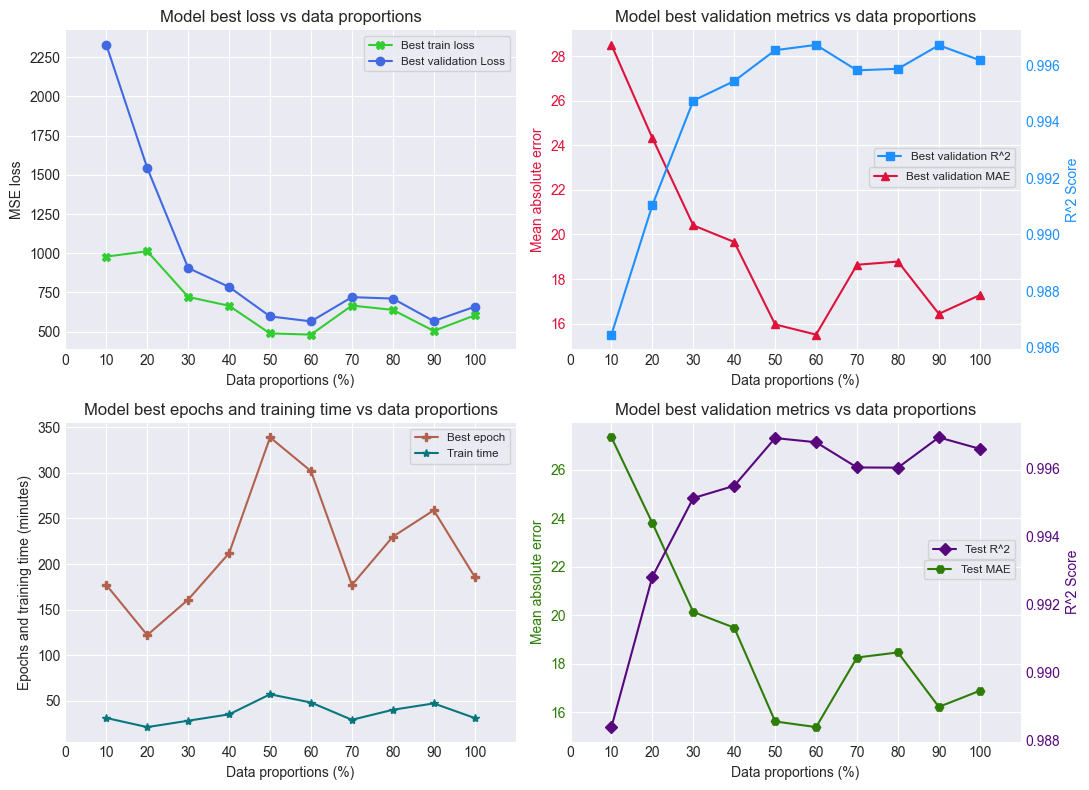

╭─────────────┬──────────────┬────────────┬──────────────┬──────────────┬───────────┬────────────┬───────────┬────────────╮
│   Propotion │   Train loss │   Val loss │   Best epoch │   Train time │   Val MAE │   Test MAE │   Val R2S │   Test R2S │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          10 │     978.8320 │  2328.5943 │          177 │           31 │   28.5165 │    27.3230 │    0.9865 │     0.9884 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          20 │    1012.9213 │  1543.7507 │          122 │           21 │   24.3330 │    23.7973 │    0.9910 │     0.9928 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          30 │     721.7931 │   905.9460 │          161 │           28 │   20.4101 │    20.1359 │    0.9947 │     0.9951 │
├───────

In [143]:
dProp_ModelLoss_MAE_R2S_epoch_timePlot(dProp_M4best_trainLoss, dProp_M4best_valLoss, dProp_M4best_valMAE, 
                                       dProp_M4best_valR2S, dProp_M4_testMAE, dProp_M4_testR2S, dProp_M4best_epoch,
                                       dProp_M4_trainTime)

### Model 5: TL Frozen Start Fine Tune model

#### Creating the model architecture

In [144]:
# Loading the base model architecture and hyperparameters
with open("SimPTrain_bModel_arch.json", 'r') as infile:
    preTrainLoad_modelInfo = json.load(infile)

# Defining the base model hyperparameters for the frozen start fine tuned model
inputDimension = preTrainLoad_modelInfo["inputDimension"]
hiddenDimension = preTrainLoad_modelInfo["hiddenDimension"]
outputDimension = preTrainLoad_modelInfo["outputDimension"]
activationFunction = F.relu if preTrainLoad_modelInfo["activationFunction"]=="relu" else None
learnRate = preTrainLoad_modelInfo["learnRate"]
# Reduce the learning rate by factor of 10 (common approach, other values can be experimented)
tune_learnRate = learnRate * 1e-1
weightDecay = preTrainLoad_modelInfo["weightDecay"]
# Defining the lower layers
id_lowerLayers = [0]
# Defining the new upper layer indices to be created
id_upperLayers = [1, 2, 3, 4]

# Creating the frozen start fine tuned model
dProp_TL_frzFTuneModel5_untrain = ANN_MultiReg(inputDimension, outputDimension, hiddenDimension, activationFunction).to(device)

# Loading the base model weights into the frozen start fine tuned model
dProp_TL_frzFTuneModel5_untrain.load_state_dict(torch.load("SimPTrain_bModel_weight_bias.pth"))

<All keys matched successfully>

In [145]:
# PyTorch models are passed by reference
frzRplcInitLayer_FineTune(dProp_TL_frzFTuneModel5_untrain, id_lowerLayers, id_upperLayers)

# Loss function
criterion = nn.MSELoss()
# Optimizer (keeping the same control model learning rate of 1e-2)
optimizer = torch.optim.Adam(dProp_TL_frzFTuneModel5_untrain.parameters(), lr = learnRate, weight_decay = weightDecay)
# Performance metrics: MAE and R^2

# Viewing a summary of the model created
print(dProp_TL_frzFTuneModel5_untrain)
print(summary(dProp_TL_frzFTuneModel5_untrain, input_size=(trainBatchSize, Xact_trainTensor.size(1)), col_names=["input_size", "output_size", "num_params", "params_percent", "trainable"], col_width=15, device=device))

ANN_MultiReg(
  (layers): ModuleList(
    (0): Linear(in_features=21, out_features=35, bias=True)
    (1): Linear(in_features=35, out_features=28, bias=True)
    (2): Linear(in_features=28, out_features=24, bias=True)
    (3): Linear(in_features=24, out_features=15, bias=True)
    (4): Linear(in_features=15, out_features=1, bias=True)
  )
)
Layer (type:depth-idx)                   Input Shape     Output Shape    Param #         Param %         Trainable
ANN_MultiReg                             [32, 21]        [32, 1]         --                   --         Partial
├─ModuleList: 1-1                        --              --              --                   --         Partial
│    └─Linear: 2-1                       [32, 21]        [32, 35]        (770)            26.88%         False
│    └─Linear: 2-2                       [32, 35]        [32, 28]        1,008            35.18%         True
│    └─Linear: 2-3                       [32, 28]        [32, 24]        696              24.29

In [146]:
# Store results for each data proportion
dProp_M5_trainTime = []
dProp_M5best_epoch = []
dProp_M5best_trainLoss = []
dProp_M5best_valLoss = []
dProp_M5best_valMAE = []
dProp_M5best_valR2S = []
dProp_M5_testMAE = []
dProp_M5_testR2S = []

for propPerc in actProp_sizeList:
    print('='*48, f'[Dataset Proportion: {int(round(propPerc*100,2))}%]', '='*48)
    # Copy the untrained model weights to the model to be trained 
    # By using deepcopy we reset the learned weights and biases of the trained model with the untrained model for every proportion
    dProp_TL_frzFTuneModel5_train = copy.deepcopy(dProp_TL_frzFTuneModel5_untrain)
    dProp_TL_frzFTuneModel5_train = dProp_TL_frzFTuneModel5_train.to(device)
    # To reset the optimizer
    optimizer = torch.optim.Adam(dProp_TL_frzFTuneModel5_train.parameters(), lr = learnRate, weight_decay = weightDecay)
    # Adjusted batch size for each proportion
    dProp_trainBatchSize = int(trainBatchSize * propPerc)
    # Train data loader for each proportion
    ActTrain_dPropLoad = dprop_trainLoad(ActTrain_torchSet, propPerc, dProp_trainBatchSize)
    
    # Move the model to GPU
    dProp_TL_frzFTuneModel5_train = dProp_TL_frzFTuneModel5_train.to(device)
    dProp_phase1_savePTH = 'Model_Checkpoints/M5_ph1_dProp_checkPT.pth'
    # To train the model
    print('[' + '-'*52, "Phase 1 training", '-'*52 + ']')
    propM5_ph1trainTime, dProp_TL_frzFTuneModel5_train, propM5_ph1bestStat, _ = train_NNRegModel(
         dProp_TL_frzFTuneModel5_train, 
         ActTrain_dPropLoad, 
         ActVal_dPropLoad, 
         optimizer, 
         criterion, 
         device, 
         epochs=500, 
         patience=10,
         epoch_StartPT=0,
         checkPT_savePTH=dProp_phase1_savePTH
    )
    
    # Setting all the layers of the model as trainable
    for layer in dProp_TL_frzFTuneModel5_train.layers:
        for param_WB in layer.parameters():
            param_WB.requires_grad = True
    # Same criterion (MSE loss) and performance metrics (MSE and R^2)
    # The optimizer for phase 2 will be set from the phase 1 best checkpoint
    # Move the model to GPU
    dProp_TL_frzFTuneModel5_train = dProp_TL_frzFTuneModel5_train.to(device)
    dProp_phase2_loadPTH = 'Model_Checkpoints/M5_ph1_dProp_checkPT.pth'
    # To train the model
    print('\n[' + '-'*52, "Phase 2 training", '-'*52 + ']')
    propM5_trainTime, dProp_TL_frzFTuneModel5_train, propM5_bestStat, _ = train_NNRegModel(
         dProp_TL_frzFTuneModel5_train, 
         ActTrain_dPropLoad, 
         ActVal_dPropLoad, 
         optimizer, 
         criterion, 
         device, 
         epochs=500, 
         patience=20,
         epoch_StartPT=propM5_ph1bestStat['Model_best epoch'],
         checkPT_savePTH=None,
         checkPT_loadPTH=dProp_phase2_loadPTH,
         ph2_learnRate=tune_learnRate
    )
    
    # Store the train results for each proportion
    dProp_M5_trainTime.append(propM5_ph1trainTime + propM5_trainTime)
    dProp_M5best_epoch.append(propM5_bestStat["Model_best epoch"])
    dProp_M5best_trainLoss.append(propM5_bestStat["Model_best train loss"])
    dProp_M5best_valLoss.append(propM5_bestStat["Model_best val loss"])
    dProp_M5best_valMAE.append(propM5_bestStat["Model_best val MAE"])
    dProp_M5best_valR2S.append(propM5_bestStat["Model_best val R2S"])  
    # Run predictions on model for each proportion
    dProp_TL_frzFTuneModel5_train = dProp_TL_frzFTuneModel5_train.to(device)
    _, _, propM5_testMAE, propM5_testR2S = predict_NNRegModel(dProp_TL_frzFTuneModel5_train, ActTest_dPropLoad, device)
    # Store the prediction results for each proportion
    dProp_M5_testMAE.append(propM5_testMAE)
    dProp_M5_testR2S.append(propM5_testR2S)
    print()

================================================ [Dataset Proportion: 10%] ================================================
[---------------------------------------------------- Phase 1 training ----------------------------------------------------]
Epoch [1/500] ==> Train Loss: 201696.5831, Validation Loss: 34519.1437, Validation MAE: 129.5132, Validation R^2: 0.7995

Epoch [20/500] ==> Train Loss: 9064.0640, Validation Loss: 11212.1726, Validation MAE: 74.3529, Validation R^2: 0.9349
Epoch [40/500] ==> Train Loss: 6769.3462, Validation Loss: 8007.0662, Validation MAE: 62.2289, Validation R^2: 0.9534
Epoch [60/500] ==> Train Loss: 5288.2587, Validation Loss: 6496.9173, Validation MAE: 55.8589, Validation R^2: 0.9622

Early stopping triggered. Training halted.

Training completed in 7 minutes and 32 seconds.
--------------------------------------------------------------------------------------------------------------------------
Best epoch: 53 || Best train loss: 5774.8071 || Best val l

Epoch [60/500] ==> Train Loss: 3615.3873, Validation Loss: 4160.8868, Validation MAE: 44.4317, Validation R^2: 0.9758
Epoch [80/500] ==> Train Loss: 3014.5850, Validation Loss: 4043.1024, Validation MAE: 44.2249, Validation R^2: 0.9765
Epoch [100/500] ==> Train Loss: 2725.5894, Validation Loss: 3358.9860, Validation MAE: 39.3366, Validation R^2: 0.9805

Epoch [120/500] ==> Train Loss: 2459.1740, Validation Loss: 3067.5470, Validation MAE: 38.2822, Validation R^2: 0.9821
Epoch [140/500] ==> Train Loss: 2158.6552, Validation Loss: 3214.2719, Validation MAE: 39.3006, Validation R^2: 0.9813

Early stopping triggered. Training halted.

Training completed in 19 minutes and 15 seconds.
--------------------------------------------------------------------------------------------------------------------------
Best epoch: 146 || Best train loss: 2151.6827 || Best val loss: 2756.1445 || Best val MAE: 34.5037 || Best val R^2: 0.9839
------------------------------------------------------------------

Epoch [120/500] ==> Train Loss: 2624.3685, Validation Loss: 2917.9026, Validation MAE: 36.5348, Validation R^2: 0.9830
Epoch [140/500] ==> Train Loss: 2382.4374, Validation Loss: 2810.8079, Validation MAE: 36.2839, Validation R^2: 0.9837
Epoch [160/500] ==> Train Loss: 2126.4257, Validation Loss: 2964.4886, Validation MAE: 37.7845, Validation R^2: 0.9828

Early stopping triggered. Training halted.

Training completed in 21 minutes and 20 seconds.
--------------------------------------------------------------------------------------------------------------------------
Best epoch: 167 || Best train loss: 2074.2926 || Best val loss: 2372.0347 || Best val MAE: 32.6360 || Best val R^2: 0.9862
--------------------------------------------------------------------------------------------------------------------------

[---------------------------------------------------- Phase 2 training ----------------------------------------------------]
Epoch [167/500] ==> Train Loss: 1643.9450, Validation 

Epoch [1/500] ==> Train Loss: 160832.2474, Validation Loss: 22975.9563, Validation MAE: 105.9240, Validation R^2: 0.8667

Epoch [20/500] ==> Train Loss: 5876.0327, Validation Loss: 5860.3679, Validation MAE: 54.2361, Validation R^2: 0.9659
Epoch [40/500] ==> Train Loss: 4474.2031, Validation Loss: 4769.8205, Validation MAE: 48.3535, Validation R^2: 0.9723
Epoch [60/500] ==> Train Loss: 3766.6925, Validation Loss: 4052.3742, Validation MAE: 44.1793, Validation R^2: 0.9764
Epoch [80/500] ==> Train Loss: 3226.4130, Validation Loss: 3800.6476, Validation MAE: 43.4441, Validation R^2: 0.9779

Early stopping triggered. Training halted.

Training completed in 10 minutes and 47 seconds.
--------------------------------------------------------------------------------------------------------------------------
Best epoch: 77 || Best train loss: 3348.7285 || Best val loss: 3528.7659 || Best val MAE: 40.8262 || Best val R^2: 0.9795
-------------------------------------------------------------------

Epoch [440/500] ==> Train Loss: 574.6189, Validation Loss: 752.5186, Validation MAE: 18.8613, Validation R^2: 0.9956
Epoch [460/500] ==> Train Loss: 563.3369, Validation Loss: 759.8266, Validation MAE: 18.8436, Validation R^2: 0.9956
Epoch [480/500] ==> Train Loss: 551.9599, Validation Loss: 713.7352, Validation MAE: 18.2153, Validation R^2: 0.9959
Epoch [500/500] ==> Train Loss: 543.8146, Validation Loss: 708.0955, Validation MAE: 18.1999, Validation R^2: 0.9959


Training completed in 54 minutes and 22 seconds.
--------------------------------------------------------------------------------------------------------------------------
Best epoch: 499 || Best train loss: 543.7602 || Best val loss: 699.5323 || Best val MAE: 18.1138 || Best val R^2: 0.9959
--------------------------------------------------------------------------------------------------------------------------
Prediction completed in 0.12 seconds.
----------------------------------------------------------------------------

Epoch [180/500] ==> Train Loss: 1225.9041, Validation Loss: 1377.7372, Validation MAE: 25.6360, Validation R^2: 0.9920
Epoch [200/500] ==> Train Loss: 1059.4140, Validation Loss: 1216.4835, Validation MAE: 24.2148, Validation R^2: 0.9929

Epoch [220/500] ==> Train Loss: 940.7066, Validation Loss: 1094.7602, Validation MAE: 22.9523, Validation R^2: 0.9936
Epoch [240/500] ==> Train Loss: 866.7378, Validation Loss: 1049.7380, Validation MAE: 22.7228, Validation R^2: 0.9939
Epoch [260/500] ==> Train Loss: 807.5207, Validation Loss: 984.7519, Validation MAE: 21.9224, Validation R^2: 0.9943
Epoch [280/500] ==> Train Loss: 761.7164, Validation Loss: 906.7057, Validation MAE: 21.0248, Validation R^2: 0.9947
Epoch [300/500] ==> Train Loss: 720.6950, Validation Loss: 855.2498, Validation MAE: 20.4559, Validation R^2: 0.9950

Epoch [320/500] ==> Train Loss: 685.8975, Validation Loss: 816.0238, Validation MAE: 19.9528, Validation R^2: 0.9953
Epoch [340/500] ==> Train Loss: 657.5114, Validation Los

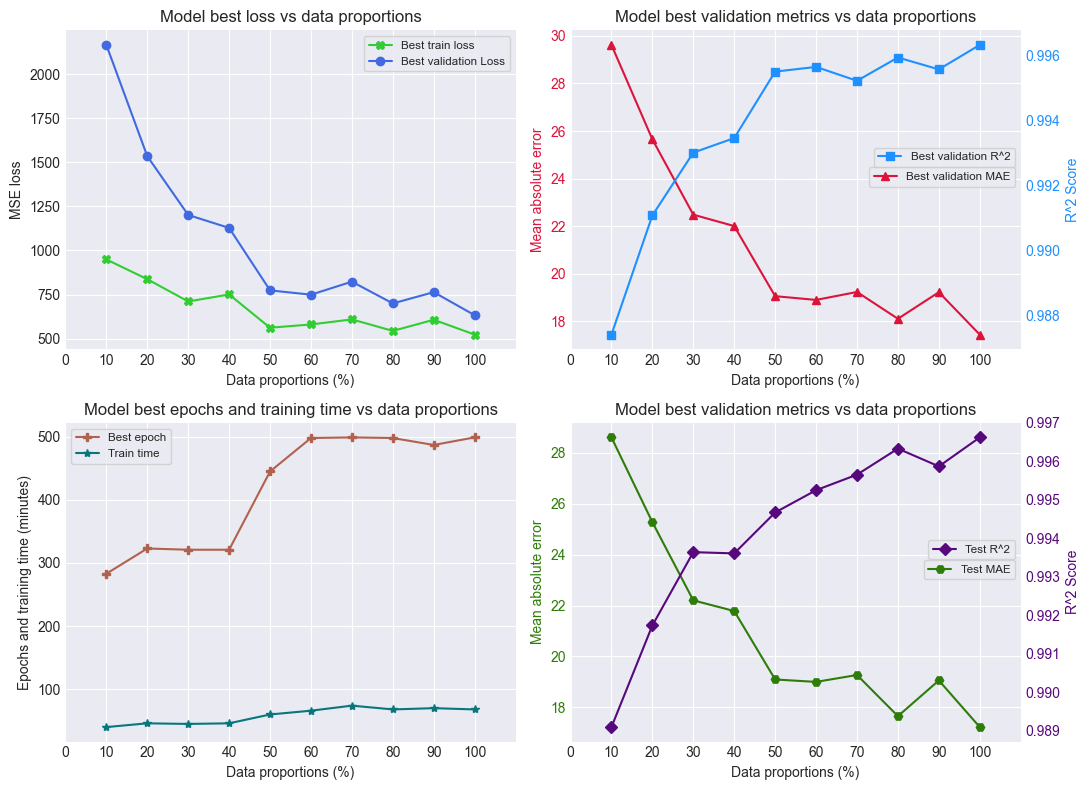

╭─────────────┬──────────────┬────────────┬──────────────┬──────────────┬───────────┬────────────┬───────────┬────────────╮
│   Propotion │   Train loss │   Val loss │   Best epoch │   Train time │   Val MAE │   Test MAE │   Val R2S │   Test R2S │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          10 │     948.8787 │  2165.4505 │          283 │           40 │   29.6218 │    28.5977 │    0.9874 │     0.9891 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          20 │     836.9953 │  1534.4916 │          323 │           46 │   25.6534 │    25.2705 │    0.9911 │     0.9917 │
├─────────────┼──────────────┼────────────┼──────────────┼──────────────┼───────────┼────────────┼───────────┼────────────┤
│          30 │     710.6674 │  1201.0434 │          321 │           45 │   22.4874 │    22.2020 │    0.9930 │     0.9936 │
├───────

In [147]:
dProp_ModelLoss_MAE_R2S_epoch_timePlot(dProp_M5best_trainLoss, dProp_M5best_valLoss, dProp_M5best_valMAE, 
                                       dProp_M5best_valR2S, dProp_M5_testMAE, dProp_M5_testR2S, dProp_M5best_epoch,
                                       dProp_M5_trainTime)

### Model benchmarking

#### Best train and validation losses vs data proportions

In [154]:
def benchMK_Metric_Line_dProp(M1_perfMetric_dPropL, M2_perfMetric_dPropL, M3_perfMetric_dPropL, M4_perfMetric_dPropL, M5_perfMetric_dPropL, 
                              M1_perfMetric_dPropR, M2_perfMetric_dPropR, M3_perfMetric_dPropR, M4_perfMetric_dPropR, M5_perfMetric_dPropR,
                              metricL, metricR):
    
    actProp_sizeList_perc = [prop * 100 for prop in actProp_sizeList]
    fig = plt.figure(figsize=(11,4))
    ax1 = fig.add_subplot(121)
    M1_col = '#7D1C08'
    M1_mkCol = '#D22F0D'
    M1_mk = 'o'
    
    M2_col = '#CC8822'
    M2_mkCol = '#FFBE55'
    M2_mk = 'X'    
    
    M3_col = '#56087D'
    M3_mkCol = '#900DD2'
    M3_mk = '^'
    
    M4_col = '#2E7D08'
    M4_mkCol = '#4DD20D'
    M4_mk = 'D'
    
    M5_col = '#08697D'
    M5_mkCol = '#0DB0D2'
    M5_mk = 'P'
    
    # Metrics vs data proportions
    ax1.plot(actProp_sizeList_perc, M1_perfMetric_dPropL, color=M1_col, label="M1 Control", marker=M1_mk, ms=6, mfc=M1_mkCol)
    ax1.plot(actProp_sizeList_perc, M2_perfMetric_dPropL, color=M2_col, label="M2 Frozen", marker=M2_mk, ms=6, mfc=M2_mkCol)
    ax1.plot(actProp_sizeList_perc, M3_perfMetric_dPropL, color=M3_col, label="M3 Soft Start", marker=M3_mk, ms=6, mfc=M3_mkCol)
    ax1.plot(actProp_sizeList_perc, M4_perfMetric_dPropL, color=M4_col, label="M4 Standard Fine Tune", marker=M4_mk, ms=6, mfc=M4_mkCol)
    ax1.plot(actProp_sizeList_perc, M5_perfMetric_dPropL, color=M5_col, label="M5 Frozen Start Fine Tune", marker=M5_mk, ms=6, mfc=M5_mkCol)
    if metricL=="train loss":
        ax1.set_title("Best train losses vs data proportions")
        ax1.set_ylabel("Train loss")
        dictL_str = "train loss"
    elif metricL=="val MAE":
        ax1.set_title("Best validation MAE vs data proportions")
        ax1.set_ylabel("Mean absolute error")
        dictL_str = "val MAE"
    elif metricL=="epoch":
        ax1.set_title("Best epochs vs data proportions")
        ax1.set_ylabel("Epochs")
        dictL_str = "epoch"
    elif metricL=="test MAE":
        ax1.set_title("Test MAE vs data proportions")
        ax1.set_ylabel("Mean absolute error")
        dictL_str = "test MAE"
    else:
        ax1.set_title("")
        ax1.set_ylabel("")
        dictL_str = "metric"
    ax1.set_xlabel("Data proportions (%)")
    ax1.set_xlim(0, 110)
    ax1.set_xticks(range(0, 110, 10))
    ax1.legend(frameon=True, fontsize='x-small')
    
    ax2 = fig.add_subplot(122)
    if metricR=="val loss":
        ax2.set_title("Best validation losses vs data proportions")
        ax2.set_ylabel("Validation loss")
        dictR_str = "val loss"
    elif metricR=="val R2S":
        ax2.set_title("Best validation R^2 vs data proportions")
        ax2.set_ylabel("R^2 score")
        dictR_str = "val R^2"
    elif metricR=="train time":
        M1_perfMetric_dPropR = [int(minute//60) for minute in M1_perfMetric_dPropR]
        M2_perfMetric_dPropR = [int(minute//60) for minute in M2_perfMetric_dPropR]
        M3_perfMetric_dPropR = [int(minute//60) for minute in M3_perfMetric_dPropR]
        M4_perfMetric_dPropR = [int(minute//60) for minute in M4_perfMetric_dPropR]
        M5_perfMetric_dPropR = [int(minute//60) for minute in M5_perfMetric_dPropR]
        ax2.set_title("Best training times vs data proportions")
        ax2.set_ylabel("Training time (minutes)")
        dictR_str = "train time"
    elif metricR=="test R2S":
        ax2.set_title("Test R^2 vs data proportions")
        ax2.set_ylabel("R^2 score")
        dictR_str = "test R^2"
    else:
        ax2.set_title("")
        ax2.set_ylabel("")
        dictR_str = "metric"
    
    ax2.plot(actProp_sizeList_perc, M1_perfMetric_dPropR, color=M1_col, label="M1 Control", marker=M1_mk, ms=6, mfc=M1_mkCol)
    ax2.plot(actProp_sizeList_perc, M2_perfMetric_dPropR, color=M2_col, label="M2 Frozen", marker=M2_mk, ms=6, mfc=M2_mkCol)
    ax2.plot(actProp_sizeList_perc, M3_perfMetric_dPropR, color=M3_col, label="M3 Soft Start", marker=M3_mk, ms=6, mfc=M3_mkCol)
    ax2.plot(actProp_sizeList_perc, M4_perfMetric_dPropR, color=M4_col, label="M4 Standard Fine Tune", marker=M4_mk, ms=6, mfc=M4_mkCol)
    ax2.plot(actProp_sizeList_perc, M5_perfMetric_dPropR, color=M5_col, label="M5 Frozen Start Fine Tune", marker=M5_mk, ms=6, mfc=M5_mkCol)
    ax2.set_xlabel("Data proportions (%)")
    ax2.set_xlim(0, 110)
    ax2.set_xticks(range(0, 110, 10))
    ax2.legend(frameon=True, fontsize='x-small')
    
    plt.tight_layout()
    plt.show()
    
    propModel_benchMKDict_L = {
        "Propotion": actProp_sizeList_perc,
        "M1 " + dictL_str: M1_perfMetric_dPropL,
        "M2 " + dictL_str: M2_perfMetric_dPropL,
        "M3 " + dictL_str: M3_perfMetric_dPropL,
        "M4 " + dictL_str: M4_perfMetric_dPropL,
        "M5 " + dictL_str: M5_perfMetric_dPropL

    }
    print(tabulate(propModel_benchMKDict_L, headers='keys', tablefmt="rounded_grid", floatfmt=('.0f', '.4f', '.4f', '.4f',
                                                                                           '.4f', '.4f')))
    propModel_benchMKDict_R = {
        "Propotion": actProp_sizeList_perc,
        "M1 " + dictR_str: M1_perfMetric_dPropR,
        "M2 " + dictR_str: M2_perfMetric_dPropR,
        "M3 " + dictR_str: M3_perfMetric_dPropR,
        "M4 " + dictR_str: M4_perfMetric_dPropR,
        "M5 " + dictR_str: M5_perfMetric_dPropR

    }
    print()
    print(tabulate(propModel_benchMKDict_R, headers='keys', tablefmt="rounded_grid", floatfmt=('.0f', '.4f', '.4f', '.4f',
                                                                                           '.4f', '.4f')))
    return propModel_benchMKDict_L, propModel_benchMKDict_R

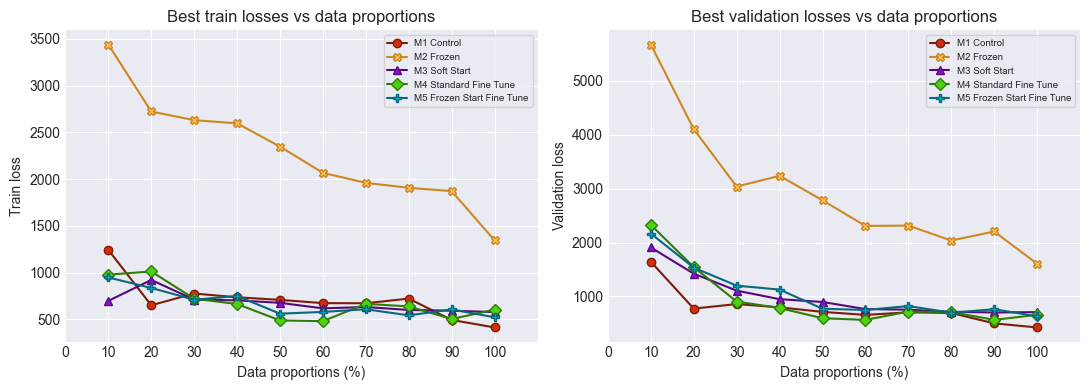

╭─────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────╮
│   Propotion │   M1 train loss │   M2 train loss │   M3 train loss │   M4 train loss │   M5 train loss │
├─────────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┤
│          10 │       1243.6973 │       3440.1458 │        698.3100 │        978.8320 │        948.8787 │
├─────────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┤
│          20 │        651.6573 │       2724.0922 │        922.3866 │       1012.9213 │        836.9953 │
├─────────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┤
│          30 │        777.1215 │       2631.3685 │        711.8223 │        721.7931 │        710.6674 │
├─────────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┼─────────────────┤
│          40 │        736.9100 │       2597.5

In [155]:
dPropDict_TrainLoss, dPropDict_ValLoss = benchMK_Metric_Line_dProp(dProp_M1best_trainLoss, dProp_M2best_trainLoss, dProp_M3best_trainLoss, dProp_M4best_trainLoss, dProp_M5best_trainLoss, 
                              dProp_M1best_valLoss, dProp_M2best_valLoss, dProp_M3best_valLoss, dProp_M4best_valLoss, dProp_M5best_valLoss,
                              "train loss", "val loss")

#### Best validation MAE and R^2 vs data proportions

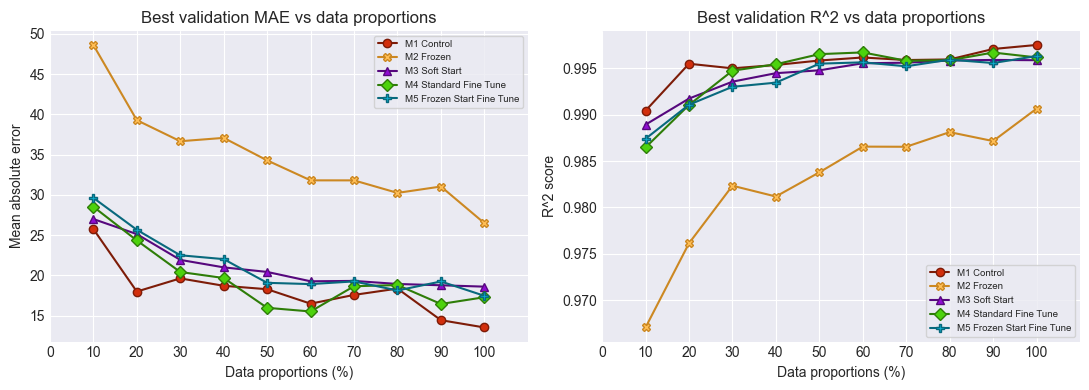

╭─────────────┬──────────────┬──────────────┬──────────────┬──────────────┬──────────────╮
│   Propotion │   M1 val MAE │   M2 val MAE │   M3 val MAE │   M4 val MAE │   M5 val MAE │
├─────────────┼──────────────┼──────────────┼──────────────┼──────────────┼──────────────┤
│          10 │      25.7467 │      48.6223 │      26.9906 │      28.5165 │      29.6218 │
├─────────────┼──────────────┼──────────────┼──────────────┼──────────────┼──────────────┤
│          20 │      17.9788 │      39.2754 │      25.1177 │      24.3330 │      25.6534 │
├─────────────┼──────────────┼──────────────┼──────────────┼──────────────┼──────────────┤
│          30 │      19.6141 │      36.6583 │      21.9149 │      20.4101 │      22.4874 │
├─────────────┼──────────────┼──────────────┼──────────────┼──────────────┼──────────────┤
│          40 │      18.6958 │      37.0752 │      20.9842 │      19.6620 │      22.0085 │
├─────────────┼──────────────┼──────────────┼──────────────┼──────────────┼──────────────┤

In [150]:
dPropDict_ValMAE, dPropDict_ValR2S = benchMK_Metric_Line_dProp(dProp_M1best_valMAE, dProp_M2best_valMAE, dProp_M3best_valMAE, dProp_M4best_valMAE, dProp_M5best_valMAE, 
                              dProp_M1best_valR2S, dProp_M2best_valR2S, dProp_M3best_valR2S, dProp_M4best_valR2S, dProp_M5best_valR2S,
                              "val MAE", "val R2S")

#### Best epochs and training times vs data proportions

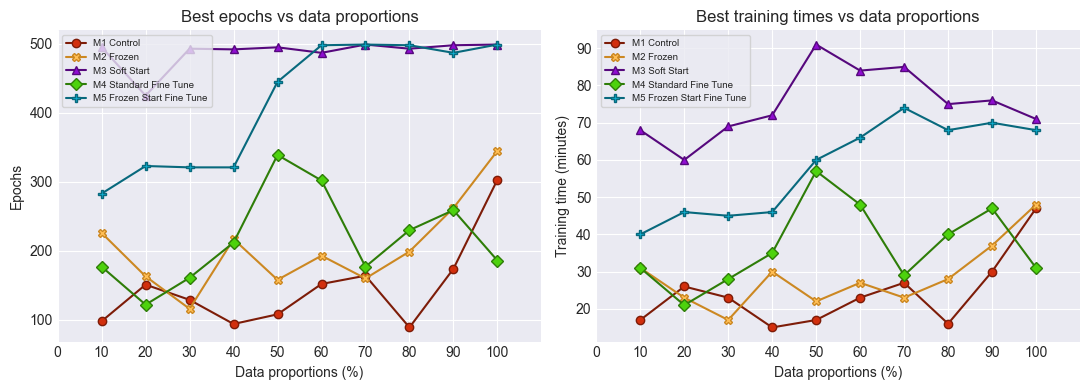

╭─────────────┬────────────┬────────────┬────────────┬────────────┬────────────╮
│   Propotion │   M1 epoch │   M2 epoch │   M3 epoch │   M4 epoch │   M5 epoch │
├─────────────┼────────────┼────────────┼────────────┼────────────┼────────────┤
│          10 │         98 │        226 │        495 │        177 │        283 │
├─────────────┼────────────┼────────────┼────────────┼────────────┼────────────┤
│          20 │        151 │        163 │        425 │        122 │        323 │
├─────────────┼────────────┼────────────┼────────────┼────────────┼────────────┤
│          30 │        129 │        116 │        493 │        161 │        321 │
├─────────────┼────────────┼────────────┼────────────┼────────────┼────────────┤
│          40 │         94 │        217 │        492 │        212 │        321 │
├─────────────┼────────────┼────────────┼────────────┼────────────┼────────────┤
│          50 │        108 │        158 │        495 │        339 │        445 │
├─────────────┼────────────┼

In [151]:
dPropDict_Epoch, dPropDict_TrainTime = benchMK_Metric_Line_dProp(dProp_M1best_epoch, dProp_M2best_epoch, dProp_M3best_epoch, dProp_M4best_epoch, dProp_M5best_epoch, 
                              dProp_M1_trainTime, dProp_M2_trainTime, dProp_M3_trainTime, dProp_M4_trainTime, dProp_M5_trainTime,
                              "epoch", "train time")

#### Test MAE and R^2 vs data proportions

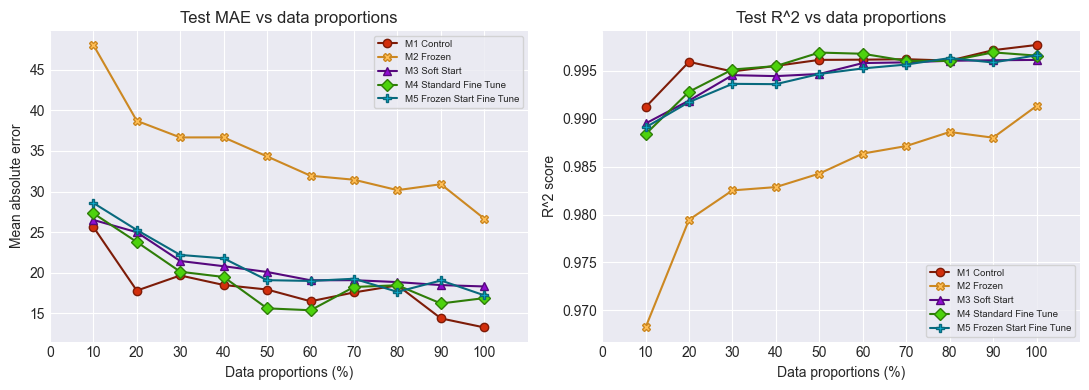

╭─────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────╮
│   Propotion │   M1 test MAE │   M2 test MAE │   M3 test MAE │   M4 test MAE │   M5 test MAE │
├─────────────┼───────────────┼───────────────┼───────────────┼───────────────┼───────────────┤
│          10 │       25.6434 │       48.0412 │       26.5112 │       27.3230 │       28.5977 │
├─────────────┼───────────────┼───────────────┼───────────────┼───────────────┼───────────────┤
│          20 │       17.8136 │       38.7039 │       24.9965 │       23.7973 │       25.2705 │
├─────────────┼───────────────┼───────────────┼───────────────┼───────────────┼───────────────┤
│          30 │       19.6761 │       36.6625 │       21.4573 │       20.1359 │       22.2020 │
├─────────────┼───────────────┼───────────────┼───────────────┼───────────────┼───────────────┤
│          40 │       18.5043 │       36.6686 │       20.8135 │       19.4894 │       21.7837 │
├─────────────┼───────────────┼─────────

In [152]:
dPropDict_TestMAE, dPropDict_TestR2S = benchMK_Metric_Line_dProp(dProp_M1_testMAE, dProp_M2_testMAE, dProp_M3_testMAE, dProp_M4_testMAE, dProp_M5_testMAE, 
                              dProp_M1_testR2S, dProp_M2_testR2S, dProp_M3_testR2S, dProp_M4_testR2S, dProp_M5_testR2S,
                              "test MAE", "test R2S")

In [153]:
dPropDF_TrainLoss = pd.DataFrame(dPropDict_TrainLoss)
dPropDF_ValLoss = pd.DataFrame(dPropDict_ValLoss)
dPropDF_ValMAE = pd.DataFrame(dPropDict_ValMAE)
dPropDF_ValR2S = pd.DataFrame(dPropDict_ValR2S)
dPropDF_Epoch = pd.DataFrame(dPropDict_Epoch)
dPropDF_TrainTime = pd.DataFrame(dPropDict_TrainTime)
dPropDF_TestMAE = pd.DataFrame(dPropDict_TestMAE)
dPropDF_TestR2S = pd.DataFrame(dPropDict_TestR2S)

with pd.ExcelWriter('TL_Production_tables/DataProp Model results.xlsx') as writer:
    df_DataProp.to_excel(writer, sheet_name='Prop Batch Size', index=False)
    dPropDF_TrainLoss.to_excel(writer, sheet_name='Train Loss', index=False)
    dPropDF_ValLoss.to_excel(writer, sheet_name='Val Loss', index=False)
    dPropDF_ValMAE.to_excel(writer, sheet_name='Val MAE', index=False)
    dPropDF_ValR2S.to_excel(writer, sheet_name='Val R^2', index=False)
    dPropDF_Epoch.to_excel(writer, sheet_name='Best Epoch', index=False)
    dPropDF_TrainTime.to_excel(writer, sheet_name='Train Time', index=False)
    dPropDF_TestMAE.to_excel(writer, sheet_name='Test MAE', index=False)
    dPropDF_TestR2S.to_excel(writer, sheet_name='Test R^2', index=False)